# Decomposing goal-directedness and directional precision in sensory-deprived echolocating bats during homing

This notebook revisits the free-flying bat homing data of A. Goldshtein et al., "Acoustic cognitive map–based navigation in echolocating bats," *Science* **386**(6721), 561-567 (2024); [doi:10.1126/science.adn6269](https://doi.org/10.1126/science.adn6269) - echolocating bats translocated over kilometer scales and tracked back to a known goal. The original study found that bats typically do home successfully even under sensory deprivation, consistent with echolocation being a sufficient and robust navigation modality. The question revisited here is whether that deprivation nonetheless produces detectable changes in **goal-relative orientation** (directional bias and/or directional precision).

Each flight is a GPS track recorded with an on-animal tag. We reduce each track to a sequence of
fixed-length movement **steps**, compute a heading per step, and express that heading **relative
to the instantaneous direction toward the animal's known destination** (its roost or the Agamon–Hula lake region). On this goal-relative scale, a step aimed straight at the goal is
near $0^\circ$ and a step heading away is near $\pm180^\circ$, so fitted von Mises parameters map
directly onto goal-directed travel.

**Why a mixture:** stepwise headings in these tracks are multimodal. A bat may wander before
committing to goal-directed travel, and the original study had to split trajectories into a
localization phase and a homing phase using *post-treatment* features (straightness,
distance-to-goal). Selecting on such features can entangle treatment effects with the selection
rule. To avoid that, the main analysis below fits a **von Mises--Uniform mixture (vMU)**: each step
is drawn either from a directed von Mises component (goal-directed "exploitation") or from an
undirected component (wandering "exploration"), with treatment and per-animal (tag) random
effects. This separates trajectory structure from treatment comparisons while using the **full**
trajectory, with no post-treatment filtering.

The notebook also fits a simpler **single von Mises treatment model** (brms) first, so the vMU
result can be read against a non-mixed baseline, and compares the two out-of-sample (PSIS-LOO
ELPD).


## Setup

Select the R (`ir`) kernel and follow the [R setup](../getting-started-r.md)
page for the environment and kernel prerequisites; the first code cell
checks the pinned packages and CmdStan and stops with a pointer there
if the one-time setup has not been run. Run the cells in order.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "circular", "readxl", "sf",
  "geosphere", "Matrix", "ggplot2", "ragg", "IRdisplay", "patchwork",
  "curl", "png")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
versions <- c(R = as.character(getRversion()),
  vapply(c("brms", "posterior", "loo", "circular", "readxl", "sf", "geosphere", "Matrix", "ggplot2", "ragg", "IRdisplay", "patchwork", "cmdstanr"),
    function(p) as.character(packageVersion(p)), character(1)))
versions


R          brms     posterior           loo      circular 
      "4.5.3"      "2.23.0"       "1.7.1" "2.10.1.9000"       "0.5.2" 
       readxl            sf     geosphere        Matrix       ggplot2 
      "1.6.0"       "1.1.3"       "1.6.8"       "1.7.6"       "4.0.3" 
         ragg     IRdisplay     patchwork      cmdstanr 
      "1.5.2"         "1.1"       "1.3.2"       "0.9.0"

In [3]:
suppressPackageStartupMessages({
  library(brms)
  library(posterior)
  library(loo)
  library(circular)
  library(readxl)
  library(sf)
  library(geosphere)
  library(Matrix)
  library(ggplot2)
  library(patchwork)
})


In [4]:
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) {
  ".."
} else if (file.exists(file.path("R", "unwrap_family.R"))) {
  "."
} else {
  stop("Run from notebooks_r/ or the repository root.")
}

source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))


Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



In [5]:
FIG_DIR <- file.path(repo_root, "figures", "goldshtein_bats")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
# Render PNGs for inline display; keep vector PDFs alongside them.

show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  # gtable objects (the individual PPC grid carries a hand-drawn
  # legend row) print via the grid engine rather than print();
  # a plain print leaves the device blank.
  if (inherits(plot, "gtable")) grid::grid.draw(plot) else print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}

theme_set(theme_minimal(base_size = 12))
save_figure <- function(plot, name, width = 8, height = 5) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot, width = width, height = height)
  show_figure(plot, name, width, height)
}


In [6]:
SEED <- 123
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
ITER <- if (quick_run) 3000L else 4000L
WARMUP <- if (quick_run) 1500L else 2000L
# These are local execution budgets, not convergence claims. The hard
# diagnostic gates below apply to both budgets (R-hat < 1.01 everywhere;
# bulk ESS > 400 on every parameter on the full budget, with the quick
# budget taking a ~100-ESS-per-chain floor on weak per-animal offsets -
# see diagnose_fit). The quick budget runs the same 4-chain topology as
# the full budget at 75% of the draws (1500 post-warmup per chain, 6000
# total): at the old quick budget (2 chains, 3000 total) two angular
# coefficients of the vM baseline (ESS 344 / 396) fell under the strict
# standard, so no quick run could finish end to end.


In [7]:
wrap <- function(x) atan2(sin(x), cos(x))
circ_mean <- function(x) atan2(mean(sin(x)), mean(cos(x)))
resultant <- function(x) Mod(mean(exp(1i * x)))
softplus_stable <- function(x) pmax(x, 0) + log1p(exp(-abs(x)))
log1p_exp <- softplus_stable
A1_safe <- function(k) {
  z <- besselI(k, 1, expon.scaled = TRUE) / besselI(k, 0, expon.scaled = TRUE)
  if (!is.null(dim(k))) dim(z) <- dim(k)
  z
}
vm_logpdf <- function(y, mu, kappa) {
  kappa * (cos(y - mu) - 1) - log(2 * pi) - log(besselI(kappa, 0, expon.scaled = TRUE))
}
hdi <- function(x, prob = 0.95) {
  x <- sort(as.numeric(x))
  stopifnot(length(x) > 1L, all(is.finite(x)))
  gap <- min(length(x) - 1L, floor(prob * length(x)))
  ii <- seq_len(length(x) - gap)
  j <- ii[which.min(x[ii + gap] - x[ii])]
  c(low = x[j], high = x[j + gap])
}
interval <- function(x, angular = FALSE, prob = 0.95) {
  m <- if (angular) circ_mean(x) else mean(x)
  z <- if (angular) m + wrap(x - m) else x
  c(mean = m, hdi(z, prob))
}
vmu <- function(m) circular::circular(
    m, units = "radians", template = "none", modulo = "2pi")
vm_ctrl <- list(units = "radians", template = "none", modulo = "2pi")
draw_vm <- function(mu, kappa) {
  wrap(as.numeric(circular::rvonmises(1, mu = vmu(mu), kappa = kappa,
                                     control.circular = vm_ctrl)))
}
draw_matrix <- function(fit, parameters) {
  as.data.frame(posterior::as_draws_df(posterior::subset_draws(
    posterior::as_draws_array(fit), variable = parameters)))
}

diagnose_fit <- function(fit, angular = character(), parameters = NULL,
  quick = Sys.getenv("UNWRAP_R_QUICK") == "1") {
  # Probe exactly the flags retained by this brms/backend combination.
  divergences <- tryCatch({
    samples <- fit$fit@sim$samples
    if (is.null(samples) || !length(samples)) {
      NA_real_
    } else {
      div_flags <- lapply(samples, function(ch) ch[["divergent"]])
      if (any(vapply(div_flags, is.null, logical(1)))) NA_real_
      else sum(unlist(div_flags))
    }
  }, error = function(e) NA_real_)
  if (is.na(divergences)) {
    cat("Divergences: not retained in this fit object (see R-hat/ESS below).\n")
  } else {
    cat("Divergences:", divergences, "\n")
    stopifnot(divergences == 0)
  }
  a <- posterior::as_draws_array(fit)
  if (is.null(parameters)) {
    parameters <- posterior::variables(a)
    parameters <- parameters[grepl("^(b_|sd_|r_|kmu_)", parameters)]
  }
  stopifnot(length(parameters) > 0L)
  summary_frame <- do.call(rbind, lapply(parameters, function(p) {
    x <- as.matrix(a[, , p])
    # as_draws_array keeps the draws_array class, whose [ method does not
    # drop the parameter slice, so x is retained as one long column
    # (draws x chains flattened); the rhat/ESS calls below are written
    # for that layout (as in the P1 notebooks).
    stopifnot(all(is.finite(x)))
    is_angle <- p %in% angular
    z <- if (is_angle) wrap(x - circ_mean(x)) else x
    data.frame(parameter = p,
      mean = if (is_angle) circ_mean(x) else mean(x),
      sd = if (is_angle) sqrt(-2 * log(min(1, resultant(x)))) else sd(as.numeric(x)),
      rhat = if (is_angle) Rhat_unwrap(x, method = "sine") else posterior::rhat(x),
      ess_bulk = posterior::ess_bulk(z), row.names = NULL)
  }))
  print(summary_frame)
  stopifnot(all(is.finite(summary_frame$rhat)), all(summary_frame$rhat < 1.01),
    all(is.finite(summary_frame$ess_bulk)))
  if (quick) {
    # Smoke gate for the quick budget: the population-level
    # parameters (b_*, sd_*, kmu_*) keep the strict bulk-ESS > 400
    # standard, while per-animal offsets (r_*) may sit as low as ~100
    # ESS per chain for small tags; a shortfall that spreads beyond a
    # handful of animals still fails. The full budget keeps the strict
    # standard on every parameter.
    population <- !grepl("^r_", summary_frame$parameter)
    stopifnot(all(summary_frame$ess_bulk[population] > 400),
      all(summary_frame$ess_bulk[!population] > 200),
      sum(summary_frame$ess_bulk < 400) <= 5L)
  } else {
    stopifnot(all(summary_frame$ess_bulk > 400))
  }
  summary_frame
}
trace_plot <- function(fit, parameters, angular = character()) {
  d <- draw_matrix(fit, parameters)
  long <- do.call(rbind, lapply(parameters, function(p) {
    x <- d[[p]]
    if (p %in% angular) x <- wrap(x - circ_mean(x))
    data.frame(parameter = p, value = x, iteration = d[[".iteration"]],
               chain = factor(d[[".chain"]]))
  }))
  ggplot(long, aes(iteration, value, colour = chain, group = chain)) +
    geom_line(linewidth = 0.25, alpha = 0.6) +
    facet_wrap(~ parameter, scales = "free_y", ncol = 2) +
    labs(x = "retained iteration", y = "draw (angular traces centered)") +
    theme(legend.position = "bottom")
}


## 1. Load the data

Per-tag metadata and the raw track file. `meta_df` carries the treatment assignment and the
destination flags; `raw_track_df` carries the georeferenced track per tag.


In [8]:
# A supplied root may be a data checkout or the directory holding the files.
data_override <- Sys.getenv("UNWRAP_DATA_ROOT", unset = "")
data_root <- if (nzchar(data_override)) data_override else file.path(repo_root, "unwrap-data")
file_names <- c("all_bats_info.xls", "dataAll_trackDest.xls", "agamon_hula_lake_outline.geojson")
find_bat_files <- function(root) {
  candidates <- c(root, file.path(root, "goldshtein_bats"), file.path(root, "goldschtein_bats"))
  good <- vapply(candidates, function(p) all(file.exists(file.path(p, file_names))), logical(1))
  if (any(good)) candidates[which(good)[1]] else NULL
}
data_dir <- find_bat_files(data_root)
if (is.null(data_dir)) {
  if (nzchar(data_override)) stop("UNWRAP_DATA_ROOT does not contain the three published bat files.")
  if (!dir.exists(data_root)) {
    status <- system2("git", c("clone", "--depth", "1", "--filter=blob:none", "--sparse",
      "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
    stopifnot(status == 0L)
  }
  # The published directory currently includes an extra 'c'; accept either
  # spelling locally while preserving the filenames and scientific dataset.
  status <- system2("git", c("-C", shQuote(data_root), "sparse-checkout", "add", "goldschtein_bats"))
  stopifnot(status == 0L)
  data_dir <- find_bat_files(data_root)
}
stopifnot(!is.null(data_dir))
# Legacy BIFF .xls files, explicitly read with readxl::read_xls (not xlsx).
meta_df <- as.data.frame(readxl::read_xls(file.path(data_dir, "all_bats_info.xls")))
raw_track_df <- as.data.frame(readxl::read_xls(file.path(data_dir, "dataAll_trackDest.xls")))
cat("Metadata:", nrow(meta_df), "rows x", ncol(meta_df), "columns\n")
cat("Raw tracks:", nrow(raw_track_df), "rows x", ncol(raw_track_df), "columns\n")
stopifnot(nrow(meta_df) == 67L, ncol(meta_df) == 56L,
          nrow(raw_track_df) == 28350L, ncol(raw_track_df) == 17L)
head(raw_track_df)


Metadata: 67 rows x 56 columns


Raw tracks: 28350 rows x 17 columns


,tag,time,x,y,lon,lat,alt,si,distance,speed,flightAngle,turningAngle,distDeparture,distDest,flightAngDiffDest,afterLocalization,illumination
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,7602,738609,255310.9,781769.7,35.58867,33.13064,70,NA,NA,NA,57.21171,NA,584.0712,2530.181,106.157718,0,0
2,7602,738609,255426.6,781844.7,35.58991,33.13132,70,0.6214775,137.86512,1.077139,73.37843,-1.233640e-05,466.7111,2571.958,92.942905,1,0
3,7602,738609,255451.9,781852.4,35.59018,33.13138,70,0.6310361,26.48756,13.243783,73.37842,8.813593e+01,450.8914,2573.454,93.532022,1,0
4,7602,738609,255477.3,781860.1,35.59046,33.13145,70,0.6402230,26.48756,13.243783,161.51435,3.713325e+01,436.1079,2575.221,5.984448,1,0
5,7602,738609,255484.5,781838.7,35.59053,33.13126,70,0.6490448,22.56382,11.281912,198.64760,2.007633e-05,454.9129,2552.781,-31.095961,1,0
6,7602,738609,255480.8,781827.5,35.59049,33.13116,70,0.6575115,11.77235,5.886178,198.64762,2.007464e-05,466.6518,2542.708,-31.233008,1,0


## 2. Spatially resample to fixed step length

`rediscretize_latlon_parallel` resamples each tag's lat/lon trajectory to a **constant step length**
(60 m) along-track, computing step headings and distances. Gaps in the raw track (a jump larger than
`gap_factor \times spacing_m`, or a time gap larger than `gap_time_s`) split the track into
contiguous `segment_id`s, and the first resampled row after a gap is flagged `gap_before=1`. Working
with fixed step lengths (rather than variable GPS fix intervals) is what lets us treat each step's
bearing as one circular observation and keeps distance along-track `s_along_m` well defined.


In [9]:
resample_segment <- function(g, segment_id) {
  singleton <- function() data.frame(tag = g$tag[1], time = g$time[1],
    lat = g$lat[1], lon = g$lon[1], s_along_m = 0,
    segment_id = segment_id, gap_before = as.integer(segment_id > 0L),
    afterLocalization = g$afterLocalization[1])
  if (nrow(g) < 2L) return(singleton())
  p0 <- as.matrix(g[-nrow(g), c("lon", "lat")])
  p1 <- as.matrix(g[-1L, c("lon", "lat")])
  lengths <- geosphere::distGeo(p0, p1)
  azimuth <- geosphere::bearing(p0, p1)
  lengths[!is.finite(lengths) | lengths <= 0] <- 0
  cumulative <- c(0, cumsum(lengths))
  total <- tail(cumulative, 1)
  if (total <= 0) return(singleton())
  targets <- seq(0, floor((total + 1e-9) / 60) * 60, by = 60)
  # findInterval reproduces searchsorted(..., side="right") - 1.
  index <- pmin(length(lengths), pmax(1L, findInterval(targets, cumulative)))
  fraction <- ifelse(lengths[index] > 0,
    (targets - cumulative[index]) / pmax(lengths[index], .Machine$double.eps), 0)
  fraction <- pmin(1, pmax(0, fraction))
  xy <- geosphere::destPoint(as.matrix(g[index, c("lon", "lat")]),
                            azimuth[index], fraction * lengths[index])
  out <- data.frame(tag = g$tag[1],
    time = (1 - fraction) * g$time[index] + fraction * g$time[index + 1L],
    lat = xy[, 2], lon = xy[, 1], s_along_m = targets,
    segment_id = segment_id, gap_before = 0L,
    afterLocalization = ifelse(fraction >= 0.5,
      g$afterLocalization[index + 1L], g$afterLocalization[index]))
  if (segment_id > 0L) out$gap_before[1] <- 1L
  out
}
resample_tag <- function(g) {
  g <- g[order(g$time), ]
  g <- g[is.finite(g$lat) & is.finite(g$lon) & is.finite(g$time), ]
  stopifnot(nrow(g) > 0L)
  if (nrow(g) < 2L) return(resample_segment(g, 0L))
  d <- geosphere::distGeo(as.matrix(g[-nrow(g), c("lon", "lat")]),
                          as.matrix(g[-1L, c("lon", "lat")]))
  segment <- cumsum(c(0L, as.integer(d > 600 | diff(g$time) > 120 / 86400)))
  do.call(rbind, lapply(unique(segment), function(s) resample_segment(g[segment == s, ], s)))
}
raw_track_df$afterLocalization[is.na(raw_track_df$afterLocalization)] <- 0L
rediscretized <- do.call(rbind, lapply(split(raw_track_df, raw_track_df$tag), resample_tag))
rediscretized <- rediscretized[order(rediscretized$tag, rediscretized$time), ]
rownames(rediscretized) <- NULL
cat("Resampled rows:", nrow(rediscretized), "tags:", length(unique(rediscretized$tag)),
    "gap markers:", sum(rediscretized$gap_before), "\n")
stopifnot(nrow(rediscretized) == 5072L, length(unique(rediscretized$tag)) == 67L,
          sum(rediscretized$gap_before) == 24L)


Resampled rows: 5072 tags: 67 gap markers: 24 


### Per-tag metadata + destination label

Collapse the metadata to one row per tag, coerce the destination flags to 0/1, and build a
`destination` label: `Roost` (flyHome) vs `Agamon` (flyAgamon, the Kinneret/lake region) vs
Unknown. The per-tag metadata are merged back onto the resampled tracks so every step knows its
treatment and goal.


In [10]:
to_flag <- function(x) {
  if (is.logical(x)) return(as.integer(replace(x, is.na(x), FALSE)))
  z <- tolower(trimws(as.character(x)))
  as.integer(z %in% c("1", "true", "t", "yes"))
}
stopifnot(!anyDuplicated(meta_df$tag))
idx <- match(rediscretized$tag, meta_df$tag)
stopifnot(!anyNA(idx))
track_w_treat <- cbind(rediscretized,
  meta_df[idx, c("treatment", "treatmentName", "flyHome", "flyAgamon"), drop = FALSE])
track_w_treat$flyHome <- to_flag(track_w_treat$flyHome)
track_w_treat$flyAgamon <- to_flag(track_w_treat$flyAgamon)
track_w_treat$dest <- ifelse(track_w_treat$flyHome == 1 & track_w_treat$flyAgamon == 0, "Home",
  ifelse(track_w_treat$flyAgamon == 1 & track_w_treat$flyHome == 0, "Agamon",
    ifelse(track_w_treat$flyHome == 1 & track_w_treat$flyAgamon == 1, "Ambiguous", "Unknown")))
track_w_treat$destination <- ifelse(track_w_treat$dest == "Home", "Roost", track_w_treat$dest)
table(track_w_treat$treatment, track_w_treat$destination)


   
    Agamon Roost
  1   1398   203
  2    520   693
  3    835   344
  4    361   718

## 3. Goal-relative bearings (distance + bearing to the destination)

For every resampled step, compute:

- its local metric coordinates (`x_m, y_m`, a projected plane around the arena),
- its step `bearing_to_...`/`direction`,
- the **instantaneous direction toward the goal**: for the lake (Agamon) this is the
  negative-gradient of a smoothed-distance (or harmonic) distance field (`-\nabla u`), so the
  "best way to reduce distance" from each point, not just a straight line to a single point; for
  the roost it is the bearing to the roost point,
- the **goal-relative angle** `flightAngDiffDest_{deg,rad}`: the animal's step bearing **relative to**
  that goal direction. This is the circular response used in the models below (0 = aimed at goal).

This is what places every flight on a common circular scale: steps toward the goal lie near $0^\circ$,
steps away near $\pm180^\circ$.


In [11]:
lake <- sf::st_read(file.path(data_dir, "agamon_hula_lake_outline.geojson"), quiet = TRUE)
lake_m <- sf::st_union(sf::st_transform(lake, 32636))
lake_boundary <- sf::st_boundary(lake_m)
roost <- sf::st_sfc(sf::st_point(c(35.584135, 33.112373)), crs = 4326)
roost_m <- sf::st_transform(roost, 32636)
points_m <- sf::st_transform(sf::st_as_sf(track_w_treat, coords = c("lon", "lat"),
                                         crs = 4326, remove = FALSE), 32636)
xy <- sf::st_coordinates(points_m)
track_w_treat$x_m <- xy[, 1]
track_w_treat$y_m <- xy[, 2]

cg_solve <- function(A, b, rtol = 1e-8, maxiter = 3000L) {
  x <- numeric(length(b))
  residual <- b
  direction <- residual
  rr <- sum(residual^2)
  threshold <- rtol^2 * sum(b^2)
  if (rr <= threshold) return(x)
  for (iter in seq_len(maxiter)) {
    product <- as.numeric(A %*% direction)
    step <- rr / sum(direction * product)
    x <- x + step * direction
    residual <- residual - step * product
    next_rr <- sum(residual^2)
    if (next_rr <= threshold) return(x)
    direction <- residual + (next_rr / rr) * direction
    rr <- next_rr
  }
  stop("Harmonic-field conjugate gradient did not converge; inspect the grid.")
}
grid_geometry <- function(x, y, resolution) {
  bb <- sf::st_bbox(lake_m)
  xr <- range(c(x, bb[c("xmin", "xmax")]))
  yr <- range(c(y, bb[c("ymin", "ymax")]))
  margin <- max(1000, 0.1 * max(diff(xr), diff(yr)))
  xs <- xr[1] - margin + (0:ceiling((diff(xr) + 2 * margin) / resolution)) * resolution
  ys <- yr[1] - margin + (0:ceiling((diff(yr) + 2 * margin) / resolution)) * resolution
  g <- expand.grid(x = xs, y = ys)
  pts <- sf::st_as_sf(g, coords = c("x", "y"), crs = 32636)
  # Grid matrices use [y x x]; map from expand.grid's x-fast order.
  inside <- lengths(sf::st_within(pts, lake_m)) > 0L
  mask <- t(matrix(inside, nrow = length(xs), ncol = length(ys)))
  list(xs = xs, ys = ys, mask = mask, resolution = resolution,
       ray_max = sqrt(diff(range(xs))^2 + diff(range(ys))^2))
}
solve_harmonic <- function(mask) {
  nr <- nrow(mask)
  nc <- ncol(mask)
  u <- matrix(1, nr, nc)
  u[mask] <- 0
  u[c(1L, nr), ] <- 1
  u[, c(1L, nc)] <- 1
  free <- !mask
  free[c(1L, nr), ] <- FALSE
  free[, c(1L, nc)] <- FALSE
  where <- which(free)
  if (!length(where)) return(u)
  index <- matrix(0L, nr, nc)
  index[where] <- seq_along(where)
  neighbors <- lapply(c(-1L, 1L, -nr, nr), function(delta) where + delta)
  row_i <- rep(seq_along(where), 4)
  neighbor_index <- unlist(lapply(neighbors, function(j) index[j]), use.names = FALSE)
  neighbor_values <- unlist(lapply(neighbors, function(j) u[j]), use.names = FALSE)
  unknown <- neighbor_index > 0L
  A <- Matrix::sparseMatrix(i = c(seq_along(where), row_i[unknown]),
    j = c(seq_along(where), neighbor_index[unknown]),
    x = c(rep(4, length(where)), rep(-1, sum(unknown))),
    dims = c(length(where), length(where)))
  b <- numeric(length(where))
  for (j in neighbors) b <- b + ifelse(index[j] == 0L, u[j], 0)
  u[where] <- cg_solve(A, b)
  u
}
field_vectors <- function(g, values) {
  nr <- nrow(values)
  nc <- ncol(values)
  dx <- dy <- matrix(0, nr, nc)
  dx[, 2:(nc - 1L)] <- (values[, 3:nc] - values[, 1:(nc - 2L)]) / (2 * g$resolution)
  dy[2:(nr - 1L), ] <- (values[3:nr, ] - values[1:(nr - 2L), ]) / (2 * g$resolution)
  dx[, 1] <- (values[, 2] - values[, 1]) / g$resolution
  dx[, nc] <- (values[, nc] - values[, nc - 1L]) / g$resolution
  dy[1, ] <- (values[2, ] - values[1, ]) / g$resolution
  dy[nr, ] <- (values[nr, ] - values[nr - 1L, ]) / g$resolution
  norm <- sqrt(dx^2 + dy^2)
  g$tx <- -dx / norm
  g$ty <- -dy / norm
  g$tx[norm <= 0] <- NA_real_
  g$ty[norm <= 0] <- NA_real_
  g$values <- values
  g
}
bilinear <- function(F, x, y, g) {
  fx <- (x - g$xs[1]) / g$resolution
  fy <- (y - g$ys[1]) / g$resolution
  ix <- floor(fx) + 1L
  iy <- floor(fy) + 1L
  wx <- fx - floor(fx)
  wy <- fy - floor(fy)
  ix1 <- pmin(ix + 1L, ncol(F))
  iy1 <- pmin(iy + 1L, nrow(F))
  (1 - wx) * (1 - wy) * F[cbind(iy, ix)] +
    wx * (1 - wy) * F[cbind(iy, ix1)] +
    (1 - wx) * wy * F[cbind(iy1, ix)] + wx * wy * F[cbind(iy1, ix1)]
}
harmonic <- grid_geometry(track_w_treat$x_m, track_w_treat$y_m, 20)
harmonic <- field_vectors(harmonic, solve_harmonic(harmonic$mask))
tx <- bilinear(harmonic$tx, track_w_treat$x_m, track_w_treat$y_m, harmonic)
ty <- bilinear(harmonic$ty, track_w_treat$x_m, track_w_treat$y_m, harmonic)
norm <- sqrt(tx^2 + ty^2)
tx <- tx / norm
ty <- ty / norm
lake_direction <- atan2(tx, ty)
ray_distance <- function(i) {
  if (!is.finite(tx[i]) || !is.finite(ty[i])) return(NA_real_)
  origin <- sf::st_sfc(sf::st_point(xy[i, ]), crs = 32636)
  if (lengths(sf::st_intersects(origin, lake_m)) > 0L) return(0)
  end <- xy[i, ] + harmonic$ray_max * c(tx[i], ty[i])
  ray <- sf::st_sfc(sf::st_linestring(rbind(xy[i, ], end)), crs = 32636)
  hit <- sf::st_intersection(ray, lake_m)
  if (!length(hit) || all(sf::st_is_empty(hit))) return(NA_real_)
  min(as.numeric(sf::st_distance(origin, hit)))
}
track_w_treat$dist_to_lake_grad_m <- vapply(seq_len(nrow(track_w_treat)), ray_distance, numeric(1))
roost_xy <- as.numeric(sf::st_coordinates(roost_m)[1, ])
dx_roost <- roost_xy[1] - xy[, 1]
dy_roost <- roost_xy[2] - xy[, 2]
track_w_treat$dist_to_roost_m <- sqrt(dx_roost^2 + dy_roost^2)
track_w_treat$dist_to_lake_m <- as.numeric(sf::st_distance(sf::st_geometry(points_m), lake_boundary))
track_w_treat$dist_to_dest_grad_m <- ifelse(track_w_treat$dest == "Home",
  track_w_treat$dist_to_roost_m, ifelse(track_w_treat$dest == "Agamon",
  track_w_treat$dist_to_lake_grad_m, NA_real_))
track_w_treat$dist_to_dest_m <- ifelse(track_w_treat$dest == "Home",
  track_w_treat$dist_to_roost_m, ifelse(track_w_treat$dest == "Agamon",
    track_w_treat$dist_to_lake_m, NA_real_))
track_w_treat$dx_step_m <- ave(track_w_treat$x_m, track_w_treat$tag,
                              FUN = function(x) c(NA_real_, diff(x)))
track_w_treat$dy_step_m <- ave(track_w_treat$y_m, track_w_treat$tag,
                              FUN = function(x) c(NA_real_, diff(x)))
track_w_treat$step_len_m <- sqrt(track_w_treat$dx_step_m^2 + track_w_treat$dy_step_m^2)
step_direction <- atan2(track_w_treat$dx_step_m, track_w_treat$dy_step_m)
step_direction[!is.finite(track_w_treat$step_len_m) | track_w_treat$step_len_m <= 0] <- NA_real_
target_direction <- ifelse(track_w_treat$dest == "Home", atan2(dx_roost, dy_roost),
  ifelse(track_w_treat$dest == "Agamon", lake_direction, NA_real_))
track_w_treat$flightAngDiffDest_deg <- wrap(step_direction - target_direction) * 180 / pi
# Match Python's per-tag backward step differences, including its gap rows.
# The map layers distinguish gap connectors from ordinary trajectory steps.


## 4. Modeling table and descriptive summaries

Assemble the modeling frame and check the design.


In [12]:
need <- c("tag", "flightAngDiffDest_deg", "treatment", "dist_to_dest_grad_m")
df_track <- track_w_treat[complete.cases(track_w_treat[need]), ]
df_track$HeadingRadians <- wrap(df_track$flightAngDiffDest_deg * pi / 180)
df_track$tag <- factor(df_track$tag, levels = sort(unique(df_track$tag)))
df_track$treatment <- factor(df_track$treatment, levels = sort(unique(df_track$treatment)))
df_track$log_dist <- log1p(df_track$dist_to_dest_grad_m)
log_sd <- sqrt(mean((df_track$log_dist - mean(df_track$log_dist))^2))
df_track$z_log_dist <- (df_track$log_dist - mean(df_track$log_dist)) / ifelse(log_sd > 0, log_sd, 1)
rownames(df_track) <- NULL
cat("Full-trajectory rows:", nrow(df_track), "tags:", nlevels(df_track$tag), "\n")
stopifnot(nrow(df_track) == 4942L, nlevels(df_track$tag) == 67L,
          identical(levels(df_track$treatment), c("1", "2", "3", "4")))
treatment_labels <- setNames(vapply(levels(df_track$treatment), function(t) {
  as.character(df_track$treatmentName[which(df_track$treatment == t)[1]])
}, character(1)), levels(df_track$treatment))
treatment_colors <- setNames(c("#0173B2", "#DE8F05", "#029E73", "#D55E00"), levels(df_track$treatment))
# The seaborn "colorblind" (Paul Tol) palette in the same treatment order,
# for the figures whose Python twin uses it (PPC, predictive curves, deltas).
treatment_colors_cb <- setNames(c("#0173B2", "#DE8F05", "#029E73", "#D55E00"), levels(df_track$treatment))
tnames <- treatment_labels[levels(df_track$treatment)]
for (t in 2:4) df_track[[paste0("treat", t)]] <- as.integer(df_track$treatment == as.character(t))
print(aggregate(tag ~ treatment, df_track, function(x) length(unique(x))))
print(table(df_track$treatment))

# The Python _format_treatment_name rule: lowercase, split on commas,
# drop "control" when it is one of several parts, sort the parts,
# capitalise each part's first letter, rejoin with ", ". A coefficient
# figure additionally names its intercept row "Control (Intercept)".
fmt_treat_label <- function(name) {
  s <- tolower(trimws(as.character(name)))
  parts <- trimws(unlist(strsplit(s, ",", fixed = TRUE)))
  parts <- parts[nzchar(parts)]
  if (length(parts) > 1L && "control" %in% parts) parts <- parts[parts != "control"]
  if (!length(parts)) parts <- "control"
  parts <- sort(parts)
  parts <- paste0(toupper(substr(parts, 1, 1L)), substr(parts, 2, 1000L))
  paste(parts, collapse = ", ")
}
treatment_nice <- setNames(vapply(treatment_labels, fmt_treat_label, character(1)),
  names(treatment_labels))

Full-trajectory rows: 4942 tags: 67 


  treatment tag
1         1  29
2         2  14
3         3  15
4         4   9



   1    2    3    4 
1511 1199 1162 1070 


## 5. Trajectory maps (goal-relative context)

Panels of the resampled tracks, colored by destination (roost vs Agamon) and by treatment, with the
lake polygon (Agamon) overlaid. Useful ground truth for what "aimed at the goal" looks like in each
condition before we fit any model.

The panels sit on CartoDB basemap tiles (one 256 px Web-Mercator tile per grid cell,
composed into a single raster per panel, fetched with the `curl` package):
`dark_all` for the full destination and flow-field figures,
`light_nolabels_novector` for the compact destination figure, and `light_all`
for the per-treatment probability panels. CartoDB basemaps need an API key:
create a free account at <https://carto.com> (the free tier covers most
non-commercial use), copy your public key from the account-management page,
and set it in your shell before starting the notebook
(`export UNWRAP_CARTO_API_KEY=...`), or paste it at the marker in the first
map cell (below). Without the key, each panel falls back to a flat fill in
the reference background color (dark `#262626`, light `#fafaf8`).


In [13]:
# Basemap infrastructure for the trajectory map figures. The Python
# twins pull CartoDB raster tiles through contextily; this cell does the
# same tile math in R: one 256 px Web-Mercator tile per (zoom, x, y),
# fetched with the curl package (cached under ~/.cache/unwrap-carto-tiles)
# and baked per panel into a fine mosaic of filled cells, drawn below the
# track layers (recent ggplot2 builds cannot draw grid rasters, so the
# tile content is drawn as vector cells rather than one image).
# CartoDB no longer serves keyless tiles, so real map content needs an
# API key (free for most non-commercial use; get one at https://carto.com
# and copy the public key from the account-management page):
#
#   UNWRAP_CARTO_API_KEY=<key>
#
# Without the key - or if a tile fails - each panel falls back to a flat
# fill in the exact reference background color: #262626 for the dark
# "DarkMatter" figures and #fafaf8 for the light "Positron" ones. That is
# precisely what the committed Python bakes show today (placeholder
# panels); with a key set, the same figures show real CartoDB content.
# Use your key by exporting UNWRAP_CARTO_API_KEY in your shell before
# starting this notebook, or uncomment the next line and paste it (keep
# that edit local; never commit a real key):
# Sys.setenv(UNWRAP_CARTO_API_KEY = "PASTE-KEY-HERE")
CARTO_KEY <- Sys.getenv("UNWRAP_CARTO_API_KEY")
CARTO_SUBDOMAINS <- c("a", "b", "c", "d")
R_EARTH <- 20037508.342789244
TILE_PX <- 256L
TILE_HANDLE <- curl::new_handle()
curl::handle_setheaders(TILE_HANDLE,
  "User-Agent" = "unwrap-r-notebooks-tiles (bake; jgraving/unwrap)")
if (nzchar(CARTO_KEY)) {
  cat("Basemap: CartoDB tiles (UNWRAP_CARTO_API_KEY set; tiles fetched + cached locally)\n")
} else {
  cat("Basemap: UNWRAP_CARTO_API_KEY not set - flat-panel fallback (exact reference colors)\n")
}

fetch_carto_tile <- function(z, x, y, variant) {
  cache_dir <- file.path(
    Sys.getenv("UNWRAP_TILE_CACHE",
      file.path(Sys.getenv("XDG_CACHE_HOME",
        file.path(Sys.getenv("HOME", "."), ".cache")), "unwrap-carto-tiles")),
    variant)
  f <- file.path(cache_dir, sprintf("%d_%d_%d.png", z, x, y))
  if (file.exists(f)) {
    img <- try(png::readPNG(f), silent = TRUE)
    if (!inherits(img, "try-error")) return(img)
  }
  url <- sprintf("https://%s.basemaps.cartocdn.com/%s/%d/%d/%d.png",
    CARTO_SUBDOMAINS[((x + y) %% 4L) + 1L], variant, z, x, y)
  if (nzchar(CARTO_KEY)) url <- paste0(url, "?key=", CARTO_KEY)
  resp <- curl::curl_fetch_memory(url, handle = TILE_HANDLE)
  # CartoDB answers 200 with a small watermarked placeholder for a missing
  # or invalid key; treat that as a failure too.
  if (resp$status_code != 200L || length(resp$content) < 5000L) return(NULL)
  img <- png::readPNG(resp$content)
  dir.create(cache_dir, recursive = TRUE, showWarnings = FALSE)
  writePNG(img, f)
  img
}

# Compose the tiles covering [xmin, xmax] x [ymin, ymax] (EPSG:3857,
# meters) at the given zoom into one raster. The extent is quantized to
# the tile-pixel grid first, so image pixels line up 1:1 with tile pixels
# and the copy is exact. Returns list(img, xmin, ymin, xmax, ymax) where
# the limits are the (quantized) range the raster spans.
basemap_panel_img <- function(xmin, ymin, xmax, ymax, variant, zoom,
                              fallback_hex, warn = TRUE) {
  if (!nzchar(CARTO_KEY)) {
    if (warn) cat("Basemap: flat-panel fallback (no UNWRAP_CARTO_API_KEY set).\n")
    return(list(flat = TRUE, hex = fallback_hex, xmin = xmin, ymin = ymin,
      xmax = xmax, ymax = ymax))
  }
  n <- 2 ^ zoom
  ts <- 2 * R_EARTH / n
  px_m <- ts / TILE_PX
  U0 <- R_EARTH - ymax       # u measures distance south of the north pole
  U1 <- R_EARTH - ymin
  U0 <- floor(U0 / px_m) * px_m
  U1 <- ceiling(U1 / px_m) * px_m
  xmin <- floor(xmin / px_m) * px_m
  xmax <- ceiling(xmax / px_m) * px_m
  # The panel draws the tiles as a fine vector mosaic (~64 cells across the
  # long edge): each fetched tile contributes the average color of every
  # mosaic cell it covers, so the full-resolution tile grid never has to
  # exist as one big array.
  n_mosaic <- 64L
  cell_m <- max(xmax - xmin, (R_EARTH - U0) - (R_EARTH - U1)) / n_mosaic
  mx0 <- floor(xmin / cell_m) * cell_m
  my0 <- floor((R_EARTH - U1) / cell_m) * cell_m
  mx0i <- mx0 / cell_m
  my0i <- my0 / cell_m
  mnx <- as.integer(ceiling((xmax - mx0) / cell_m))
  mny <- as.integer(ceiling((R_EARTH - U0 - my0) / cell_m))
  acc <- array(0, c(mny, mnx, 3L))
  cnt <- matrix(0L, nrow = mny, ncol = mnx)
  tx <- floor(c(xmin, xmax) / ts)
  ty <- floor(c(U0, U1) / ts)
  failed <- FALSE
  for (txi in as.integer(tx[1]):as.integer(tx[2])) {
    for (tyi in as.integer(ty[1]):as.integer(ty[2])) {
      tile <- fetch_carto_tile(zoom, txi, tyi, variant)
      if (is.null(tile)) { failed <- TRUE; next }
      if (dim(tile)[3] == 4L) tile <- tile[, , 1:3]
      tlx <- txi * ts
      tby <- R_EARTH - (tyi + 1) * ts
      cxa <- as.integer(floor(pmax(xmin, tlx) / cell_m))
      cxb <- as.integer(ceiling(pmin(xmax, tlx + ts) / cell_m))
      cya <- as.integer(floor(pmax(R_EARTH - U1, tby) / cell_m))
      cyb <- as.integer(ceiling(pmin(R_EARTH - U0, tby + ts) / cell_m))
      for (cxi in cxa:cxb) {
        ix <- as.integer(cxi - mx0i) + 1L
        if (ix < 1L || ix > mnx) next
        for (cyi in cya:cyb) {
          iy <- as.integer(cyi - my0i) + 1L
          if (iy < 1L || iy > mny) next
          p0 <- pmax(1L, as.integer(floor((cxi * cell_m - tlx) / px_m)) + 1L)
          p1 <- pmin(TILE_PX, as.integer(ceiling(((cxi + 1) * cell_m - tlx) / px_m)))
          q0 <- pmax(1L, as.integer(floor((cyi * cell_m - tby) / px_m)) + 1L)
          q1 <- pmin(TILE_PX, as.integer(ceiling(((cyi + 1) * cell_m - tby) / px_m)))
          if (p1 < p0 || q1 < q0) next
          blk <- tile[q0:q1, p0:p1, ]
          acc[iy, ix, ] <- acc[iy, ix, ] + colSums(blk)
          cnt[iy, ix] <- cnt[iy, ix] + prod(dim(blk)[1:2])
        }
      }
    }
  }
  if (failed || !any(cnt > 0L)) {
    if (warn) cat("Basemap failed (continuing without tiles): some CartoDB tiles were unavailable.\n")
    return(list(flat = TRUE, hex = fallback_hex, xmin = xmin,
      ymin = R_EARTH - U1, xmax = xmax, ymax = R_EARTH - U0))
  }
  have <- which(cnt > 0L, arr.ind = TRUE)
  tdf <- data.frame(
    x = (mx0i + have[, 2] - 1L + 0.5) * cell_m,
    y = (my0i + have[, 1] - 1L + 0.5) * cell_m,
    col = grDevices::rgb(
      acc[cbind(have[, 1], have[, 2], rep(1L, nrow(have)))] / cnt[have],
      acc[cbind(have[, 1], have[, 2], rep(2L, nrow(have)))] / cnt[have],
      acc[cbind(have[, 1], have[, 2], rep(3L, nrow(have)))] / cnt[have]))
  list(flat = FALSE, tiles = tdf, cell = cell_m, xmin = xmin,
    ymin = R_EARTH - U1, xmax = xmax, ymax = R_EARTH - U0)
}

# --- map geometry in EPSG:3857 (the same Web-Mercator plane the
# --- Python figures plot on), plus the fixed sites.
roost_3857 <- sf::st_transform(roost, 3857)
ROOST_XY <- as.numeric(sf::st_coordinates(roost_3857)[1, ])
trans_3857 <- sf::st_transform(
  sf::st_sfc(sf::st_point(c(35.592712, 33.135136)),
    sf::st_point(c(35.604462, 33.081932)), crs = 4326), 3857)
TRANS_XY <- sf::st_coordinates(trans_3857)[, c("X", "Y"), drop = FALSE]
lake_3857 <- sf::st_transform(lake, 3857)
lake_union_3857 <- sf::st_union(lake_3857)

# Consecutive-point track segments in 3857 (solid steps + dashed gap
# connectors), the R twin of the Python segment/gap layer. With pcol the
# per-segment probability is the mean of the two endpoint values.
segments_3857 <- function(track, pcol = NULL) {
  trk_xy <- sf::st_coordinates(sf::st_transform(
    sf::st_as_sf(track, coords = c("lon", "lat"), crs = 4326, remove = FALSE), 3857))
  track$px <- trk_xy[, 1]
  track$py <- trk_xy[, 2]
  do.call(rbind, lapply(split(track, track$tag), function(g) {
    g <- g[order(g$time), ]
    if (nrow(g) < 2L) return(NULL)
    n <- nrow(g)
    out <- data.frame(
      x = g$px[-n], y = g$py[-n], xend = g$px[-1], yend = g$py[-1],
      treatment = factor(g$treatment[-1], levels = levels(df_track$treatment)),
      destination = g$dest[-1], gap = as.integer(g$gap_before[-1]) == 1L,
      time = g$time[-1], row.names = NULL)
    if (!is.null(pcol)) out$p <- 0.5 * (g[[pcol]][-n] + g[[pcol]][-1])
    out
  }))
}

# The unified data extent the Python figures compute (min/max over all
# layers + a small pad).
map_extent <- function(layer_bounds, pad = 0.06) {
  minx <- min(vapply(layer_bounds, function(b) b["xmin"], numeric(1)))
  miny <- min(vapply(layer_bounds, function(b) b["ymin"], numeric(1)))
  maxx <- max(vapply(layer_bounds, function(b) b["xmax"], numeric(1)))
  maxy <- max(vapply(layer_bounds, function(b) b["ymax"], numeric(1)))
  c(xmin = minx - (maxx - minx) * pad, ymin = miny - (maxy - miny) * pad,
    xmax = maxx + (maxx - minx) * pad, ymax = maxy + (maxy - miny) * pad)
}
seg_bounds <- function(seg)
  c(xmin = min(seg$x, seg$xend), ymin = min(seg$y, seg$yend),
    xmax = max(seg$x, seg$xend), ymax = max(seg$y, seg$yend))

# The Python panels use set_aspect("equal", adjustable = "box"): the axis
# box is forced to the panel aspect and the data is centered inside it.
# Emulate that by padding the data extent to the panel aspect (the extra
# space shows the white panel background, as in the references).
aspect_extent <- function(bm, aspect, xlim = NULL, ylim = NULL) {
  if (is.null(xlim)) xlim <- c(bm$xmin, bm$xmax)
  if (is.null(ylim)) ylim <- c(bm$ymin, bm$ymax)
  ew <- diff(xlim); eh <- diff(ylim)
  if (ew / eh > aspect) ew <- eh * aspect else eh <- ew / aspect
  list(xlim = c(mean(xlim) - ew / 2, mean(xlim) + ew / 2),
    ylim = c(mean(ylim) - eh / 2, mean(ylim) + eh / 2))
}

# One basemap panel: the composed tile raster (or flat panel) across its
# range with no axes; meters per unit stay equal on both axes. The optional
# lake outline is drawn as part of the panel base, because its sf layers
# must be added before the coordinate system: in this ggplot2 build adding a
# geom_sf afterwards silently replaces the coordinate (and with it the fixed
# limits and the forced equal-aspect box), and the panel collapses.
map_panel <- function(bm, title = NULL, title_size = 16, border_col = NULL,
                      aspect = 1, lake = FALSE,
                      lake_colour = "#17BECF", lake_alpha = 0.35,
                      lake_lw = 1.0) {
  ae <- aspect_extent(bm, aspect)
  p <- ggplot()
  if (isTRUE(bm$flat)) {
    p <- p + annotate("rect", xmin = bm$xmin, xmax = bm$xmax,
      ymin = bm$ymin, ymax = bm$ymax, fill = bm$hex, colour = NA)
  } else {
    p <- p + geom_tile(data = bm$tiles, aes(x = x, y = y, fill = col),
      inherit.aes = FALSE, width = bm$cell, height = bm$cell) +
      scale_fill_identity() + guides(fill = "none")
  }
  if (lake) {
    # Teal lake overlay (Agamon panels + p_goal panels); in the Python
    # z-order the lake sits below the track lines.
    p <- p +
      geom_sf(data = sf::st_sf(geometry = lake_union_3857), inherit.aes = FALSE,
        fill = lake_colour, colour = lake_colour, alpha = lake_alpha,
        linewidth = lake_lw * 0.3528) +
      geom_sf(data = sf::st_sf(geometry = sf::st_boundary(lake_union_3857)),
        inherit.aes = FALSE, colour = lake_colour, fill = NA,
        linewidth = (lake_lw + 0.2) * 0.3528)
  }
  # theme_void() carries its own plot.title (relative size, left-just);
  # compose the explicit title/border themes AFTER it so they win.
  th <- theme_void()
  if (!is.null(border_col)) {
    th <- th + theme(panel.border = element_rect(
      colour = border_col, fill = NA, linewidth = 0.35))
  }
  if (!is.null(title)) {
    p <- p + labs(title = title)
    th <- th + theme(plot.title = element_text(size = title_size, hjust = 0.5,
      margin = margin(0, 0, 2, 0)))
  }
  p + th +
    coord_sf(crs = sf::st_crs(3857), datum = NA, expand = FALSE,
      xlim = ae$xlim, ylim = ae$ylim)
}

# Marker radius in meters for a matplotlib marker-size s (pt^2) drawn on
# a panel of panel_in inches that shows extent_m meters wide.
marker_radius_m <- function(s_pt2, panel_in, extent_m)
  sqrt(s_pt2) / 72 / panel_in * extent_m / 2

# The Python figures mark the roost with a white star (black edge) and
# the two translocations with white X marks (black edge).
star_poly_pts <- function(cx, cy, r) {
  k <- 0:9
  ang <- (90 - 36 * k) * pi / 180
  rad <- ifelse(k %% 2 == 0L, r, r * 0.38196601)
  cbind(cx + rad * cos(ang), cy + rad * sin(ang))
}
add_roost_marker <- function(r) {
  st <- star_poly_pts(ROOST_XY[1], ROOST_XY[2], r)
  annotate("polygon", x = st[, 1], y = st[, 2],
    fill = "white", colour = "black", linewidth = 0.35)
}
add_x_markers <- function(points_xy, r) {
  do.call(c, lapply(seq_len(nrow(points_xy)), function(i) {
    cx <- points_xy[i, 1]; cy <- points_xy[i, 2]
    c(
      annotate("segment", x = cx - r, y = cy - r, xend = cx + r, yend = cy + r,
        linewidth = 1.0, colour = "white"),
      annotate("segment", x = cx + r, y = cy - r, xend = cx - r, yend = cy + r,
        linewidth = 1.0, colour = "white"),
      annotate("segment", x = cx - r, y = cy - r, xend = cx + r, yend = cy + r,
        linewidth = 0.45, colour = "black"),
      annotate("segment", x = cx + r, y = cy - r, xend = cx - r, yend = cy + r,
        linewidth = 0.45, colour = "black")
    )
  }))
}
# Scale bar + north arrow in a panel corner (data coordinates), the R
# twin of the Python helper: a two-tone bar with an outline, the length
# label below it (nice 1-2-5 length ~20% of the panel width) and a
# compass arrow centered above the bar. Returns the plot with the layers.
nice_scale_len <- function(width_m) {
  target <- max(width_m * 0.20, 1)
  e <- floor(log10(target))
  b <- target / 10 ^ e
  nice <- if (b < 1.5) 1 else if (b < 3.5) 2 else if (b < 7.5) 5 else 10
  nice * 10 ^ e
}
fmt_scale_label <- function(m)
  paste0(as.integer(round(m)), " m")
add_scale_compass <- function(p, xlim, ylim, side = "right",
                              panel_w_in = 2.5, panel_h_in = 5.85,
                              variant = "classic") {
  w_m <- diff(xlim); h_m <- diff(ylim)
  pt2m <- h_m / (panel_h_in * 72)
  L <- nice_scale_len(w_m)
  xr <- if (side == "right") xlim[2] else xlim[1]
  if (identical(variant, "classic")) {
    # 16-px corner pad (100 dpi), 7-pt bar, 9-pt label, 30-pt compass -
    # the Agamon map geometry.
    pad_pt <- 16 * 72 / 100
    seg_h_pt <- 7
    breath_pt <- 7
    lab_pt <- 9
    bar_edge_pt <- 0.9
    tail_pt <- 1.9
    noff <- 2
    ytxt <- ylim[1] + (pad_pt + 10.5) * pt2m
    yb0 <- ytxt + breath_pt * pt2m
    yb1 <- yb0 + seg_h_pt * pt2m
    cbase <- (yb0 + yb1) / 2 + (seg_h_pt / 2 + 8) * pt2m
    arrow_pt <- 30; hw_pt <- 9; hl_pt <- 10
  } else {
    # p_goal geometry: equal 22-px (full) / 14-px (compact) corner pads at
    # 80 dpi, 8-pt bar, 10-pt label, compass with its base on the bar top
    # (20-pt arrow full / 18-pt compact) and the N 10-pt.
    small <- identical(variant, "pgoal_small")
    pad_pt <- if (small) 14 * 72 / 80 else 22 * 72 / 80
    seg_h_pt <- 8
    breath_pt <- if (small) 5 else 6
    lab_pt <- 10
    bar_edge_pt <- if (small) 0.8 else 0.9
    tail_pt <- if (small) 1.8 else 2.0
    noff <- if (small) 2 else 3
    # 10-pt font bbox is ~13 pt tall: the label's bottom edge sits on the
    # pad line, the bar breathes above it.
    ytxt <- ylim[1] + pad_pt * pt2m
    yb0 <- ytxt + (13 + breath_pt) * pt2m
    yb1 <- yb0 + seg_h_pt * pt2m
    cbase <- yb1 + 2 * pt2m
    arrow_pt <- if (small) 18 else 20
    hw_pt <- if (small) 8 else 9
    hl_pt <- if (small) 9 else 10
  }
  ctip <- cbase + arrow_pt * pt2m
  hw <- hw_pt / 2 * pt2m; hl <- hl_pt * pt2m
  x1 <- xr - pad_pt * pt2m
  x0 <- x1 - L
  xc <- (x0 + x1) / 2
  # vjust in this build: 1 pins the text TOP at the anchor, 0 pins the
  # BOTTOM - classic keeps its top-pinned label, p_goal pins the label
  # bottom on the pad line.
  lab_vjust <- if (identical(variant, "classic")) 1 else 0
  p +
    geom_rect(inherit.aes = FALSE,
      data = data.frame(xmin = x0, xmax = xc, ymin = yb0, ymax = yb1),
      aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax), fill = "#ffffff", colour = NA) +
    geom_rect(inherit.aes = FALSE,
      data = data.frame(xmin = xc, xmax = x1, ymin = yb0, ymax = yb1),
      aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax), fill = "#000000", colour = NA) +
    geom_rect(inherit.aes = FALSE,
      data = data.frame(xmin = x0, xmax = x1, ymin = yb0, ymax = yb1),
      aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax), fill = NA, colour = "#000000",
      linewidth = bar_edge_pt * 0.3528) +
    annotate("text", x = xc, y = ytxt,
      label = fmt_scale_label(L), size = lab_pt * 0.3528, colour = "#000000",
      hjust = 0.5, vjust = lab_vjust) +
    annotate("segment", x = xc, y = cbase,
      xend = xc, yend = ctip - hl + 2 * pt2m, linewidth = tail_pt * 0.3528,
      colour = "#000000") +
    annotate("polygon", x = c(xc, xc - hw, xc + hw),
      y = c(ctip, ctip - hl, ctip - hl), fill = "#000000", colour = "#000000",
      linewidth = 0.9 * 0.3528) +
    annotate("text", x = xc, y = ctip + noff * pt2m, label = "N",
      size = lab_pt * 0.3528, colour = "#000000", hjust = 0.5, vjust = 0)
}

# Hand-drawn figure-level legend panel (the Python fig.legend items): a
# framed white box with marker/line glyphs and labels, no axes.
# Side/bottom legend: a white box with one stacked column of keys (the
# destination/flow map columns) or one packed horizontal row of keys
# (the p_goal figure legend). Data coordinates are inches of the cell the
# panel is measured to occupy, so keys stay round and the box keeps its
# fixed shape however patchwork allocates the cell.
legend_glyph <- function(p, kind, gx, gy) {
  if (kind == "star") {
    st <- star_poly_pts(gx, gy, 0.07)
    p + annotate("polygon", x = st[, 1], y = st[, 2],
      fill = "white", colour = "black")
  } else if (kind == "x") {
    r <- 0.065
    p +
      annotate("segment", x = gx - r, y = gy - r, xend = gx + r, yend = gy + r,
        linewidth = 1.2, colour = "white") +
      annotate("segment", x = gx + r, y = gy - r, xend = gx - r, yend = gy + r,
        linewidth = 1.2, colour = "white") +
      annotate("segment", x = gx - r, y = gy - r, xend = gx + r, yend = gy + r,
        linewidth = 0.5, colour = "black") +
      annotate("segment", x = gx + r, y = gy - r, xend = gx - r, yend = gy + r,
        linewidth = 0.5, colour = "black")
  } else if (kind == "dash") {
    p + annotate("segment", x = gx - 0.09, y = gy, xend = gx + 0.09, yend = gy,
      linewidth = 0.5, colour = "black", linetype = "dashed")
  } else {  # swatch (Lake): pale cyan chip
    p + annotate("rect", xmin = gx - 0.07, xmax = gx + 0.07,
      ymin = gy - 0.05, ymax = gy + 0.05, fill = "#17BECF", alpha = 0.35,
      colour = "#17BECF", linewidth = 0.3)
  }
}
legend_panel <- function(items, cell_w = 1.8, cell_h = 5.85, font_mm = 3.0) {
  if (is.null(items$n)) items$n <- rep(1, nrow(items))
  nrow_i <- length(unique(items$n))
  # rows 0.34 in apart; the box hugs them with a 0.15 in pad. A single
  # row keeps the bare 0.15 in pad.
  box_half <- if (nrow_i > 1L) ((nrow_i - 1L) / 2) * 0.34 + 0.15 else 0.15
  p <- ggplot() +
    annotate("rect", xmin = 0.03, xmax = cell_w - 0.03,
      ymin = cell_h / 2 - box_half, ymax = cell_h / 2 + box_half,
      fill = "#ffffff", colour = "#000000", linewidth = 0.25)
  if (nrow_i > 1L) {
    for (j in seq_len(nrow_i)) {
      it <- items[items$n == j, , drop = FALSE]
      gy <- cell_h / 2 + ((nrow_i - 1L) / 2 - (j - 1L)) * 0.34
      p <- legend_glyph(p, it$kind, 0.32, gy)
      # annotate("text") sizes are millimetres of glyph height here
      # (3.0 mm ~ 8.5 pt); theme element_text sizes are points.
      p <- p + annotate("text", x = 0.55, y = gy, label = it$label,
        size = font_mm, hjust = 0, vjust = 0.5)
    }
  } else {
    # one packed, centred row: key, label, gap, key, label, ...
    lw_in <- strwidth(items$label, units = "inches") * (8 / 12)
    key_in <- 0.18; gk_in <- 0.06; gi_in <- 0.16
    tot_in <- sum(lw_in) + nrow(items) * (key_in + gk_in) +
      (nrow(items) - 1) * gi_in
    starts_in <- (cell_w - tot_in) / 2 +
      cumsum(c(0, key_in + gk_in + lw_in[-nrow(items)] + gi_in))
    for (i in seq_len(nrow(items))) {
      p <- legend_glyph(p, items$kind[i], starts_in[i] + key_in / 2, cell_h / 2)
      p <- p + annotate("text", x = starts_in[i] + key_in + gk_in,
        y = cell_h / 2, label = items$label[i], size = font_mm,
        hjust = 0, vjust = 0.5)
    }
  }
  p + coord_cartesian(xlim = c(0, cell_w), ylim = c(0, cell_h), expand = FALSE) +
    theme_void()
}


Basemap: UNWRAP_CARTO_API_KEY not set - flat-panel fallback (exact reference colors)


Basemap: flat-panel fallback (no UNWRAP_CARTO_API_KEY set).


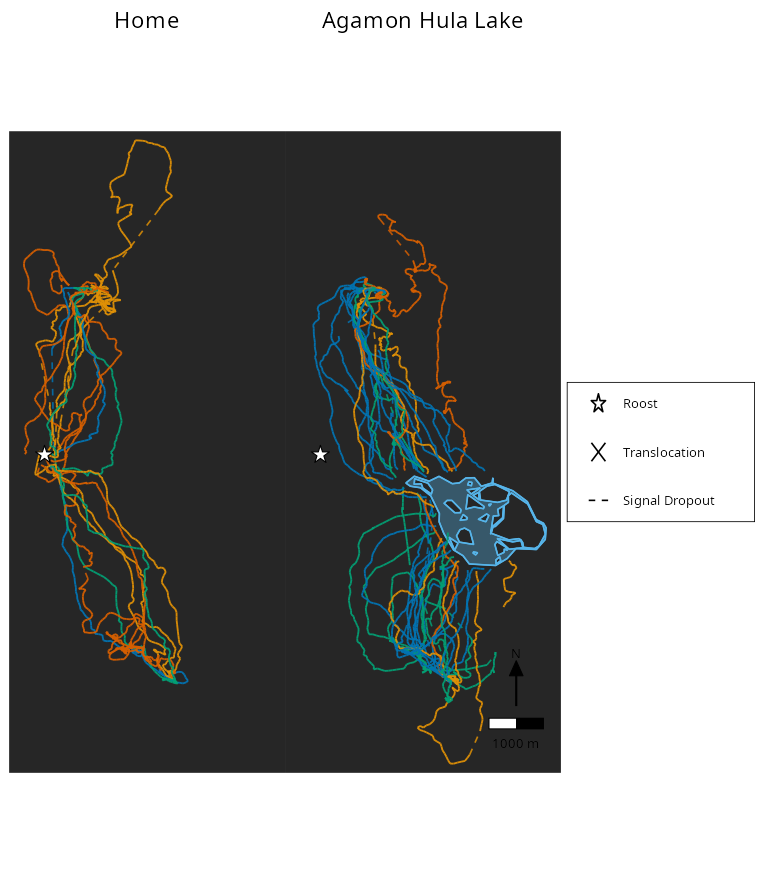

In [14]:
# Full-track destination panels by treatment x destination: one Home and
# one Agamon Hula Lake panel on dark CartoDB tiles (the Python twin
# requests zoom-15 retina tiles; z16 here at the same apparent
# resolution), no repeated treatment legend.
segs_treat <- segments_3857(track_w_treat)
site_bounds <- list(sf::st_bbox(lake_union_3857), sf::st_bbox(roost_3857),
  sf::st_bbox(trans_3857))
ext_dest <- map_extent(c(list(seg_bounds(segs_treat)), site_bounds), pad = 0.06)
bm_dark <- basemap_panel_img(ext_dest["xmin"], ext_dest["ymin"],
  ext_dest["xmax"], ext_dest["ymax"], "dark_all", 16, "#262626")
# The equal-aspect panel boxes of the 7x8 figure are ~0.43 wide/tall.
ae_dest <- aspect_extent(bm_dark, 0.43)
xlim_dest <- ae_dest$xlim; ylim_dest <- ae_dest$ylim
r_roost_dest <- marker_radius_m(220, 3.0, diff(xlim_dest))
r_trans_dest <- marker_radius_m(140, 3.0, diff(xlim_dest))

panel_dest <- function(dest, title, lake = FALSE) {
  sd <- segs_treat[segs_treat$destination == dest, , drop = FALSE]
  p <- map_panel(bm_dark, title, title_size = 15, aspect = 0.43,
    lake = lake, lake_colour = "#56B4E9", lake_alpha = 0.35, lake_lw = 1.2)
  p +
    geom_segment(data = sd[sd$gap, ], inherit.aes = FALSE,
      aes(x = x, y = y, xend = xend, yend = yend, colour = treatment),
      linetype = "dashed", linewidth = 1.44 * 0.3528, alpha = 0.85) +
    geom_segment(data = sd[!sd$gap, ], inherit.aes = FALSE,
      aes(x = x, y = y, xend = xend, yend = yend, colour = treatment),
      linewidth = 1.6 * 0.3528, alpha = 0.95) +
    scale_colour_manual(values = treatment_colors_cb) +
    guides(colour = "none") +
    add_roost_marker(r_roost_dest) +
    add_x_markers(TRANS_XY, r_trans_dest)
}
p_dest_home <- panel_dest("Home", "Home")
p_dest_agam <- panel_dest("Agamon", "Agamon Hula Lake", lake = TRUE)
p_dest_agam <- add_scale_compass(p_dest_agam, xlim_dest, ylim_dest,
  panel_w_in = 2.53, panel_h_in = 5.88)
p_dest_legend <- legend_panel(data.frame(
  n = c(1, 2, 3), kind = c("star", "x", "dash"),
  label = c("Roost", "Translocation", "Signal Dropout")),
  cell_w = 1.8, cell_h = 5.85)
p_destination <- (p_dest_home | p_dest_agam | p_dest_legend) +
  plot_layout(widths = c(0.37, 0.37, 0.26)) +
  theme(plot.margin = margin(2, 2, 2, 2))
save_figure(p_destination, "rediscretized_destination_panels", width = 7, height = 8)


Compact per-panel trajectory plots (one panel per treatment / destination combination).


Basemap: flat-panel fallback (no UNWRAP_CARTO_API_KEY set).


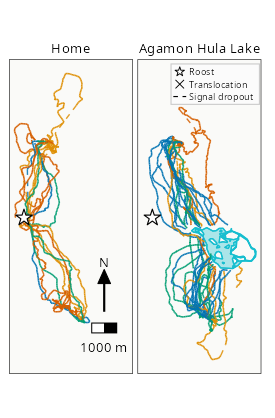

In [15]:
# Compact destination panels (one panel per destination) on light
# CartoDB Positron (no labels) tiles with black panel outlines and the
# legend inside the Agamon panel - the Python twin with fig_w=2.5,
# fig_h=3.8, title_fs=9, legend_fs=6.
ext_compact <- map_extent(c(list(seg_bounds(segs_treat)), site_bounds), pad = 0.05)
bm_light <- basemap_panel_img(ext_compact["xmin"], ext_compact["ymin"],
  ext_compact["xmax"], ext_compact["ymax"], "light_nolabels_novector", 15,
  "#fafaf8")
# The equal-aspect panel boxes of the 2.5x3.8 figure are ~1.22 x 3.10 in.
ae_compact <- aspect_extent(bm_light, 1.22 / 3.10)
xlim_c <- ae_compact$xlim; ylim_c <- ae_compact$ylim
r_roost_c <- marker_radius_m(150, 1.22, diff(xlim_c))
r_trans_c <- marker_radius_m(90, 1.22, diff(xlim_c))

panel_compact <- function(dest, title, lake = FALSE) {
  sd <- segs_treat[segs_treat$destination == dest, , drop = FALSE]
  p <- map_panel(bm_light, title, title_size = 9, border_col = "black",
    aspect = 1.22 / 3.10, lake = lake, lake_alpha = 0.35, lake_lw = 1.0)
  p +
    geom_segment(data = sd[sd$gap, ], inherit.aes = FALSE,
      aes(x = x, y = y, xend = xend, yend = yend, colour = treatment),
      linetype = "dashed", linewidth = 1.22 * 0.3528, alpha = 0.85) +
    geom_segment(data = sd[!sd$gap, ], inherit.aes = FALSE,
      aes(x = x, y = y, xend = xend, yend = yend, colour = treatment),
      linewidth = 1.35 * 0.3528, alpha = 0.95) +
    scale_colour_manual(values = treatment_colors_cb) +
    guides(colour = "none") +
    add_roost_marker(r_roost_c) +
    add_x_markers(TRANS_XY, r_trans_c)
}
# Compact legend inside the Agamon panel, top-right (the Python twin
# draws it at (0.985, 0.985) of that panel).
add_compact_legend <- function(p) {
  # Point scale from the panel's rendered height (2.5x3.8 page with this
  # layout draws the equal-aspect panel ~2.855in tall), so keys, frame pad
  # and 6pt labels land at true point sizes.
  m_per_in <- diff(ylim_c) / 2.855
  pp <- function(pts) pts * m_per_in / 72
  fs_pt <- 6
  labels <- c("Roost", "Translocation", "Signal dropout")
  lw_in <- strwidth(labels, units = "inches") * fs_pt / 12
  pad <- pp(0.35 * fs_pt)          # borderpad
  mcol <- pp(7.2)                  # marker column (markersize 7.2)
  hpad <- pp(0.45 * fs_pt)         # handletextpad
  pitch <- pp(1.35 * fs_pt)        # row pitch (labelspacing 0.35)
  box_w <- 2 * pad + mcol + hpad + max(lw_in) * 1.05 * m_per_in
  box_h <- 2 * pad + pp(fs_pt) + (length(labels) - 1) * pitch
  x1 <- xlim_c[1] + 0.985 * diff(xlim_c)
  x0 <- x1 - box_w
  y1 <- ylim_c[2] - (1 - 0.985) * diff(ylim_c)
  y0 <- y1 - box_h
  gx <- x0 + pad + mcol / 2
  tx <- x0 + pad + mcol + hpad
  ys <- y1 - (pad + pp(fs_pt) / 2 + (0:(length(labels) - 1)) * pitch)
  r_s <- pp(7.2 * 0.9 / 2)         # Roost star radius (scale 0.9)
  r_x <- pp(6.2 * 0.9 / 2)         # X half-diagonal
  d_h <- pp(1.4 * fs_pt / 2)       # dashed-handle half-length
  st <- star_poly_pts(gx, ys[1], r_s)
  p +
    annotate("rect", xmin = x0, xmax = x1, ymin = y0, ymax = y1,
      fill = "#fbfbfb", colour = "#cccccc", linewidth = 0.3528) +
    annotate("polygon", x = st[, 1], y = st[, 2],
      fill = "white", colour = "black", linewidth = 0.8 * 0.3528) +
    annotate("segment", x = gx - r_x, y = ys[2] - r_x,
      xend = gx + r_x, yend = ys[2] + r_x, linewidth = 0.6, colour = "white") +
    annotate("segment", x = gx + r_x, y = ys[2] - r_x,
      xend = gx - r_x, yend = ys[2] + r_x, linewidth = 0.6, colour = "white") +
    annotate("segment", x = gx - r_x, y = ys[2] - r_x,
      xend = gx + r_x, yend = ys[2] + r_x, linewidth = 0.8 * 0.3528, colour = "black") +
    annotate("segment", x = gx + r_x, y = ys[2] - r_x,
      xend = gx - r_x, yend = ys[2] + r_x, linewidth = 0.8 * 0.3528, colour = "black") +
    annotate("text", x = tx, y = ys[1], label = "Roost",
      size = fs_pt * 0.3528, hjust = 0, vjust = 0.5) +
    annotate("text", x = tx, y = ys[2], label = "Translocation",
      size = fs_pt * 0.3528, hjust = 0, vjust = 0.5) +
    annotate("segment", x = gx - d_h, y = ys[3], xend = gx + d_h, yend = ys[3],
      linewidth = 0.3528, colour = "black", linetype = "dashed") +
    annotate("text", x = tx, y = ys[3], label = "Signal dropout",
      size = fs_pt * 0.3528, hjust = 0, vjust = 0.5)
}
p_compact_home <- panel_compact("Home", "Home")
p_compact_home <- add_scale_compass(p_compact_home, xlim_c, ylim_c,
  panel_w_in = 1.22, panel_h_in = 3.10)
p_compact_agam <- panel_compact("Agamon", "Agamon Hula Lake", lake = TRUE)
p_compact_agam <- add_compact_legend(p_compact_agam)
p_destination_compact <- (p_compact_home | p_compact_agam) +
  theme(plot.margin = margin(1, 3, 1, 3))
save_figure(p_destination_compact, "rediscretized_destination_panels_compact",
  width = 2.5, height = 3.8)


Per-treatment destination panels (compact).


After-localization tracking and destination panels.


Destination flow fields: smoothed-distance and harmonic distance fields over the arena, with the
negative-gradient (goal-approach) direction field that supplies `bearing_to_dest` in the goal-relative
constructions above.


Basemap: flat-panel fallback (no UNWRAP_CARTO_API_KEY set).


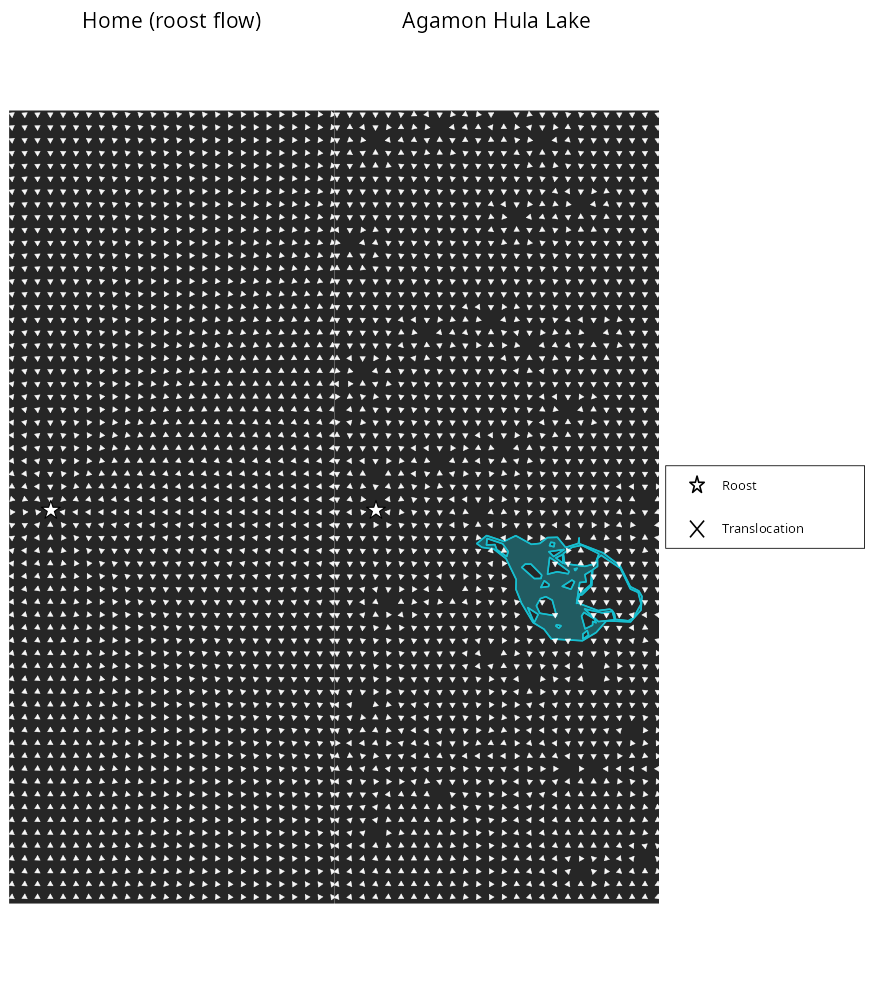

In [16]:
# Goal-approach direction fields feeding bearing_to_dest: the radial
# roost field over the Home panel and the smoothed-distance lake field
# over the Agamon Hula Lake panel, white quivers on dark CartoDB tiles
# (the Python twin uses lake_field="smoothed_distance", 200 m grids and
# no scale/compass UI).
ext_flow <- map_extent(c(list(seg_bounds(segs_treat)), site_bounds), pad = 0.06)
bm_flow <- basemap_panel_img(ext_flow["xmin"], ext_flow["ymin"],
  ext_flow["xmax"], ext_flow["ymax"], "dark_all", 15, "#262626")
# The equal-aspect panel boxes of the 8x9 figure are ~0.41 wide/tall.
ae_flow <- aspect_extent(bm_flow, 0.41)
xlim_flow <- ae_flow$xlim; ylim_flow <- ae_flow$ylim
r_roost_f <- marker_radius_m(220, 3.4, diff(xlim_flow))
r_trans_f <- marker_radius_m(140, 3.4, diff(xlim_flow))

# Flow grids (200 m, the Python resolution) over the full panel extent.
flow_res <- 200
gx <- seq(ceiling(xlim_flow[1] / flow_res) * flow_res,
  floor(xlim_flow[2] / flow_res) * flow_res, by = flow_res)
gy <- seq(ceiling(ylim_flow[1] / flow_res) * flow_res,
  floor(ylim_flow[2] / flow_res) * flow_res, by = flow_res)
gpts <- expand.grid(x = gx, y = gy)
lake_mask <- lengths(sf::st_within(
  sf::st_as_sf(gpts, coords = c("x", "y"), crs = 3857), lake_union_3857)) > 0L
nxf <- length(gx); nyf <- length(gy)
M <- t(matrix(lake_mask, nrow = nyf, ncol = nxf))
# squared distance (in grid steps) to the nearest lake cell
d2 <- matrix(Inf, nyf, nxf)
li <- which(M, arr.ind = TRUE)
for (i in seq_len(nrow(li))) {
  dr <- seq_len(nyf) - li[i, 1]
  d2 <- pmin(d2, outer(dr, seq_len(nxf) - li[i, 2],
    function(a, b) a^2 + b^2))
}
dist_f <- sqrt(d2) * flow_res
dist_f[M > 0] <- 0
# one-pixel (sigma ~ 1) Gaussian pass on each axis, mirrored edges
gpass1d <- function(v) {
  n <- length(v)
  j <- function(i) pmin(n, pmax(1L, i))
  j1 <- j(seq_len(n) - 1L); j2 <- j(seq_len(n)); j3 <- j(seq_len(n) + 1L)
  v[j1] / 4 + v[j2] / 2 + v[j3] / 4
}
dist_f <- apply(dist_f, 2, gpass1d)
dist_f <- t(apply(dist_f, 1, gpass1d))
# unit vectors pointing at the lake (negative gradient of distance)
txf <- matrix(0, nyf, nxf); tyf <- matrix(0, nyf, nxf)
txf[, 2:(nxf - 1L)] <- -(dist_f[, 3:nxf] - dist_f[, 1:(nxf - 2L)]) / (2 * flow_res)
txf[, 1L] <- if (nxf > 1L) -(dist_f[, 2L] - dist_f[, 1L]) / flow_res else 0
txf[, nxf] <- if (nxf > 1L) -(dist_f[, nxf] - dist_f[, nxf - 1L]) / flow_res else 0
tyf[2:(nyf - 1L), ] <- -(dist_f[3:nyf, ] - dist_f[1:(nyf - 2L), ]) / (2 * flow_res)
tyf[1L, ] <- if (nyf > 1L) -(dist_f[2L, ] - dist_f[1L, ]) / flow_res else 0
tyf[nyf, ] <- if (nyf > 1L) -(dist_f[nyf, ] - dist_f[nyf - 1L, ]) / flow_res else 0
normf <- sqrt(txf^2 + tyf^2)
txf <- txf / normf; tyf <- tyf / normf
txf[normf <= 1e-12] <- NA_real_
tyf[normf <= 1e-12] <- NA_real_
txf[M > 0] <- NA_real_
tyf[M > 0] <- NA_real_
# radial field toward the roost (no mask)
rx <- gpts$x - ROOST_XY[1]; ry <- gpts$y - ROOST_XY[2]
nr <- sqrt(rx^2 + ry^2)
txr <- -rx / nr; tyr <- -ry / nr
# Arrow length: the Python quiver with unit vectors and scale 30 draws
# ~1/30 in shafts per 3.4 in of panel, i.e. ~1% of the panel width.
arrow_len_f <- 0.010 * diff(xlim_flow)
# expand.grid order: x index fastest, so as.vector(M) matches the point
# rows; the fields must be transposed first for the same reason.
lake_dir <- data.frame(x = gpts$x, y = gpts$y,
  xend = gpts$x + arrow_len_f * as.vector(t(txf)), yend = gpts$y + arrow_len_f * as.vector(t(tyf)),
  in_lake = lake_mask)
lake_dir <- lake_dir[!lake_dir$in_lake & is.finite(lake_dir$xend), , drop = FALSE]
roost_dir <- data.frame(x = gpts$x, y = gpts$y,
  xend = gpts$x + arrow_len_f * txr, yend = gpts$y + arrow_len_f * tyr)
roost_dir <- roost_dir[is.finite(roost_dir$xend), , drop = FALSE]

p_flow_home <- map_panel(bm_flow, "Home (roost flow)", title_size = 14,
  aspect = 0.41) +
  geom_segment(data = roost_dir, inherit.aes = FALSE,
    aes(x = x, y = y, xend = xend, yend = yend),
    arrow = grid::arrow(length = grid::unit(0.05, "inches"), type = "closed"),
    linewidth = 0.14, alpha = 0.95, colour = "#ffffff") +
  add_roost_marker(r_roost_f) +
  add_x_markers(TRANS_XY, r_trans_f)
p_flow_agam <- map_panel(bm_flow, "Agamon Hula Lake", title_size = 14,
  aspect = 0.41, lake = TRUE, lake_alpha = 0.35, lake_lw = 1.2) +
  geom_segment(data = lake_dir, inherit.aes = FALSE,
    aes(x = x, y = y, xend = xend, yend = yend),
    arrow = grid::arrow(length = grid::unit(0.05, "inches"), type = "closed"),
    linewidth = 0.14, alpha = 0.95, colour = "#ffffff") +
  add_roost_marker(r_roost_f) +
  add_x_markers(TRANS_XY, r_trans_f)
p_flow_legend <- legend_panel(data.frame(
  n = c(1, 2), kind = c("star", "x"),
  label = c("Roost", "Translocation")),
  cell_w = 1.9, cell_h = 7.3)
p_flow <- (p_flow_home | p_flow_agam | p_flow_legend) +
  plot_layout(widths = c(0.38, 0.38, 0.24)) +
  theme(plot.margin = margin(2, 2, 2, 2))
save_figure(p_flow, "destination_flow_fields_smoothed_distance", width = 8, height = 9)


### Descriptive circular summaries by treatment

Per-treatment concentration summaries (descriptive, no model): estimated population concentration
($\hat\kappa$), mean resultant length ($\vec{R}$), and the alignment of each individual's mean
bearing to $0^\circ$ (goal direction). These give a first, model-free read on whether treatment
changes directional bias or precision.


In [17]:
theta_grid <- seq(0, 2 * pi, length.out = 360)
kde_vm <- function(y, theta = theta_grid, kappa = 30) {
  # Matrix form of the grid-point averages: exp(vm_logpdf(t, y, kappa))
  # = exp(kappa*cos(t - y)) / (2*pi*I0(kappa)); rowMeans takes the mean
  # over the observations at each grid point, as the vapply did.
  rowMeans(exp(kappa * cos(outer(theta, y, `-`))) /
    (2 * pi * besselI(kappa, 0, expon.scaled = FALSE)))
}
descriptive_data <- track_w_treat[is.finite(track_w_treat$flightAngDiffDest_deg), ]
descriptive_data$HeadingRadians <- wrap(descriptive_data$flightAngDiffDest_deg * pi / 180)
descriptive_data$tag <- factor(descriptive_data$tag, levels = levels(df_track$tag))
descriptive_data$treatment <- factor(descriptive_data$treatment, levels = 1:4)
# Descriptive plots use all finite bearings, as in the source; their input
# need not exclude rows with missing along-field destination distances.
tag_observed <- split(descriptive_data, descriptive_data$tag)
kde_data <- do.call(rbind, lapply(tag_observed, function(g) {
  data.frame(theta = theta_grid, density = kde_vm(g$HeadingRadians, kappa = 15),
    tag = as.character(g$tag[1]), treatment = g$treatment[1])
}))
# Panel order in treatment blocks, tags ascending within each block; the
# same grouping the per-tag estimates below use for their colour.
tag_meta <- do.call(rbind, lapply(tag_observed, function(g) {
  data.frame(tag = as.character(g$tag[1]), treatment = g$treatment[1],
    stringsAsFactors = FALSE)
}))
tag_meta <- tag_meta[order(tag_meta$treatment, as.numeric(tag_meta$tag)), ]
# Per-tag polar KDE panels: 0 deg at right with the counter-clockwise
# orientation, one curve per tag in the treatment colour, the two density
# rings (r = 1 at density 0, r = 2 at density 1), four grey direction
# spokes, and a darker 0-deg segment from r = 1 to r = 2.
xmap_polar <- function(a) (pi / 2 - a) %% (2 * pi)
kde_data$theta_x <- xmap_polar(kde_data$theta)
kde_data$taglabel <- factor(paste0("tag ", kde_data$tag),
  levels = paste0("tag ", as.character(tag_meta$tag)))
rmax_polar <- 1 + max(1, max(kde_data$density)) + 0.2
pg_a <- seq(0, 2 * pi, length.out = 361L)
polar_rings <- data.frame(theta = rep(xmap_polar(pg_a), 2),
  y = c(rep(1, 361L), rep(2, 361L)), ring = rep(1:2, each = 361L))
spoke_a <- c(-pi / 2, 0, pi / 2, pi)
polar_spokes <- data.frame(theta = rep(xmap_polar(spoke_a), each = 2),
  y = rep(c(1, rmax_polar), 4), sp = rep(seq_along(spoke_a), each = 2))
polar_zero <- data.frame(theta = c(xmap_polar(0), xmap_polar(0)), y = c(1, 2))
nc_polar <- ceiling(sqrt(nrow(tag_meta)))
p_polar_data <- ggplot(kde_data, aes(theta_x, 1 + density, colour = treatment,
    group = interaction(treatment, tag))) +
  geom_line(linewidth = 0.7, alpha = 0.95) +
  geom_path(data = polar_rings, inherit.aes = FALSE, aes(theta, y, group = ring),
    colour = "#999999", linewidth = 0.32, alpha = 0.65) +
  geom_path(data = polar_spokes, inherit.aes = FALSE, aes(theta, y, group = sp),
    colour = "#bfbfbf", linewidth = 0.28, alpha = 0.7) +
  geom_path(data = polar_zero, inherit.aes = FALSE, aes(theta, y),
    colour = "#a6a6a6", linewidth = 0.57, alpha = 0.95) +
  facet_wrap(~ taglabel, ncol = nc_polar) +
  scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0),
    breaks = xmap_polar(c(0, pi / 2, pi, -pi / 2)), labels = c("0°", "90°",
    "±180°", "-90°")) +
  coord_polar() +
  scale_y_continuous(limits = c(0, rmax_polar), expand = c(0, 0)) +
  scale_colour_manual(values = treatment_colors, name = NULL) +
  guides(colour = "none") +
  theme_minimal(base_size = 9) +
  theme(axis.line = element_blank(), axis.ticks = element_blank(),
    axis.text.y = element_blank(),
    axis.text.x = element_text(size = 6, colour = "grey25"),
    panel.grid = element_blank(), panel.border = element_blank(),
    strip.background = element_blank(), strip.text = element_text(size = 9)) +
  labs(x = "", y = "")
estimate_kappa <- function(rbar, n) {
  rbar <- min(max(rbar, 0), 0.999999999)
  if (rbar < 0.53) {
    k <- 2 * rbar + rbar^3 + (5 / 6) * rbar^5
  } else if (rbar < 0.85) {
    k <- -0.4 + 1.39 * rbar + 0.43 / (1 - rbar)
  } else {
    k <- 1 / (rbar^3 - 4 * rbar^2 + 3 * rbar)
  }
  if (n > 1L) {
    if (k < 2) {
      k <- if (k > 0) max(k - 2 / (n * k), 0) else 0
    } else {
      k <- (n - 1)^3 * k / (n^3 + n)
    }
  }
  k
}
descriptive <- do.call(rbind, lapply(tag_observed, function(g) {
  a <- g$HeadingRadians
  rbar <- resultant(a)
  data.frame(tag = as.character(g$tag[1]), treatment = g$treatment[1],
    n = length(a), Rbar = rbar, kappa_hat = estimate_kappa(rbar, length(a)),
    alignment0 = mean(cos(a)))
}))
# Axis labels: comma parts of the raw treatment name, sorted, "control"
# dropped when other components are present, first letter of each part
# upper-cased ("Anosmia, Eye cover, Magnet").
fmt_treat_name <- function(s) {
  parts <- trimws(strsplit(tolower(s), ",", fixed = TRUE)[[1]])
  parts <- parts[nchar(parts) > 0]
  if (length(parts) > 1L && "control" %in% parts) parts <- parts[parts != "control"]
  if (!length(parts)) parts <- "control"
  parts <- paste0(toupper(substring(sort(parts), 1, 1)),
    substring(sort(parts), 2))
  paste(parts, collapse = ", ")
}
treat_name_fmt <- vapply(tnames, fmt_treat_name, character(1))
# One panel per treatment: the per-tag estimates as jittered dots, the
# median as a filled circle, and the 25-75 percentile range as a bar.
desc_plot <- function(variable, label, ylim, grid_y = FALSE) {
  set.seed(0)
  blocks <- split(descriptive, descriptive$treatment)
  jit <- lapply(blocks, function(g) runif(nrow(g), -0.10, 0.10))
  dots <- do.call(rbind, lapply(seq_along(blocks), function(i) {
    data.frame(x = (i - 1) + jit[[i]], y = blocks[[i]][[variable]],
      treatment = blocks[[i]]$treatment[1])
  }))
  # Dots beyond the fixed axis limits are clipped at the edge, as in the
  # source; dropping them keeps the render identical and quiet.
  dots <- dots[is.finite(dots$y) & dots$y >= ylim[1] & dots$y <= ylim[2], ]
  stats <- do.call(rbind, lapply(seq_along(blocks), function(i) {
    g <- blocks[[i]]
    q <- quantile(g[[variable]], c(0.25, 0.50, 0.75), names = FALSE)
    data.frame(x = i - 1, treatment = g$treatment[1],
      med = q[2], lo = q[1], hi = q[3])
  }))
  p <- ggplot(dots, aes(x, y, colour = treatment, group = treatment)) +
    geom_point(shape = 16, size = 1.23, alpha = 0.9) +
    geom_errorbar(data = stats, aes(y = med, ymin = lo, ymax = hi),
      colour = "black", linewidth = 0.35, width = 0.14) +
    geom_point(data = stats, aes(y = med, fill = treatment),
      shape = 21, size = 1.76, colour = "black") +
    scale_colour_manual(values = treatment_colors, name = NULL) +
    scale_fill_manual(values = treatment_colors, name = NULL) +
    guides(colour = "none", fill = "none") +
    scale_x_continuous(breaks = 0:(length(blocks) - 1L),
      labels = treat_name_fmt, expand = c(0.2, 0.2)) +
    scale_y_continuous(limits = ylim, expand = c(0, 0),
      breaks = if (variable == "kappa_hat") c(0, 5, 10) else c(0, 0.5, 1)) +
    labs(x = "", y = label) +
    theme_classic(base_size = 10) +
    theme(axis.text.x = element_text(angle = 25, hjust = 1))
  if (grid_y) {
    p <- p + theme(panel.grid.major.y = element_line(linewidth = 0.2,
      colour = "grey80"))
  }
  p
}
p_kappa_desc <- desc_plot("kappa_hat", expression("Estimated " * hat(kappa)), c(0, 10), grid_y = TRUE)
p_R_desc <- desc_plot("Rbar", "Mean\nresultant length", c(-0.05, 1.05))
p_align_desc <- desc_plot("alignment0", "Alignment\nE[cos(y)]", c(0, 1.02))


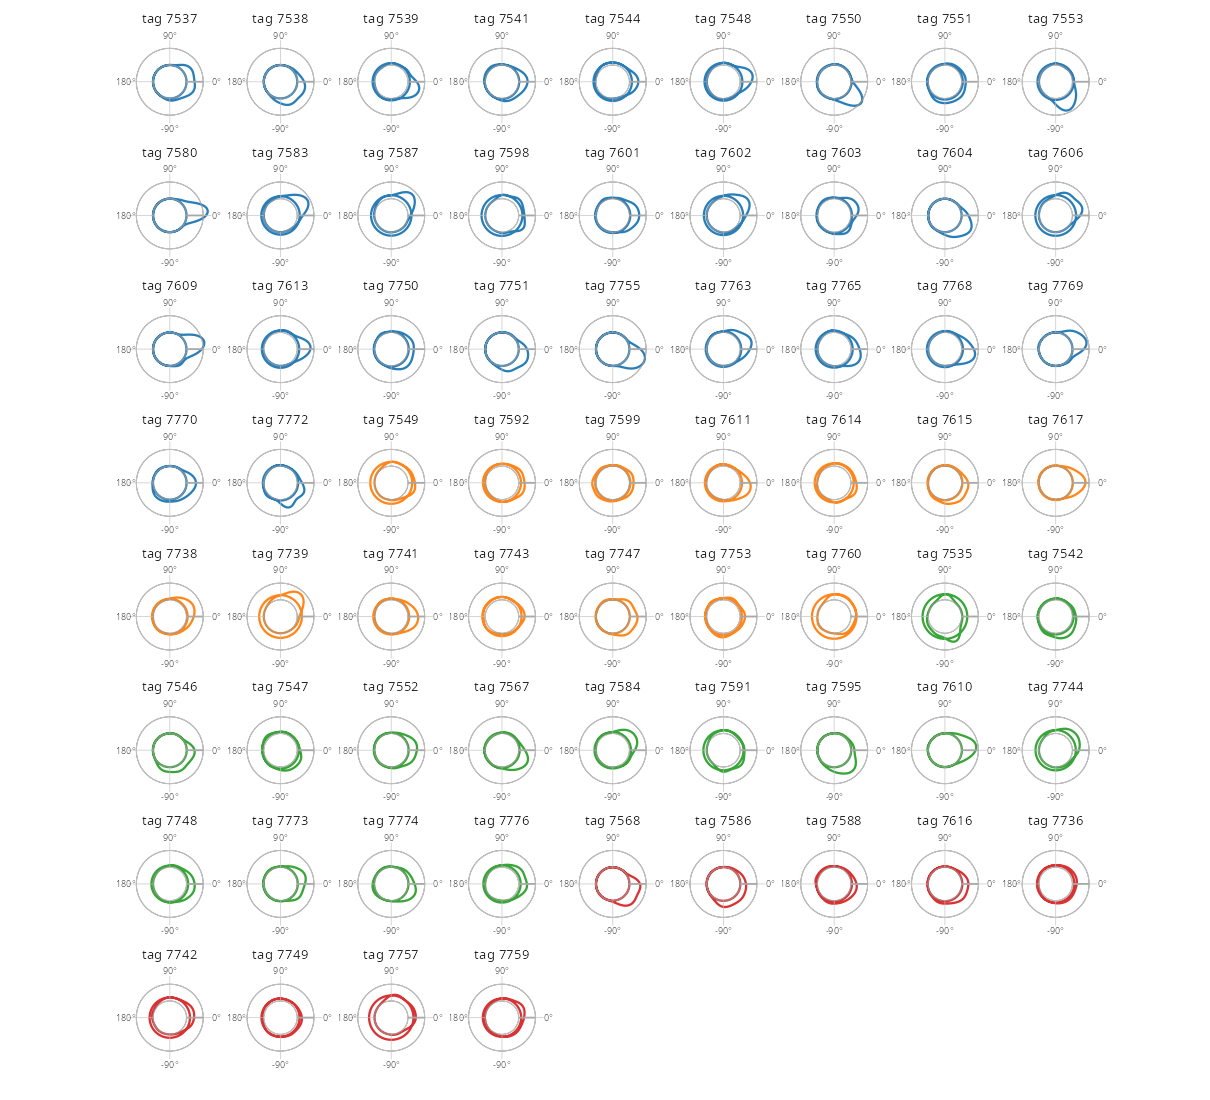

In [18]:
save_figure(p_polar_data, "polar_vonmises_kde_all", 11, 10)


$\hat\kappa$ (concentration) by treatment, median with percentile bands.


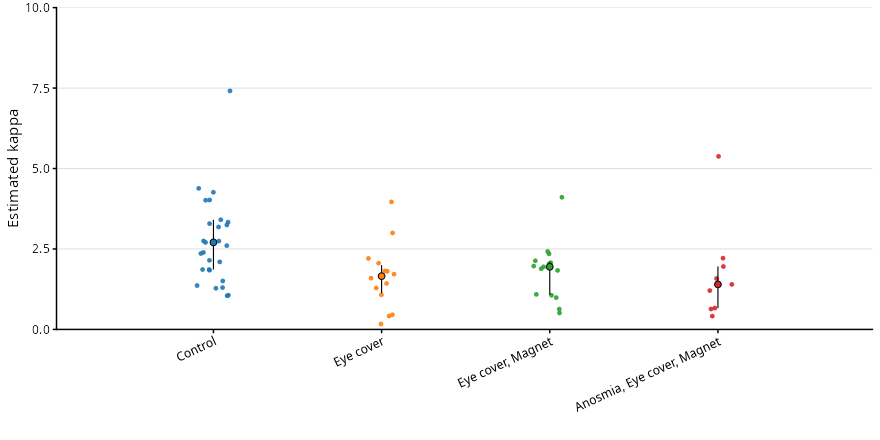

In [19]:
save_figure(p_kappa_desc, "kappa_hat_by_treatment_median_percentiles", 2.6, 2.2)


Mean resultant length $\vec{R}$ by treatment, median with percentile bands.


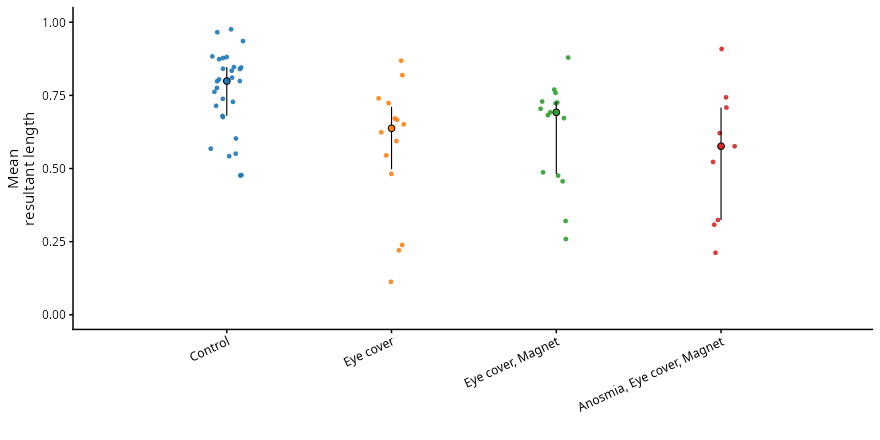

In [20]:
save_figure(p_R_desc, "rbar_by_treatment_median_percentiles", 2.6, 2.2)


Alignment of individual mean bearings to $0^\circ$ by treatment, median with percentile bands.


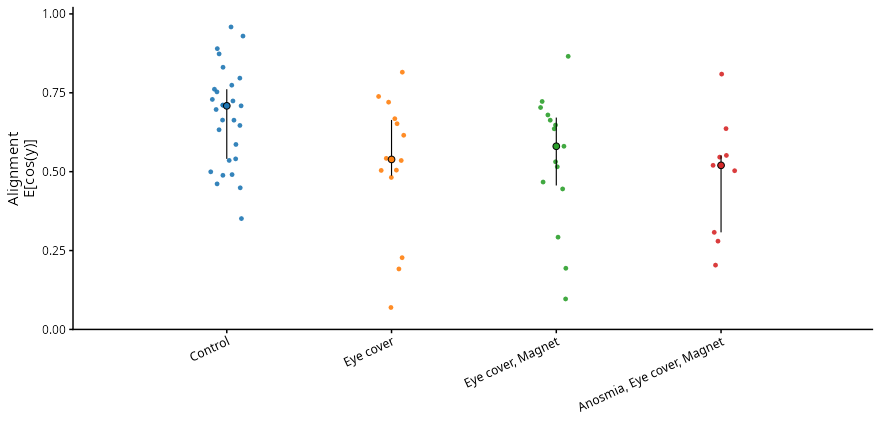

In [21]:
save_figure(p_align_desc, "alignment0_by_treatment_median_percentiles", 2.6, 2.2)


## 6. Single von Mises treatment model (baseline)

Build the modeling table for a **single** von Mises likelihood: response `HeadingRadians` (the
goal-relative bearing wrapped to $(-\pi, \pi]$), a **treatment** fixed effect, and a **per-tag random
intercept** (repeated measures). Predictors (`z_log_dist`) are standardized. This is the
non-mixed baseline; the mixture below will be judged against it.



Direction tag shifts are Normal with HalfNormal(1/sqrt(30)) scale; the
concentration intercept prior is Normal(inverse_softplus(3), 1). The
von Mises tag hyperprior belongs to the mixture model below. All
treatment effects use control (1) as reference.


In [22]:
# Python c41 uses Normal tag direction effects with a HalfNormal
# sd = 1/sqrt(30), not a von Mises tag prior. Preserve that actual model.
vector_vm <- stanvar(scode = "
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }
", block = "functions")
base_form <- bf(HeadingRadians ~ mu,
  nlf(mu ~ beta0 + tagshift),
  beta0 ~ 0 + Intercept + treat2 + treat3 + treat4,
  tagshift ~ 0 + (1 | tag),
  kappa ~ 0 + Intercept + treat2 + treat3 + treat4 + (1 | tag),
  family = unwrap_von_mises)
base_priors <- (
  # The direction coefficients are unconstrained reals, matching the
  # Python twin's circ_mod parameterization: its von Mises coefficient
  # priors are periodic over the real line and carry no +-pi bounds; a
  # uniform prior is NOT used (bounded uniform boxes pin NUTS chains
  # against the +-pi walls). Each coefficient's prior is its von Mises
  # log density, added as an explicit target term.
  set_prior("target += unwrap_von_mises_lpdf(b_beta0[1] | 0, 1)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_beta0[2:4] | 0, 2)", check = FALSE) +
  prior("normal(0, 0.18257418583505536)", class = "sd", nlpar = "tagshift") +
  prior("normal(log(exp(3) - 1), 1)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat2", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat3", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat4", dpar = "kappa") +
  prior("normal(0, 1)", class = "sd", dpar = "kappa")
)
# EQUIVALENCE NOTE: exact c41 values govern the baseline; the centered
# von Mises coefficient-vector pattern is needed for fixed direction
# effects, while tag shifts remain non-centered Gaussian effects here.
base_stanvars <- stan_unwrap_fun + modulo_circular_fun + vector_vm
base_stan <- make_stancode(base_form, data = df_track, prior = base_priors,
                           stanvars = base_stanvars)
stopifnot(grepl("vector[K_beta0] b_beta0;", base_stan, fixed = TRUE),
          !grepl("uniform_lpdf", base_stan, fixed = TRUE),
          grepl("unwrap_von_mises_vect_lpdf", base_stan, fixed = TRUE))
cat(base_stan)
# Check the generated parameters block and coefficient order before init:
# b_beta0 has four unbounded entries: Intercept, treat2, treat3, treat4.
base_standata <- make_standata(base_form, data = df_track, prior = base_priors,
                              stanvars = base_stanvars)
base_parameter_block <- regmatches(base_stan,
  regexpr("(?m)^parameters\\s*\\{[^}]*\\}", base_stan, perl = TRUE))
base_parameter_block <- gsub("[[:space:]]", "", base_parameter_block)
stopifnot(length(base_parameter_block) == 1L,
  # Unbounded circular coefficient vector: plain real vector (the
  # Python circ_mod geometry), no +-pi bounds or uniform factors.
  grepl("vector[K_beta0]b_beta0;", base_parameter_block, fixed = TRUE),
  base_standata$K_beta0 == 4L,
  identical(colnames(base_standata$X_beta0),
    c("Intercept", "treat2", "treat3", "treat4")))

# Unbounded angular coefficients carry 2*pi-equivalent posterior wrap
# classes when heading sums straddle the seam. Seed all chains in one
# class with data-derived anchors and jitter too small to cross a seam.
# Jitter is added AFTER wrapping; initialization changes only the sampler
# path, never the posterior. Initialize only b_beta0 here; Gaussian tagshift
# effects and all kappa parameters retain CmdStan defaults.
base_treat_mean <- tapply(df_track$HeadingRadians, df_track$treatment, circ_mean)
mu_anchor <- as.numeric(base_treat_mean[levels(df_track$treatment)[1]])
treat_anchor <- as.numeric(mod_circular(
  base_treat_mean[levels(df_track$treatment)[-1]] - mu_anchor))
stopifnot(length(base_treat_mean) == nlevels(df_track$treatment),
  length(treat_anchor) == 3L,
  length(c(mu_anchor, treat_anchor)) == base_standata$K_beta0,
  abs(mu_anchor) < pi - 0.2, all(abs(treat_anchor) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_beta0 = as.numeric(c(mu_anchor, treat_anchor) + j(base_standata$K_beta0)))
}
set.seed(123)
fit_vm <- unwrap_load_fit_cache("bats_fit_vm_v2", SEED, ITER, WARMUP)
if (is.null(fit_vm)) {
  fit_vm <- brm(base_form, data = df_track, prior = base_priors,
    stanvars = base_stanvars, backend = "cmdstanr",
    chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
    seed = SEED,
    init = lapply(seq_len(CHAINS), function(k) mk_init(SEED + k)),
    control = list(adapt_delta = 0.97))
  unwrap_save_fit_cache("bats_fit_vm_v2", fit_vm, SEED, ITER, WARMUP)
}
base_parameters <- posterior::variables(posterior::as_draws_array(fit_vm))
base_angular <- base_parameters[grepl("^b_beta0_", base_parameters)]
base_summary <- diagnose_fit(fit_vm, angular = base_angular)


// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }
  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }

}
data {
  int<lower=1> N;  // 

Start sampling



Init values were only set for a subset of parameters. 
Missing init values for the following parameters:
 - chain 1: b_kappa, sd_1, z_1, sd_2, z_2
 - chain 2: b_kappa, sd_1, z_1, sd_2, z_2
 - chain 3: b_kappa, sd_1, z_1, sd_2, z_2
 - chain 4: b_kappa, sd_1, z_1, sd_2, z_2

To disable this message use options(cmdstanr_warn_inits = FALSE).




Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 3 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 2 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 1 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 3 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 1 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 2 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 4 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 3 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 1 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 2 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 3 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 4 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 2 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 1 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 3 Iteration:  500 / 4000 [ 12%]  (Warmup) 
Chain 4 Iteration:  300 / 400

Loading required namespace: rstan



Divergences: not retained in this fit object (see R-hat/ESS below).
                          parameter         mean         sd      rhat  ess_bulk
1                 b_beta0_Intercept -0.067652484 0.08161690 1.0004684  1054.691
2                    b_beta0_treat2  0.154334475 0.14955954 1.0025994  1251.533
3                    b_beta0_treat3 -0.149886478 0.14057426 1.0008253  1538.951
4                    b_beta0_treat4 -0.077015969 0.16681322 1.0007359  1856.693
5                 b_kappa_Intercept  2.614964020 0.24727535 1.0022366  1681.258
6                    b_kappa_treat2 -1.213034556 0.42024535 1.0002858  1785.058
7                    b_kappa_treat3 -0.937985371 0.41211589 1.0006976  1601.960
8                    b_kappa_treat4 -1.167996380 0.48041491 1.0007572  1713.975
9           sd_tag__kappa_Intercept  1.383892853 0.15829504 1.0005732  2001.756
10       sd_tag__tagshift_Intercept  0.444117788 0.04066802 1.0000721  2016.655
11     r_tag__kappa[7535,Intercept] -1.787772724 0.5

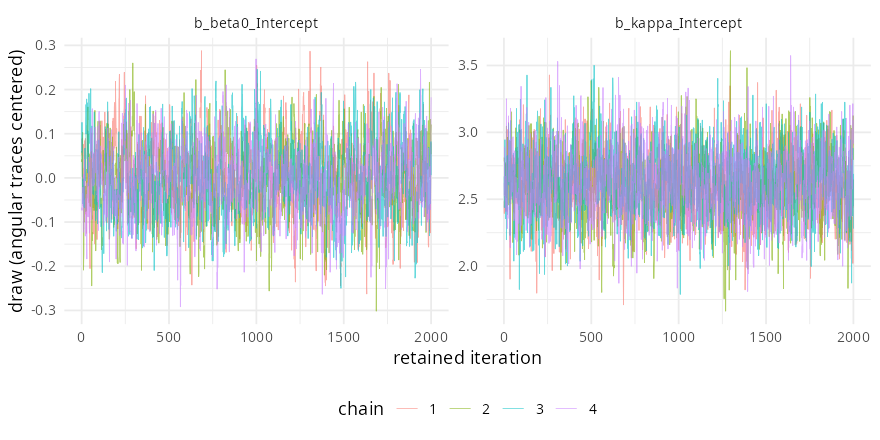

In [23]:
save_figure(trace_plot(fit_vm, c("b_beta0_Intercept", "b_kappa_Intercept"), base_angular), "vonmises_trace", 8, 4)


### PSIS-LOO comparison (vMU vs vM)

Out-of-sample comparison of the two fits by PSIS-LOO. The logit-scale posterior of the mixture weight is mapped back to $(0, 1)$, so the directed-component probability $p$ is reported in interpretable terms.


In [24]:
qs <- c(0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99)
data.frame(quantile = qs, probability = plogis(qnorm(qs, qlogis(0.9), 1)))


quantile,probability
<dbl>,<dbl>
0.01,0.4677640
0.05,0.6346855
0.10,0.7141596
0.25,0.8209408
0.50,0.9000000
0.75,0.9464303
0.90,0.9700778
0.95,0.9790014
0.99,0.9892663


### Fit the full von Mises--Uniform mixture

`mix_form` specifies **each step** as
$\text{Heading} \sim p\,\mathrm{VM}(\mu, \kappa) + (1-p)\,\mathrm{Uniform}$, with

- $\mu$ = goal-directed mean direction (population `mu0` + per-tag von Mises offsets + treatment
  offsets),
- $\kappa$ = goal-directed concentration (softplus-linked, per-tag offsets + treatment offsets),
- $p$ = probability a step is goal-directed (logit-linked, per-tag offsets + treatment offset).

The undirected (uniform) component explicitly represents exploratory movement, so a single
concentration no longer has to absorb both dispersion during homing and wandering — and no
post-treatment "homing" filter is needed.



In [25]:
# Cell 53's exact uniform-circle component; no near-uniform approximation
# enters the likelihood. brms generates target += unwrap_vmu_lpdf(...).
unwrap_vmu <- custom_family("unwrap_vmu", dpars = c("mu", "kappa", "pgoal"),
  links = c("identity", "softplus", "logit"),
  lb = c(NA, 0, 0), ub = c(NA, NA, 1), type = "real")
mixture_functions <- stanvar(scode = "
  real unwrap_vmu_lpdf(real y, real mu, real kappa, real pgoal) {
    return log_mix(pgoal, unwrap_von_mises_lpdf(y | mu, kappa), -log(2*pi()));
  }
  real unwrap_vmu_rng(real mu, real kappa, real pgoal) {
    if (bernoulli_rng(pgoal)) return unwrap_von_mises_rng(mu, kappa);
    return uniform_rng(-pi(), pi());
  }
", block = "functions")
mixture_hyper <- stanvar(scode = "real<lower=0> kmu_tag;", block = "parameters")
for (t in 2:4) df_track[[paste0("treat", t)]] <- as.integer(df_track$treatment == as.character(t))
mix_form <- bf(HeadingRadians ~ mu,
  nlf(mu ~ mu0 + mutreat + mutag),
  mu0 ~ 1,
  mutreat ~ 0 + treat2 + treat3 + treat4,
  mutag ~ 0 + tag,
  kappa ~ 0 + Intercept + treat2 + treat3 + treat4 + (1 | tag),
  pgoal ~ 0 + Intercept + treat2 + treat3 + treat4 + (1 | tag),
  family = unwrap_vmu)
mix_priors <- (
  # The direction coefficients are unconstrained reals, matching the
  # Python twin's circ_mod parameterization: its von Mises coefficient
  # priors are periodic over the real line and carry no +-pi bounds; a
  # uniform prior is NOT used (bounded uniform boxes pin NUTS chains
  # against the +-pi walls). Each coefficient's prior is its von Mises
  # log density, added as an explicit target term.
  set_prior("target += unwrap_von_mises_lpdf(b_mu0[1] | 0, 1)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_mutreat | 0, 2)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_mutag | 0, kmu_tag)", check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_tag | log(30), 0.1)", check = FALSE) +
  prior("normal(log(exp(5) - 1), 1)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat2", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat3", dpar = "kappa") +
  prior("normal(0, 1)", class = "b", coef = "treat4", dpar = "kappa") +
  prior("normal(0, 1)", class = "sd", dpar = "kappa") +
  prior("normal(log(0.8 / 0.2), 1)", class = "b", coef = "Intercept", dpar = "pgoal") +
  prior("normal(0, 1)", class = "b", coef = "treat2", dpar = "pgoal") +
  prior("normal(0, 1)", class = "b", coef = "treat3", dpar = "pgoal") +
  prior("normal(0, 1)", class = "b", coef = "treat4", dpar = "pgoal") +
  prior("normal(0, 1)", class = "sd", dpar = "pgoal")
)
# PyMC's sigmoid([eta,-eta]) is (plogis(eta),1-plogis(eta)), not a
# two-logit softmax. The pgoal formula therefore uses eta, not 2*eta.
# (The uniform factor in the likelihood is the EXACT circular-uniform
# mixture component -log(2*pi), not a prior.)
mix_stanvars <- base_stanvars + mixture_functions + mixture_hyper
mix_stan <- make_stancode(mix_form, data = df_track, prior = mix_priors,
                          stanvars = mix_stanvars)
stopifnot(grepl("log_mix(pgoal", mix_stan, fixed = TRUE),
          grepl("kmu_tag", mix_stan, fixed = TRUE),
          grepl("target += unwrap_vmu_lpdf", mix_stan, fixed = TRUE))
cat(mix_stan)
# Check the generated parameters block and coefficient order before init:
# b_mu0: Intercept (1); b_mutreat: treat2, treat3, treat4 (3);
# b_mutag: one entry per tag, in levels(df_track$tag) order.
mix_standata <- make_standata(mix_form, data = df_track, prior = mix_priors,
                             stanvars = mix_stanvars)
mix_parameter_block <- regmatches(mix_stan,
  regexpr("(?m)^parameters\\s*\\{[^}]*\\}", mix_stan, perl = TRUE))
mix_parameter_block <- gsub("[[:space:]]", "", mix_parameter_block)
stopifnot(length(mix_parameter_block) == 1L,
  # Unbounded circular coefficient vectors: plain real vectors (the
  # Python circ_mod geometry), no +-pi bounds or uniform factors.
  all(vapply(c("mu0", "mutreat", "mutag"), function(p) {
    grepl(paste0("vector[K_", p, "]b_", p, ";"), mix_parameter_block, fixed = TRUE)
  }, logical(1))),
  !grepl("uniform_lpdf", mix_stan, fixed = TRUE),
  grepl("real<lower=0>kmu_tag;", mix_parameter_block, fixed = TRUE),
  mix_standata$K_mu0 == 1L, mix_standata$K_mutreat == 3L,
  mix_standata$K_mutag == nlevels(df_track$tag),
  identical(colnames(mix_standata$X_mu0), "Intercept"),
  identical(colnames(mix_standata$X_mutreat), c("treat2", "treat3", "treat4")),
  isTRUE(all.equal(mix_standata$X_mutag,
    model.matrix(~ 0 + tag, data = df_track), check.attributes = FALSE)))

# Unbounded angular coefficients carry 2*pi-equivalent posterior wrap
# classes when heading sums straddle the seam. Seed all chains in one
# class with data-derived anchors and jitter too small to cross a seam.
# Jitter is added AFTER wrapping; initialization changes only the sampler
# path, never the posterior. Initialize b_mu0, b_mutreat, b_mutag, and kmu_tag
# (30, the middle of its LogNormal(log(30), 0.1) hyperprior). Gaussian random
# effects and all kappa/pgoal parameters retain CmdStan defaults.
mix_treat_mean <- tapply(df_track$HeadingRadians, df_track$treatment, circ_mean)
mu0_anchor <- as.numeric(mix_treat_mean[levels(df_track$treatment)[1]])
mutreat_anchor <- as.numeric(mod_circular(
  mix_treat_mean[levels(df_track$treatment)[-1]] - mu0_anchor))
tag_mean <- tapply(df_track$HeadingRadians, df_track$tag, circ_mean)
tag_treatment <- vapply(levels(df_track$tag), function(tag_id) {
  treatment <- unique(as.character(df_track$treatment[df_track$tag == tag_id]))
  stopifnot(length(treatment) == 1L)
  treatment
}, character(1))
mutag_anchor <- as.numeric(mod_circular(tag_mean[levels(df_track$tag)] -
  mu0_anchor - c(0, mutreat_anchor)[match(tag_treatment, levels(df_track$treatment))]))
stopifnot(length(mix_treat_mean) == nlevels(df_track$treatment),
  length(mu0_anchor) == mix_standata$K_mu0,
  length(mutreat_anchor) == mix_standata$K_mutreat,
  length(tag_mean) == nlevels(df_track$tag),
  length(mutag_anchor) == mix_standata$K_mutag,
  abs(mu0_anchor) < pi - 0.2,
  all(abs(mutreat_anchor) < pi - 0.5), all(abs(mutag_anchor) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_mu0 = as.numeric(mu0_anchor + j(1)),
    b_mutreat = as.numeric(mutreat_anchor + j(length(mutreat_anchor))),
    b_mutag = as.numeric(mutag_anchor + j(length(mutag_anchor))),
    kmu_tag = 30)
}
set.seed(123)
fit_mix <- unwrap_load_fit_cache("bats_fit_mix_v2", SEED, ITER, WARMUP)
if (is.null(fit_mix)) {
  fit_mix <- brm(mix_form, data = df_track, prior = mix_priors,
    stanvars = mix_stanvars, backend = "cmdstanr",
    chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
    seed = SEED,
    init = lapply(seq_len(CHAINS), function(k) mk_init(SEED + k)),
    control = list(adapt_delta = 0.97))
  unwrap_save_fit_cache("bats_fit_mix_v2", fit_mix, SEED, ITER, WARMUP)
}
mix_parameters <- posterior::variables(posterior::as_draws_array(fit_mix))
mix_angular <- mix_parameters[grepl("^b_(mu0|mutreat|mutag)_", mix_parameters)]
mix_summary <- diagnose_fit(fit_mix, angular = mix_angular)


// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }
  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }

  
  real unwrap_vmu_lpdf(real 

Start sampling



Init values were only set for a subset of parameters. 
Missing init values for the following parameters:
 - chain 1: b_kappa, b_pgoal, sd_1, z_1, sd_2, z_2
 - chain 2: b_kappa, b_pgoal, sd_1, z_1, sd_2, z_2
 - chain 3: b_kappa, b_pgoal, sd_1, z_1, sd_2, z_2
 - chain 4: b_kappa, b_pgoal, sd_1, z_1, sd_2, z_2

To disable this message use options(cmdstanr_warn_inits = FALSE).




Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 4000 [  0%]  (Warmup) 
Chain 4 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 2 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 3 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 1 Iteration:  100 / 4000 [  2%]  (Warmup) 
Chain 4 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 2 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 3 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 1 Iteration:  200 / 4000 [  5%]  (Warmup) 
Chain 4 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 2 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 1 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 3 Iteration:  300 / 4000 [  7%]  (Warmup) 
Chain 4 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 2 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 1 Iteration:  400 / 4000 [ 10%]  (Warmup) 
Chain 3 Iteration:  400 / 400

Divergences: not retained in this fit object (see R-hat/ESS below).
                       parameter         mean         sd      rhat ess_bulk
1                b_mu0_Intercept -0.081911676 0.04862696 1.0026562 1008.880
2               b_mutreat_treat2  0.161845184 0.08801994 1.0010127 1457.131
3               b_mutreat_treat3 -0.167323347 0.08799704 1.0004618 1132.488
4               b_mutreat_treat4 -0.054813188 0.10280546 1.0003594 1577.522
5                b_mutag_tag7535 -0.886995271 0.11584031 0.9999565 2587.523
6                b_mutag_tag7537  0.015141585 0.11368994 1.0006985 4555.612
7                b_mutag_tag7538 -0.497718804 0.10567116 1.0004029 4190.269
8                b_mutag_tag7539 -0.158887952 0.10192738 1.0001523 3328.650
9                b_mutag_tag7541 -0.069656386 0.09006467 1.0018018 3035.624
10               b_mutag_tag7542 -0.503319555 0.13758572 1.0001932 4421.107
11               b_mutag_tag7544  0.095983524 0.10674348 1.0013331 3704.298
12               b_m

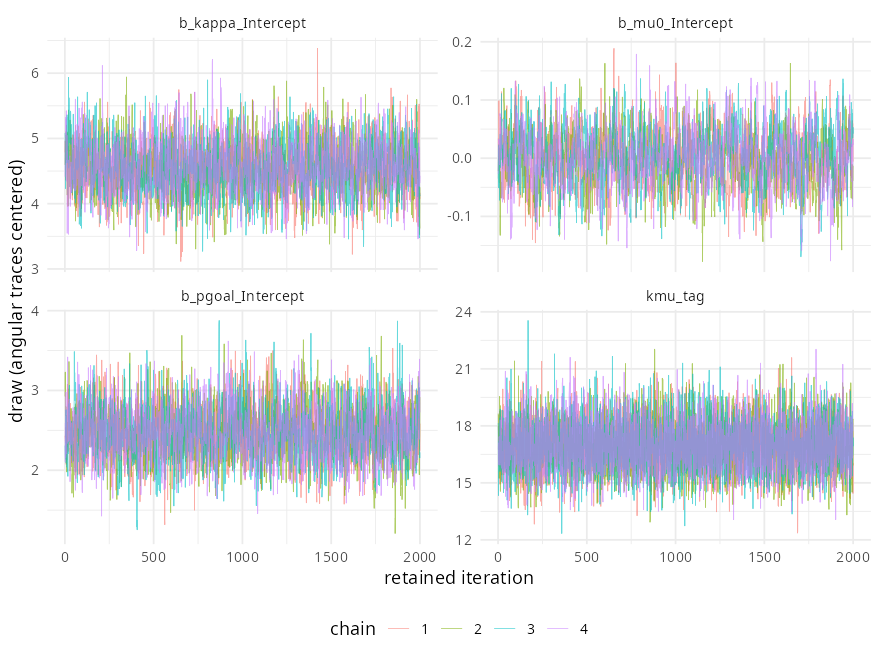

In [26]:
save_figure(trace_plot(fit_mix, c("b_mu0_Intercept", "b_kappa_Intercept", "b_pgoal_Intercept", "kmu_tag"), mix_angular), "mixture_trace", 8, 6)


Sampling summary for the vMU fit (check ESS / $\hat{R}$ before interpreting).


In [27]:
response_parameters <- function(fit, newdata, mixture = FALSE,
                                population = FALSE, draw_ids = NULL) {
  # brms returns [draws x grid]; transpose explicitly to [grid x draws].
  get_lp <- function(dpar = NULL, nlpar = NULL, transform = FALSE) {
    t(posterior_linpred(fit, newdata = newdata, dpar = dpar, nlpar = nlpar,
      transform = transform, re_formula = if (population) NA else NULL,
      draw_ids = draw_ids))
  }
  if (population) {
    # Circular tag vectors are nonlinear population coefficients, so a
    # re_formula alone cannot exclude them. Evaluate the relevant nlpars.
    mu <- if (mixture) get_lp(nlpar = "mu0") + get_lp(nlpar = "mutreat") else get_lp(nlpar = "beta0")
  } else {
    mu <- get_lp(dpar = "mu")
  }
  kappa <- get_lp(dpar = "kappa", transform = TRUE)
  p <- if (mixture) get_lp(dpar = "pgoal", transform = TRUE) else matrix(1, nrow(mu), ncol(mu))
  stopifnot(nrow(mu) == nrow(newdata), identical(dim(mu), dim(kappa)),
            identical(dim(mu), dim(p)), all(kappa > 0), all(p >= 0 & p <= 1))
  list(mu = wrap(mu), kappa = kappa, p = p)
}
population_grid <- data.frame(treatment = factor(1:4, levels = 1:4),
                              tag = factor(levels(df_track$tag)[1], levels = levels(df_track$tag)))
for (t in 2:4) population_grid[[paste0("treat", t)]] <- as.integer(population_grid$treatment == as.character(t))
set.seed(123)
PLOT_DRAWS <- if (quick_run) 200L else 2000L
plot_vm_ids <- sample.int(posterior::ndraws(posterior::as_draws_array(fit_vm)), PLOT_DRAWS)
plot_mix_ids <- sample.int(posterior::ndraws(posterior::as_draws_array(fit_mix)), PLOT_DRAWS)
pop_vm <- response_parameters(fit_vm, population_grid, population = TRUE, draw_ids = plot_vm_ids)
pop_mix <- response_parameters(fit_mix, population_grid, mixture = TRUE,
  population = TRUE, draw_ids = plot_mix_ids)
tag_grid <- df_track[!duplicated(df_track$tag), c("tag", "treatment", "treat2", "treat3", "treat4")]
tag_grid <- tag_grid[order(tag_grid$tag), ]
tag_mix <- response_parameters(fit_mix, tag_grid, mixture = TRUE, draw_ids = plot_mix_ids)


In [28]:
explicit_loo <- function(fit, mixture = FALSE) {
  d <- posterior::as_draws_df(fit)
  ll <- matrix(0, nrow = nrow(d), ncol = nrow(df_track))
  for (start in seq.int(1L, nrow(df_track), by = 128L)) {
    ii <- seq.int(start, min(start + 127L, nrow(df_track)))
    block <- df_track[ii, , drop = FALSE]
    par <- response_parameters(fit, block, mixture = mixture)
    y <- matrix(rep(block$HeadingRadians, ncol(par$mu)), nrow = length(ii))
    log_goal <- vm_logpdf(y, par$mu, par$kappa)
    if (mixture) {
      a <- log(par$p) + log_goal
      b <- log1p(-par$p) - log(2 * pi)
      maximum <- pmax(a, b)
      log_density <- maximum + log(exp(a - maximum) + exp(b - maximum))
    } else {
      log_density <- log_goal
    }
    ll[, ii] <- t(log_density)
  }
  # Scale each likelihood column before exponentiating; relative_eff is
  # invariant to this scaling. Preserve chain IDs rather than flattening.
  likelihood <- exp(sweep(ll, 2, apply(ll, 2, max), "-"))
  r_eff <- loo::relative_eff(likelihood, chain_id = d[[".chain"]])
  loo::loo(ll, r_eff = r_eff)
}
loo_vm <- explicit_loo(fit_vm)
loo_mix <- explicit_loo(fit_mix, mixture = TRUE)
loo_objects <- list("von Mises" = loo_vm, "von Mises-Uniform" = loo_mix)
res_total <- do.call(rbind, lapply(names(loo_objects), function(name) {
  x <- loo_objects[[name]]
  data.frame(model = name, elpd = x$estimates["elpd_loo", "Estimate"],
    se_elpd = x$estimates["elpd_loo", "SE"], pareto_k_max = max(x$diagnostics$pareto_k),
    pareto_n_gt_0.7 = sum(x$diagnostics$pareto_k > 0.7))
}))
res_total <- res_total[order(res_total$elpd, decreasing = TRUE), ]
print(res_total)
pointwise_delta <- loo_mix$pointwise[, "elpd_loo"] - loo_vm$pointwise[, "elpd_loo"]
delta_row <- function(ii, label) {
  delta <- pointwise_delta[ii]
  data.frame(label = label, n = length(ii), delta_elpd = sum(delta),
    se_delta_elpd = if (length(ii) > 1L) sqrt(length(ii) * var(delta)) else NA_real_)
}
delta_df <- rbind(delta_row(seq_len(nrow(df_track)), "Total"),
  do.call(rbind, lapply(levels(df_track$treatment), function(t) {
    delta_row(which(df_track$treatment == t), treatment_nice[[t]])
  })))
print(delta_df)
delta_individual <- do.call(rbind, lapply(split(seq_len(nrow(df_track)), df_track$tag), function(ii) {
  data.frame(tag = as.character(df_track$tag[ii[1]]), treatment = df_track$treatment[ii[1]],
    delta_row(ii, as.character(df_track$tag[ii[1]])))
}))
# Minimal black-and-white ELPD panels (Python twin look): best model on
# top, dashed line at the best total ELPD, no grid, bottom/left axes only.
total_elpd_panel <- function(vline = TRUE, xlabel = "PSIS-LOO ELPD") {
  best <- res_total$elpd[which.max(res_total$elpd)]
  p <- ggplot(res_total, aes(elpd, reorder(model, elpd))) +
    geom_errorbar(aes(xmin = elpd - se_elpd, xmax = elpd + se_elpd),
      orientation = "y", width = 0.15, linewidth = 0.35) +
    geom_point(size = 2)
  if (vline) p <- p + geom_vline(xintercept = best, linetype = "dashed", linewidth = 0.3)
  p + theme_classic(base_size = 9) +
    labs(x = xlabel, y = "")
}
p_total <- total_elpd_panel(FALSE, "ELPD")
# Total + per-treatment deltas: Total row on top (black), treatments in
# tab10 below, named y ticks, dashed line at zero.
delta_df$ypos <- seq(0L, 4L * 1.35, by = 1.35)  # Total row 0, treatments below
delta_df$rcol <- c("black", treatment_colors[as.character(levels(df_track$treatment))])
p_delta <- ggplot(delta_df, aes(delta_elpd, ypos)) +
  geom_errorbar(aes(xmin = delta_elpd - se_delta_elpd, xmax = delta_elpd + se_delta_elpd,
    colour = rcol), orientation = "y", width = 0.18, linewidth = 0.35) +
  geom_point(aes(colour = rcol), size = 2.2) +
  geom_vline(xintercept = 0, linetype = "dashed", linewidth = 0.3) +
  scale_y_reverse(limits = c(-0.41, 4 * 1.35 + 0.41),
    breaks = delta_df$ypos, labels = delta_df$label, expand = c(0, 0)) +
  scale_x_continuous(expand = expansion(mult = c(0.06, 0.06))) +
  scale_colour_identity(guide = "none") +
  theme_classic(base_size = 9) +
  labs(x = "ELPD difference", y = "")
# Bracket panel for the combined summaries: colorblind treatment rows,
# only the "Total" tick, a left-hand bracket over the treatment rows and
# a left margin wide enough to hold the "Within-treatment" label.
brk <- delta_df
brk$rcol <- c("black", treatment_colors_cb[as.character(levels(df_track$treatment))])
gx <- range(c(brk$delta_elpd - brk$se_delta_elpd, brk$delta_elpd + brk$se_delta_elpd))
padx <- 0.06 * diff(gx)
xlim_b <- c(gx[1] - padx - 0.30 * diff(range(gx)), gx[2] + padx)
xb <- xlim_b[1] + 0.004 * diff(xlim_b)
cap_w <- 0.020 * diff(xlim_b)
p_bracket <- ggplot(brk, aes(delta_elpd, ypos)) +
  geom_vline(xintercept = 0, linetype = "dashed", linewidth = 0.3) +
  geom_errorbar(aes(xmin = delta_elpd - se_delta_elpd, xmax = delta_elpd + se_delta_elpd,
    colour = rcol), orientation = "y", width = 0.18, linewidth = 0.35) +
  geom_point(aes(colour = rcol), size = 2.2) +
  annotate("segment", x = xb, y = 1.35, xend = xb, yend = 4 * 1.35,
    linewidth = 0.35, colour = "black") +
  annotate("segment", x = xb, y = 1.35, xend = xb + cap_w, yend = 1.35,
    linewidth = 0.35, colour = "black") +
  annotate("segment", x = xb, y = 4 * 1.35, xend = xb + cap_w, yend = 4 * 1.35,
    linewidth = 0.35, colour = "black") +
  annotate("text", x = xb - 0.012 * diff(xlim_b), y = 2.7,
    label = "Within-treatment", size = 3.4, colour = "black",
    hjust = 1, vjust = 0.5) +
  scale_y_reverse(limits = c(-0.54, 4 * 1.35 + 0.54), breaks = 0,
    labels = "Total", expand = c(0, 0)) +
  scale_x_continuous(limits = xlim_b, oob = scales::oob_keep) +
  coord_cartesian(clip = "off") +
  scale_colour_identity(guide = "none") +
  theme_classic(base_size = 9) +
  labs(x = "ELPD difference", y = "")
p_combined3 <- patchwork::wrap_plots(p_total, p_bracket, ncol = 1,
  heights = c(1.25, 1.35))
# Per-animal deltas, one colorblind panel per treatment (named).
tlabels_all <- levels(df_track$treatment)
delta_individual$tlabel <- factor(treatment_nice[as.character(delta_individual$treatment)],
  levels = treatment_nice[levels(df_track$treatment)])
di_grid <- range(c(delta_individual$delta_elpd - delta_individual$se_delta_elpd,
  delta_individual$delta_elpd + delta_individual$se_delta_elpd))
di_pad <- 0.06 * diff(di_grid)
p_delta_individual <- ggplot(delta_individual,
  aes(delta_elpd, reorder(tag, delta_elpd), colour = treatment)) +
  geom_errorbar(aes(xmin = delta_elpd - se_delta_elpd, xmax = delta_elpd + se_delta_elpd),
    orientation = "y", width = 0.15, linewidth = 0.3) +
  geom_point(size = 1.4) +
  facet_wrap(~ tlabel, ncol = 4, scales = "free_y") +
  geom_vline(xintercept = 0, linetype = "dashed", linewidth = 0.3) +
  scale_colour_manual(values = treatment_colors_cb[tlabels_all], guide = "none") +
  scale_x_continuous(limits = di_grid - c(di_pad, -di_pad), expand = c(0, 0)) +
  labs(x = "ELPD difference (vMU - vM)", y = "") +
  theme_classic(base_size = 8) + theme(strip.background = element_blank(),
    strip.text = element_text(size = 9))


              model      elpd  se_elpd pareto_k_max pareto_n_gt_0.7
2 von Mises-Uniform -6710.283 60.28762    0.4565785               0
1         von Mises -6829.407 59.29446    0.5429657               0


                       label    n delta_elpd se_delta_elpd
1                      Total 4942 119.123875     17.206374
2                    Control 1511  67.220196     12.840285
3                  Eye cover 1199  19.612736      7.024313
4          Eye cover, Magnet 1162  33.788584      8.496220
5 Anosmia, Eye cover, Magnet 1070  -1.497641      2.897504


In [29]:
KAPPA_UNIFORM <- 1e-6
# Preserve the source post-hoc helpers' near-uniform proxy in display/PPC
# summaries. The fitted mixture likelihood and responsibilities use the
# exact uniform-circle density, as in Python c53 and the responsibility helper.
mass_vm <- function(mu, kappa, half_width = pi / 4, grid_n = 721L) {
  theta <- seq(-half_width, half_width, length.out = grid_n)
  weights <- c(0.5, rep(1, grid_n - 2L), 0.5) * diff(theta)[1]
  value <- numeric(length(mu))
  for (j in seq_along(theta)) value <- value + weights[j] * exp(vm_logpdf(theta[j], mu, kappa))
  value
}
parameter_summary <- function(par, grid) {
  do.call(rbind, lapply(seq_len(nrow(grid)), function(j) {
    mu <- par$mu[j, ]
    k <- par$kappa[j, ]
    p <- par$p[j, ]
    f_dir <- exp(vm_logpdf(0, mu, k))
    f_unif <- exp(vm_logpdf(0, 0, KAPPA_UNIFORM))
    values <- list(mu = mu, p = p, kappa = k, mrl = A1_safe(k),
      dens0_dir = f_dir, dens0_mix = p * f_dir + (1 - p) * f_unif,
      mass45 = p * mass_vm(mu, k) + (1 - p) * 0.25,
      align0 = p * A1_safe(k) * cos(mu) + (1 - p) * A1_safe(KAPPA_UNIFORM))
    do.call(rbind, lapply(names(values), function(q) {
      data.frame(grid[j, , drop = FALSE], quantity = q,
        as.list(interval(values[[q]], angular = q == "mu")))
    }))
  }))
}
pop_summary <- parameter_summary(pop_mix, population_grid)
tag_summary <- parameter_summary(tag_mix, tag_grid)
vm_summary <- parameter_summary(pop_vm, population_grid)
# Twin look: colorblind rows, hidden treatment ticks/labels, twin x label
# and reference line. (Python plot_mean_hdi_horizontal, no-labels variant.)
mean_hdi_plot <- function(table, quantity, label, reference = NULL, xlimits = NULL,
  flip = FALSE) {
  x <- table[table$quantity == quantity, ]
  p <- ggplot(x, aes(mean, treatment, colour = treatment)) +
    geom_errorbar(aes(xmin = low, xmax = high), orientation = "y", width = 0.18,
      linewidth = 0.4) +
    geom_point(size = 1.9) +
    scale_colour_manual(values = treatment_colors_cb[tlabels_all], guide = "none") +
    scale_y_discrete(
      limits = if (flip) levels(df_track$treatment)
               else rev(levels(df_track$treatment)), labels = "") +
    labs(x = label, y = "") +
    theme_classic(base_size = 9) +
    theme(axis.text.y = element_blank(), axis.ticks.y = element_blank(),
      plot.margin = margin(5.5, 12, 5.5, 5.5))
  if (!is.null(reference)) p <- p + geom_vline(xintercept = reference, linetype = "dashed")
  if (!is.null(xlimits)) p <- p + scale_x_continuous(limits = xlimits, expand = c(0, 0))
  p
}
# Twin look: one row of four named panels, animals sorted by value within
# each, a light-gray population HDI band with a solid population-mean
# line, optional dashed reference, one shared x-axis + figure label.
tag_hdi_plot <- function(quantity, label, reference = NULL, xlimits = NULL) {
  x <- tag_summary[tag_summary$quantity == quantity, ]
  pop <- pop_summary[pop_summary$quantity == quantity, ]
  lv <- tlabels_all
  if (is.null(xlimits)) {
    gr <- range(c(min(x$low, pop$low), max(x$high, pop$high)))
    if (!is.null(reference)) gr <- range(c(gr, reference))
    pd <- 0.06 * diff(gr)
    xlimits <- gr - c(pd, -pd)
  }
  panels <- lapply(lv, function(t) {
    sub <- x[x$treatment == t, ]
    sub <- sub[order(sub$mean, decreasing = TRUE), ]
    ny <- nrow(sub)
    poprow <- pop[pop$treatment == t, ]
    panel <- ggplot(sub, aes(mean, y = seq_len(ny))) +
      annotate("rect", xmin = poprow$low, xmax = poprow$high,
        ymin = 0.5, ymax = ny + 0.5,
        fill = "#d9d9d9", colour = NA, inherit.aes = FALSE) +
      geom_vline(xintercept = poprow$mean, linewidth = 0.3, colour = "#000000") +
      geom_errorbar(aes(xmin = low, xmax = high, colour = treatment),
        orientation = "y", width = 0.22, linewidth = 0.3) +
      geom_point(aes(colour = treatment), size = 1.5) +
      scale_colour_manual(values = treatment_colors_cb[tlabels_all], guide = "none") +
      scale_y_reverse(limits = c(0.5, ny + 0.5), expand = c(0, 0),
        breaks = seq_len(ny), labels = as.character(sub$tag)) +
      scale_x_continuous(limits = xlimits, expand = c(0, 0)) +
      labs(title = treatment_nice[[t]], x = label, y = "") +
      theme_classic(base_size = 8) +
      theme(plot.title = element_text(size = 9, hjust = 0.5))
    if (!is.null(reference)) {
      panel <- panel + geom_vline(xintercept = reference,
        linetype = "dashed", linewidth = 0.3)
    }
    panel
  })
  patchwork::wrap_plots(panels[[1]], panels[[2]], panels[[3]], panels[[4]],
    ncol = 4, axis_titles = "collect_x")
}
# Baseline coefficient panels: actual intercept/contrasts, not conditional
# response parameters. Angular intervals are centered on their circular mean.
base_draws <- as.data.frame(posterior::as_draws_df(fit_vm))
base_coef_names <- c("b_beta0_Intercept", paste0("b_beta0_treat", 2:4),
                      "b_kappa_Intercept", paste0("b_kappa_treat", 2:4))
base_coef <- do.call(rbind, lapply(base_coef_names, function(name) {
  angular <- grepl("b_beta0", name, fixed = TRUE)
  data.frame(parameter = name, component = if (angular) "mu (rad)" else "kappa (pre-softplus)",
    as.list(interval(base_draws[[name]], angular = angular)))
}))
# Twin layout: one panel; "Control (Intercept)" + formatted rows colored
# tab10; mu diamonds above each row (circular wrap) and kappa triangles
# below; dashed zero line; mu/kappa legend at the lower right.
coef_lab <- c("Control (Intercept)", treatment_nice[tlabels_all[-1]])
coef_pt <- do.call(rbind, lapply(seq_along(tlabels_all), function(i) {
  mn <- paste0("b_beta0_", c("Intercept", paste0("treat", 2:4))[i])
  kn <- paste0("b_kappa_", c("Intercept", paste0("treat", 2:4))[i])
  mid <- as.list(interval(base_draws[[mn]], angular = TRUE))
  kid <- as.list(interval(base_draws[[kn]]))
  rbind(data.frame(label = coef_lab[i], treatment = tlabels_all[i],
      comp = "mu", x = mid$mean, low = mid$low, high = mid$high, y = i - 0.16),
    data.frame(label = coef_lab[i], treatment = tlabels_all[i],
      comp = "kappa", x = kid$mean, low = kid$low, high = kid$high, y = i + 0.16))
}))
# Explicit x limits (ggplot2's default 5% multiplicative padding) give the
# hand-drawn legend box stable data coordinates.
cb_raw <- range(c(coef_pt$low, coef_pt$high))
cspan_c <- diff(cb_raw)
cband_lim <- cb_raw + c(-0.05, 0.05) * cspan_c
p_base_coef <- ggplot(coef_pt, aes(x, y)) +
  geom_vline(xintercept = 0, linetype = "dashed", linewidth = 0.3) +
  geom_errorbarh(aes(xmin = low, xmax = high, colour = treatment),
    height = 0.18, linewidth = 0.3) +
  geom_point(aes(colour = treatment, shape = comp), size = 1.9) +
  scale_shape_manual(values = c(mu = 18, kappa = 17), guide = "none") +
  scale_colour_manual(values = treatment_colors[tlabels_all], guide = "none") +
  scale_y_reverse(limits = c(0.5, length(coef_lab) + 0.5),
    breaks = seq_along(coef_lab), labels = coef_lab, expand = c(0, 0)) +
  scale_x_continuous(limits = cband_lim, expand = c(0, 0)) +
  # Framed legend, drawn by hand (this ggplot2 build drops
  # legend.position = "bottomright" without an error).
  annotate("rect", xmin = cband_lim[1] + 0.55 * cspan_c,
    xmax = cband_lim[2] - 0.04 * cspan_c, ymin = 2.95, ymax = 4.35,
    fill = "white", colour = "grey40", linewidth = 0.4) +
  annotate("point", x = cband_lim[1] + 0.63 * cspan_c, y = 3.35,
    shape = 18, size = 2.6) +
  annotate("text", x = cband_lim[1] + 0.82 * cspan_c, y = 3.35,
    label = "\u03bc", hjust = 0.5, vjust = 0.5, size = 3.0) +
  annotate("point", x = cband_lim[1] + 0.63 * cspan_c, y = 3.98,
    shape = 17, size = 2.6) +
  annotate("text", x = cband_lim[1] + 0.82 * cspan_c, y = 3.98,
    label = "\u03ba", hjust = 0.5, vjust = 0.5, size = 3.0) +
  theme_classic(base_size = 9) +
  labs(x = "Coefficient value", y = "")
vd <- vm_summary[vm_summary$quantity == "dens0_dir", ]
vd_lim <- range(c(min(vd$low, 1 / (2 * pi)), max(vd$high, 1 / (2 * pi))))
padvd <- 0.10 * diff(vd_lim)
p_base_density <- mean_hdi_plot(vm_summary, "dens0_dir", "Predictive density",
  1 / (2 * pi), vd_lim - c(padvd, -padvd))

theta <- seq(0, 2 * pi, length.out = 361)
polar_pdf <- do.call(rbind, lapply(seq_len(nrow(population_grid)), function(j) {
  do.call(rbind, lapply(theta, function(t) {
    pdf <- pop_mix$p[j, ] * exp(vm_logpdf(t, pop_mix$mu[j, ], pop_mix$kappa[j, ])) +
      (1 - pop_mix$p[j, ]) * exp(vm_logpdf(t, 0, KAPPA_UNIFORM))
    data.frame(treatment = population_grid$treatment[j], theta = t,
      median = median(pdf), as.list(hdi(pdf)))
  }))
}))
# Polar mixture panels follow the Python twin: 0 deg at the top, rotating
# clockwise; the radius is 1 + pdf/peak_max, where peak_max is the shared
# peak of every panel's 95% band upper bound, so density zero sits on the
# ring at radius 1 and the shared peak on the ring at radius 2.
# Colourblind treatment colours, 95% band at the twin's 0.35 opacity, no
# angle labels; the rings and the 0-deg spoke are drawn explicitly.
peak_max_mix <- max(polar_pdf$high)
polar_pdf$r_med <- 1 + polar_pdf$median / peak_max_mix
polar_pdf$r_low <- 1 + polar_pdf$low / peak_max_mix
polar_pdf$r_high <- 1 + polar_pdf$high / peak_max_mix
rmax_mix <- 2.05
mix_ring <- function(r) data.frame(theta = seq(0, 2 * pi, length.out = 361L), r = r)
p_mixture_polar <- ggplot(polar_pdf, aes(theta, r_med, colour = treatment, group = treatment)) +
  geom_ribbon(aes(ymin = r_low, ymax = r_high, fill = treatment), alpha = 0.35, colour = NA) +
  geom_path(linewidth = 0.5) +
  geom_path(data = mix_ring(1), inherit.aes = FALSE, aes(theta, r),
    colour = "grey55", linewidth = 0.25) +
  geom_path(data = mix_ring(2), inherit.aes = FALSE, aes(theta, r),
    colour = "grey75", linewidth = 0.25) +
  geom_path(data = data.frame(theta = c(0, 0), r = c(1, rmax_mix)),
    inherit.aes = FALSE, aes(theta, r), colour = "grey70", linewidth = 0.3) +
  facet_wrap(~ treatment) +
  scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0), breaks = NULL) +
  coord_polar() +
  scale_y_continuous(limits = c(0, rmax_mix), expand = c(0, 0)) +
  scale_colour_manual(values = treatment_colors_cb) +
  scale_fill_manual(values = treatment_colors_cb) +
  labs(x = "", y = "") +
  theme(legend.position = "none", strip.text = element_blank(),
    strip.background = element_blank(), axis.text.y = element_blank(),
    axis.ticks.y = element_blank(), panel.grid.major = element_blank(),
    panel.grid.minor = element_blank())
# Circular mean angle in degrees (interval in radians, scaled for display).
mudeg_pt <- do.call(rbind, lapply(seq_len(nrow(population_grid)), function(j) {
  md <- as.list(interval(pop_mix$mu[j, ], angular = TRUE))
  data.frame(treatment = population_grid$treatment[j], quantity = "mu_deg",
    mean = md$mean * 180 / pi, low = md$low * 180 / pi, high = md$high * 180 / pi)
}))
dens_xlim <- c(0, 1.05 * max(pop_summary$high[pop_summary$quantity == "dens0_dir"],
  vm_summary$high[vm_summary$quantity == "dens0_dir"]))
p_weight <- mean_hdi_plot(pop_summary, "p", "Mixture weight", 0.5, c(0, 1))
p_kappa <- mean_hdi_plot(pop_summary, "kappa", "Concentration (\u03ba)")
p_mix_density <- mean_hdi_plot(pop_summary, "dens0_mix",
  "Predictive density (mixture)", 1 / (2 * pi), dens_xlim)
p_dir_density <- mean_hdi_plot(pop_summary, "dens0_dir",
  "Predictive density (directed component)", 1 / (2 * pi), dens_xlim)
p_mass <- mean_hdi_plot(pop_summary, "mass45", "Predictive mass (\u00b145\u00b0)",
  0.25, c(0, 1))
p_align <- mean_hdi_plot(pop_summary, "align0", "Alignment", NULL, c(0, 1))
p_mu_deg <- mean_hdi_plot(mudeg_pt, "mu_deg", "Mean angle (deg)", 0)
p_mrl <- mean_hdi_plot(pop_summary, "mrl", "MRL (directed component)", 0, c(0, 1))
# The 2x2 twin places treatment rows control-on-bottom: flipped copies of
# the four quadrant plots (the standalone saves keep control-on-top).
p_mu_deg_f <- mean_hdi_plot(mudeg_pt, "mu_deg", "Mean angle (deg)", 0, flip = TRUE)
p_weight_f <- mean_hdi_plot(pop_summary, "p", "Mixture weight", 0.5, c(0, 1),
  flip = TRUE)
p_mrl_f <- mean_hdi_plot(pop_summary, "mrl", "MRL (directed component)", 0, c(0, 1),
  flip = TRUE)
p_dir_density_f <- mean_hdi_plot(pop_summary, "dens0_dir",
  "Predictive density", 1 / (2 * pi), dens_xlim, flip = TRUE)
# Matched vMU-vs-vM comparison: shared x limits over both summaries
# (including the uniform line) plus the 10% twin padding.
shm <- c(min(vd_lim[1], vd_lim[2],
    min(pop_summary$low[pop_summary$quantity == "dens0_dir"], 1 / (2 * pi))),
  max(vd_lim[2], max(pop_summary$high[pop_summary$quantity == "dens0_dir"],
    1 / (2 * pi))))
padshm <- 0.10 * diff(shm)
shm_lim <- shm - c(padshm, -padshm)
# 3-panel predictive limit: mixture summary + uniform line, 10% padding.
plim <- range(c(pop_summary$low[pop_summary$quantity == "dens0_mix"],
  pop_summary$high[pop_summary$quantity == "dens0_mix"], 1 / (2 * pi)))
padpl <- 0.10 * diff(plim)
plim <- plim - c(padpl, -padpl)


Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”


Treatment coefficients for the mu and kappa submodels (vM baseline).


`height` was translated to `width`.


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'μ' in 'mbcsToSbcs': for μ (U+03BC)”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'κ' in 'mbcsToSbcs': for κ (U+03BA)”


`height` was translated to `width`.


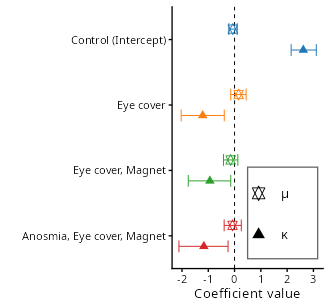

In [30]:
save_figure(p_base_coef, "treatment_coefficients_mu_kappa", 3.0, 2.8)


Posterior predictive density at the goal direction ($0^\circ$, i.e. straight toward the goal) by
treatment for the vM baseline.


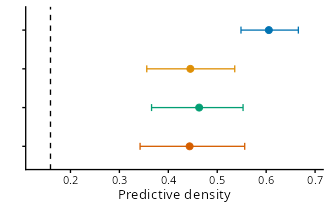

In [31]:
save_figure(p_base_density, "treatment_pred_density_at0_mu_kappa", 3.0, 1.9)


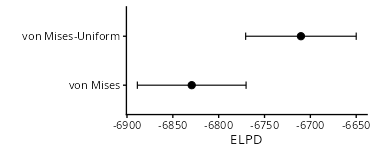

In [32]:
save_figure(p_total, "psisloo_total_elpd_all_models", 3.4, 1.4)


Compute **$\Delta$ELPD = vMU $-$ vM** with PSIS-LOO, total and stratified by treatment, with the SE of
the total. A positive value means the mixture predicts goal-relative headings better out of sample;
it is the evidence for a non-trivial undirected component.


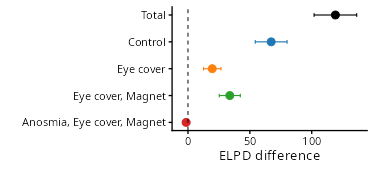

In [33]:
save_figure(p_delta, "psisloo_delta_total_and_by_treatment_vMU_minus_vM", 3.4, 1.55)


Total ELPD by model (vMU vs vM), best first.


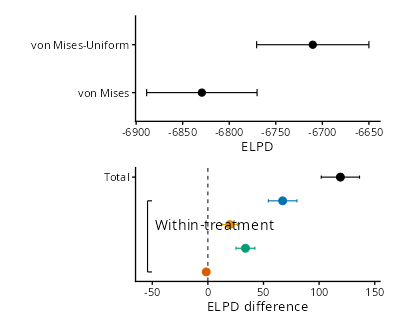

In [34]:
# Combined two-panel figure (Python twin look): total ELPD by model on
# top, the total delta point plus a "Within-treatment" bracket over the
# per-treatment deltas (colorblind) below.
save_figure(p_combined3, "psisloo_combined", 3.6, 3.0)


Pointwise $\Delta$ELPD (vMU $-$ vM) by animal and by treatment — the vMU advantage can be concentrated
in a subset of animals.


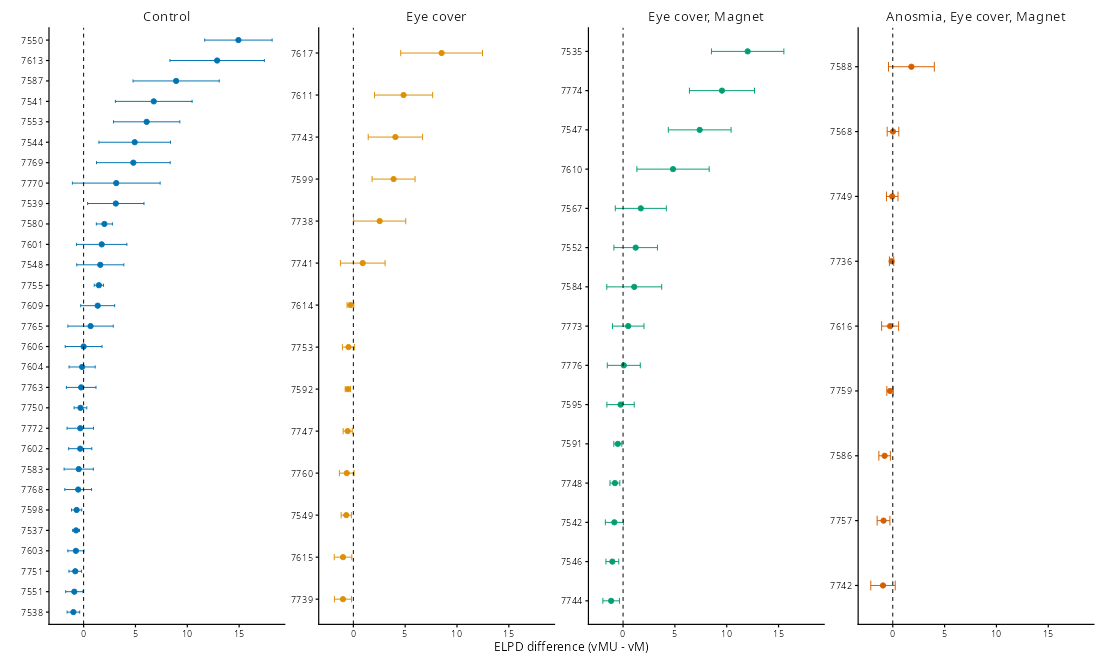

In [35]:
save_figure(p_delta_individual, "psisloo_delta_by_individual_by_treatment_vMU_minus_vM", 10, 6)


## 7. vMU population-level summaries

Population-level vMU summaries: per-treatment polar densities of the goal-relative bearings, showing
the directed + undirected mixture.


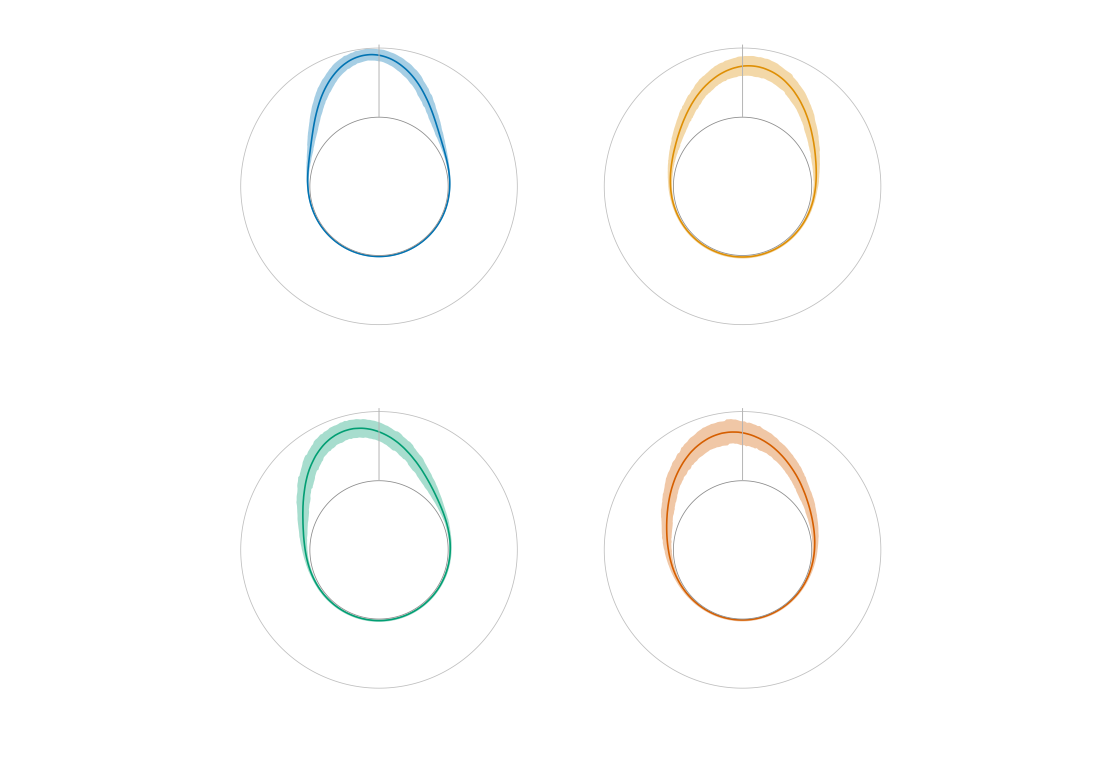

In [36]:
save_figure(p_mixture_polar, "vmum_mixture_full_polar_pdfs_population_only", 10, 7)


Per-treatment population **mixture weight** $p$ (probability a step is goal-directed), goal-directed
alignment to $0^\circ$, and goal-directed $\kappa$, each with posterior means and HDIs.


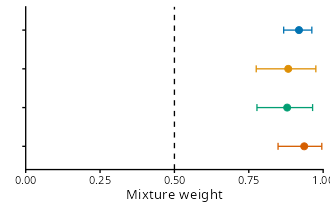

In [37]:
save_figure(p_weight, "fullmodel_mixture_weight_by_treatment_mean_hdi", 3.0, 1.9)


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Concentration (κ)' in 'mbcsToSbcs': for κ (U+03BA)”


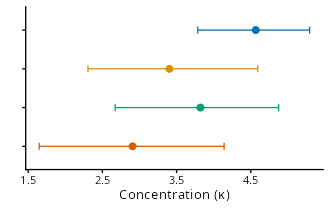

In [38]:
save_figure(p_kappa, "fullmodel_kappa_by_treatment_mean_hdi", 3.0, 1.9)


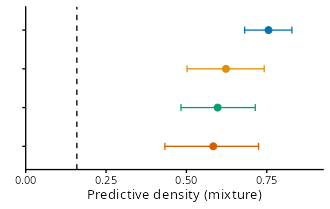

In [39]:
save_figure(p_mix_density, "fullmodel_predictive_density_at_0_mixture_by_treatment_mean_hdi", 3.0, 1.9)


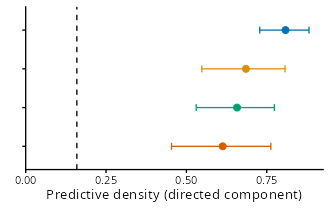

In [40]:
save_figure(p_dir_density, "fullmodel_predictive_density_at_0_directed_component_by_treatment_mean_hdi", 3.0, 1.9)


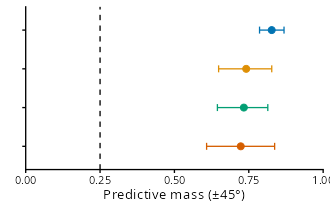

In [41]:
save_figure(p_mass, "fullmodel_predictive_mass_pm45deg_by_treatment_mean_hdi", 3.0, 1.9)


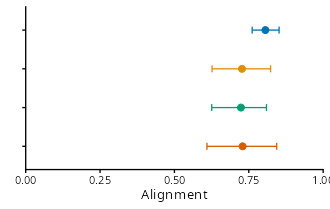

In [42]:
save_figure(p_align, "fullmodel_alignment_to_zero_by_treatment_mean_hdi", 3.0, 1.9)


Combined 2x2 summary plot of the out-of-sample comparison against the population-level vMU
parameters.


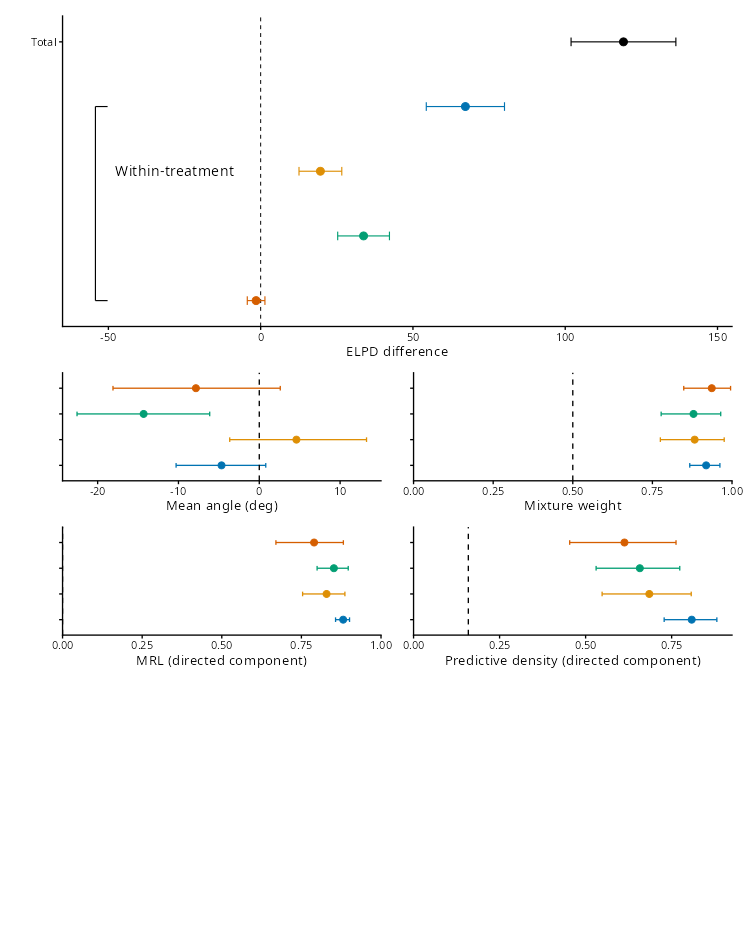

In [43]:
# Combined summary (Python twin): the delta-bracket panel on top with
# the population vMU parameters in a 2x2 block below (mean angle in
# degrees, mixture weight, MRL, directed-component predictive density);
# bottom panels hide the treatment labels so rows align across columns.
p_2x2 <- patchwork::wrap_plots(
  p_bracket,
  (p_mu_deg_f | p_weight_f) / (p_mrl_f | p_dir_density_f),
  ncol = 1)
p_2x2 <- p_2x2 + plot_layout(heights = c(1.45, 2.45))
save_figure(p_2x2, "psisloo_plus_params_2x2", 6.8, 8.6)


Per-treatment predicted posterior density at the goal direction for the vMU (analog of the vM
baseline figure above).


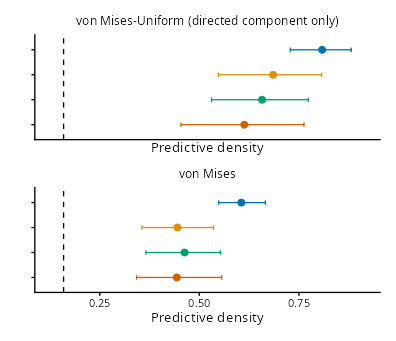

In [44]:
# Matched two-panel comparison (Python twin): the vMU model's
# directed-component-only predictive density at the goal (top) vs the
# von Mises baseline (bottom); shared x limits, hidden treatment labels,
# dashed uniform-density reference.
p_vmu_dens <- mean_hdi_plot(pop_summary, "dens0_dir", "Predictive density",
  1 / (2 * pi), shm_lim) +
  labs(title = "von Mises-Uniform (directed component only)") +
  theme(plot.title = element_text(size = 8, hjust = 0.5),
    axis.text.x = element_blank(), axis.ticks.x = element_blank())
p_vm_dens <- mean_hdi_plot(vm_summary, "dens0_dir", "Predictive density",
  1 / (2 * pi), shm_lim) +
  labs(title = "von Mises") +
  theme(plot.title = element_text(size = 8, hjust = 0.5))
save_figure(patchwork::wrap_plots(p_vmu_dens, p_vm_dens, ncol = 1),
  "predictive_density_two_model_comparison_matched_vmu_directed_vs_vm",
  3.6, 3.1)


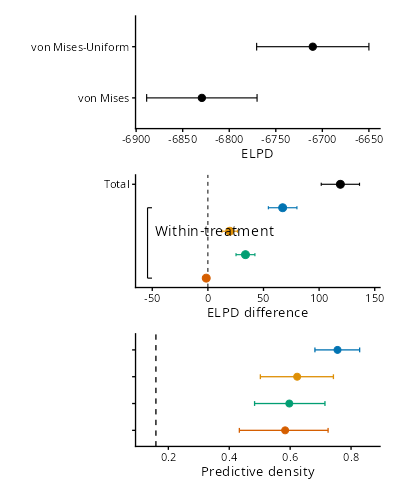

In [45]:
# Three-panel summary (Python twin): total ELPD by model, the delta
# ELPD bracket panel, and the vMU mixture predictive density at the goal
# (hidden treatment labels, dashed uniform reference).
p_p3 <- mean_hdi_plot(pop_summary, "dens0_mix", "Predictive density",
  1 / (2 * pi), plim)
p_3panel <- patchwork::wrap_plots(p_total, p_bracket, p_p3, ncol = 1)
save_figure(p_3panel, "psisloo_plus_predictive_density_3panel", 3.6, 4.5)


## 8. Per-animal level

Helpers plus **per-animal (tag-level)** vMU summaries: each bat's mixture weight, goal-directed
alignment, and $\kappa$. This is where pronounced between-animal heterogeneity becomes visible.


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


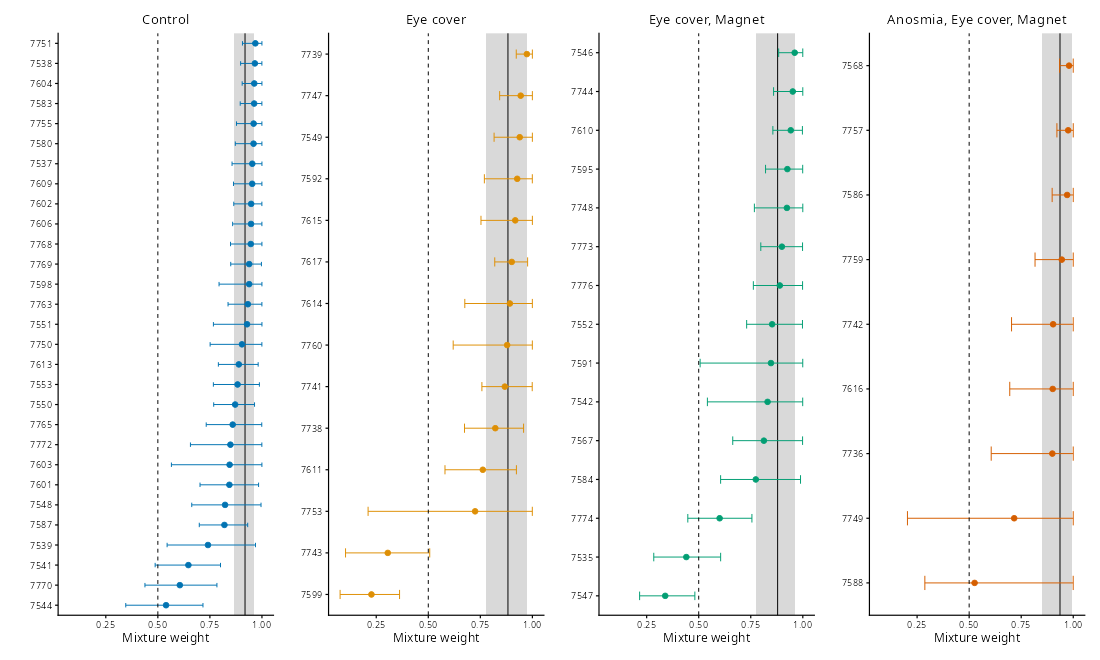

In [46]:
save_figure(tag_hdi_plot("p", "Mixture weight", 0.5, xlimits = c(0, 1)), "fullmodel_taglevel_mixture_weight_by_treatment_mean_hdi", 10, 6)


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


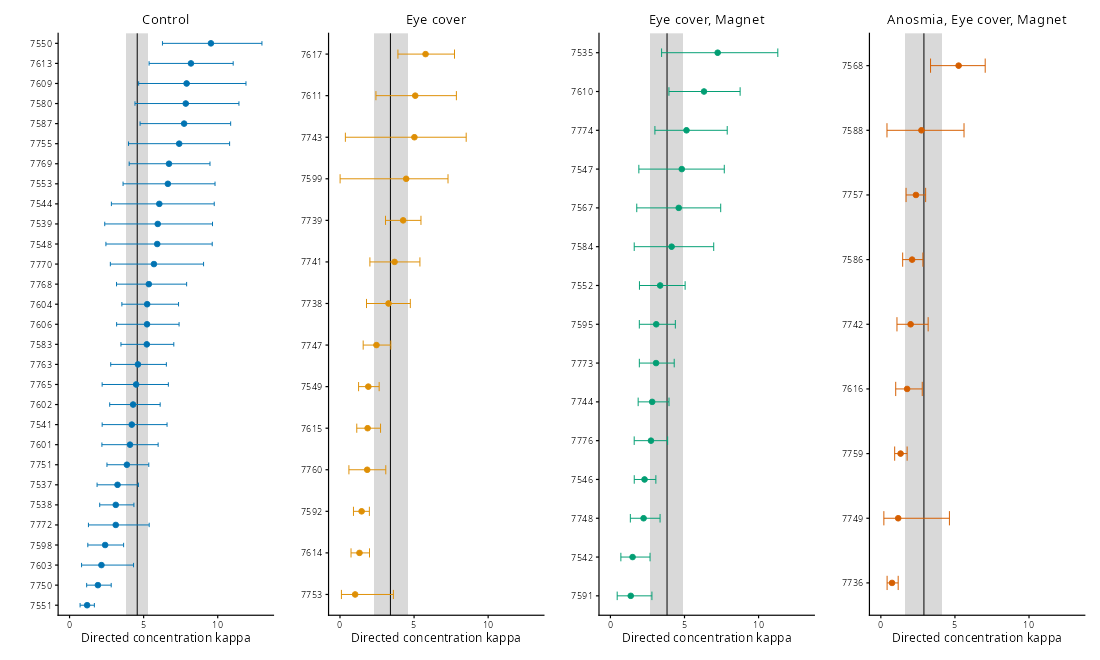

In [47]:
save_figure(tag_hdi_plot("kappa", expression("Concentration (" * kappa * ")")), "fullmodel_taglevel_kappa_by_treatment_mean_hdi", 10, 6)


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


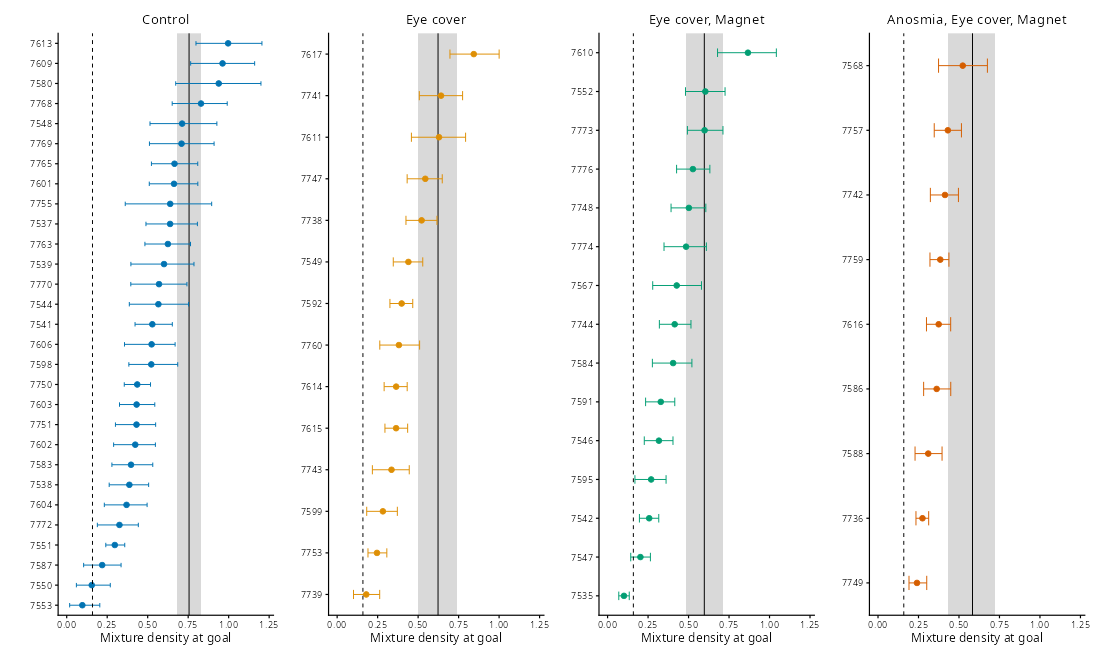

In [48]:
save_figure(tag_hdi_plot("dens0_mix", "Predictive density", 1 / (2 * pi)), "fullmodel_taglevel_predictive_density_at_0_by_treatment_mean_hdi", 10, 6)


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


Warning message in annotate("rect", xmin = poprow$low, xmax = poprow$high, ymin = 0.5, :
“Ignoring unknown parameters: `inherit.aes`”


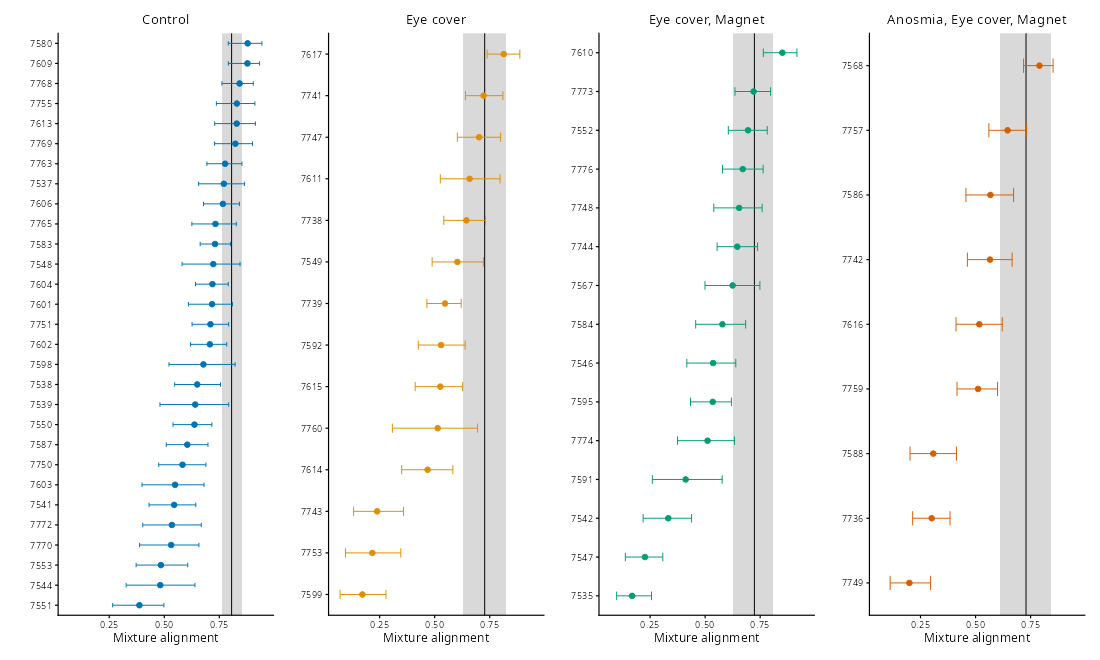

In [49]:
save_figure(tag_hdi_plot("align0", "Alignment", xlimits = c(0, 1)), "fullmodel_taglevel_alignment_to_zero_by_treatment_mean_hdi", 10, 6)


### Posterior predictive checks

The posterior predictive checks (population and individual) resample / bootstrap the goal-relative headings under the vMU and compare them to the observed, per treatment and per animal.


In [50]:
# Full budgets reproduce the source's local bootstrap/draw budgets.
N_WORKERS <- min(8L, max(2L, parallel::detectCores()))
# The per-treatment and per-tag blocks below are independent and run
# forked in parallel: per-task results are reproducible (per-tag
# tasks set their own seed; per-treatment tasks inherit one common
# stream state).
N_BOOT_OBS <- if (quick_run) 150L else 1000L
N_PPC_DRAWS <- if (quick_run) 150L else 4000L
N_INDIV_BOOT <- if (quick_run) 100L else 500L
N_INDIV_DRAWS <- if (quick_run) 100L else 500L
THETA_N <- 360L
angles <- seq(0, 2 * pi, length.out = THETA_N + 1L)[-(THETA_N + 1L)]
bins <- seq(-pi, pi, length.out = 17)
bin_centers <- (head(bins, -1) + tail(bins, -1)) / 2
hist_pdf <- function(y) hist(wrap(y), breaks = bins, plot = FALSE)$density
set.seed(123)
nd <- posterior::ndraws(posterior::as_draws_array(fit_mix))
ppc_ids <- sample.int(nd, min(nd, max(N_PPC_DRAWS, N_INDIV_DRAWS)))
ppc_par <- response_parameters(fit_mix, tag_grid, mixture = TRUE, draw_ids = ppc_ids)
tag_rows <- split(seq_len(nrow(df_track)), df_track$tag)
stopifnot(identical(names(tag_rows), as.character(tag_grid$tag)))
sim_one_tag <- function(j, d) {
  n <- length(tag_rows[[j]])
  goal <- runif(n) < ppc_par$p[j, d]
  # One n-draw call per component: the draw stream of each call matches
  # the n-scalar-call stream exactly (probed), at a large constant-factor
  # speedup. The two pools are drawn separately rather than interleaved
  # row by row, so replicated steps here are stream-different (though
  # distribution-identical) to the earlier interleaved version.
  gd <- as.numeric(circular::rvonmises(n, vmu(ppc_par$mu[j, d]),
    ppc_par$kappa[j, d], control.circular = vm_ctrl))
  fd <- as.numeric(circular::rvonmises(n, vmu(0), KAPPA_UNIFORM,
    control.circular = vm_ctrl))
  wrap(ifelse(goal, gd, fd))
}
hier_y <- function(ys) {
  selected <- sample.int(length(ys), length(ys), replace = TRUE)
  unlist(lapply(selected, function(j) {
    y <- ys[[j]]
    y[sample.int(length(y), length(y), replace = TRUE)]
  }), use.names = FALSE)
}
band_table <- function(draws, x, treatment, source, kind, equal_tail = FALSE) {
  # draws are [grid x draws]; summarize each grid row independently.
  bounds <- if (equal_tail) t(apply(draws, 1, quantile, probs = c(0.025, 0.975))) else t(apply(draws, 1, hdi))
  data.frame(x = x, median = apply(draws, 1, median), low = bounds[, 1],
    high = bounds[, 2], treatment = treatment, source = source, kind = kind)
}
population_ppc <- do.call(rbind, parallel::mclapply(levels(df_track$treatment), function(t) {
  jj <- which(tag_grid$treatment == t)
  observed <- lapply(jj, function(j) df_track$HeadingRadians[tag_rows[[j]]])
  obs_kde <- obs_hist <- pred_kde <- pred_hist <- NULL
  for (b in seq_len(N_BOOT_OBS)) {
    y <- hier_y(observed)
    obs_kde <- cbind(obs_kde, kde_vm(y, angles, 30))
    obs_hist <- cbind(obs_hist, hist_pdf(y))
  }
  for (d in seq_len(min(N_PPC_DRAWS, ncol(ppc_par$mu)))) {
    replicated <- lapply(jj, function(j) sim_one_tag(j, d))
    y <- hier_y(replicated)
    pred_kde <- cbind(pred_kde, kde_vm(y, angles, 30))
    pred_hist <- cbind(pred_hist, hist_pdf(y))
  }
  rbind(band_table(obs_kde, angles, t, "observed bootstrap", "KDE"),
    band_table(pred_kde, angles, t, "posterior predictive", "KDE"),
    band_table(obs_hist, bin_centers, t, "observed bootstrap", "histogram"),
    band_table(pred_hist, bin_centers, t, "posterior predictive", "histogram"))
}, mc.cores = N_WORKERS))
population_ppc$treatment <- factor(population_ppc$treatment, levels = 1:4)
# Polar population PPC, one panel per treatment (Python twin look): 0 deg
# at top, clockwise; edge ring at r = 0.55 (density 0); observed headings
# black dashed with a 95% HDI band; posterior-predictive headings in the
# treatment's colorblind colour with a band; Data/Model legend at the
# bottom. The histogram rows stay in the table; the figure shows KDE
# bands only, as in the Python twin.
ppc_plot <- population_ppc[population_ppc$kind == "KDE", , drop = FALSE]
ppc_plot$key <- ifelse(ppc_plot$source == "observed bootstrap", "Data", "Model")
# Facet titles mirror the Python twin's format_treatment_title: comma
# parts stay in source order, Control is dropped from mixed names, and
# every word is initial-cased.
treat_title_part <- function(pp) {
  ws <- strsplit(tolower(pp), " ", fixed = TRUE)[[1]]
  ws <- ws[ws != ""]
  paste0(toupper(substring(ws, 1L, 1L)), substring(ws, 2L), collapse = " ")
}
treat_title <- function(code) {
  nm <- treatment_labels[as.character(code)]
  if (is.na(nm)) nm <- as.character(code)
  nm <- trimws(nm)
  if (!nzchar(nm)) return(as.character(code))
  parts <- trimws(unlist(strsplit(nm, ",", fixed = TRUE)))
  parts <- parts[nzchar(parts)]
  if (length(parts) > 1L) parts <- parts[tolower(parts) != "control"]
  if (!length(parts)) return(as.character(code))
  paste(vapply(parts, treat_title_part, character(1)), collapse = ", ")
}
tlabel_vec <- vapply(as.character(levels(df_track$treatment)), treat_title,
  character(1))
ppc_plot$tlabel <- factor(tlabel_vec[as.character(ppc_plot$treatment)],
  levels = tlabel_vec)
edge_ppc <- 0.55
amp_ppc <- 0.5
rmax_ppc <- edge_ppc + amp_ppc * 1.15
ppc_plot$ymed <- pmin(edge_ppc + ppc_plot$median, rmax_ppc)
ppc_plot$ylow <- pmin(edge_ppc + ppc_plot$low, rmax_ppc)
ppc_plot$yhi <- pmin(edge_ppc + ppc_plot$high, rmax_ppc)
polar_ring360 <- function(r) {
  a <- seq(0, 2 * pi, length.out = 361L)
  data.frame(x = a, y = r)
}
# The model rows carry their treatment's colorblind colour through the
# treatment code; the data rows carry "Data" (black). The colour and
# fill maps are therefore named identically to the data, stay hidden
# from the legend, and the legend shows the Data/Model line styles.
ppc_plot$cmap <- ifelse(ppc_plot$key == "Data", "Data",
  as.character(ppc_plot$treatment))
tcol_pop <- c(Data = "black", setNames(treatment_colors_cb[
  levels(df_track$treatment)], as.character(levels(df_track$treatment))))
ppc_obs <- ppc_plot[ppc_plot$source == "observed bootstrap", , drop = FALSE]
ppc_mod <- ppc_plot[ppc_plot$source == "posterior predictive", , drop = FALSE]
p_population_ppc <- ggplot(ppc_plot, aes(x, ymed)) +
  geom_ribbon(aes(ymin = ylow, ymax = yhi, group = interaction(key, tlabel),
    fill = cmap), alpha = 0.25, colour = NA) +
  geom_line(data = ppc_obs, aes(group = interaction(key, tlabel),
    linetype = key), colour = "black", linewidth = 0.3) +
  geom_line(data = ppc_mod, aes(group = interaction(key, tlabel),
    linetype = key, colour = cmap), linewidth = 0.3) +
  geom_path(data = polar_ring360(edge_ppc), inherit.aes = FALSE, aes(x, y),
    colour = "#595959", linewidth = 0.25) +
  geom_path(data = polar_ring360(edge_ppc + amp_ppc), inherit.aes = FALSE, aes(x, y),
    colour = "#d9d9d9", linewidth = 0.25) +
  geom_path(data = data.frame(x = c(0, 0), y = c(edge_ppc, edge_ppc + amp_ppc)),
    inherit.aes = FALSE, aes(x, y), colour = "#d9d9d9", linewidth = 0.3) +
  annotate("text", x = 0, y = edge_ppc + amp_ppc + 0.035,
    label = "0\u00b0", size = 2.0) +
  facet_wrap(~ tlabel, ncol = 4) +
  scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0),
    breaks = 0, labels = "0°") +
  coord_polar() +
  scale_y_continuous(limits = c(0, rmax_ppc), expand = c(0, 0)) +
  scale_colour_manual(values = tcol_pop, name = NULL, guide = "none") +
  scale_fill_manual(values = tcol_pop, name = NULL, guide = "none") +
  scale_linetype_manual(values = c(Data = "dashed", Model = "solid"), name = NULL) +
  theme_minimal(base_size = 9) +
  theme(axis.line = element_blank(), axis.ticks = element_blank(),
    axis.text.y = element_blank(),
    axis.text.x = element_text(size = 6, colour = "grey25"),
    panel.grid = element_blank(), panel.border = element_blank(),
    strip.background = element_blank(), strip.text = element_text(size = 9),
    legend.position = "bottom", legend.background = element_rect(
      fill = "white", colour = "grey60"),
    legend.key = element_blank(), legend.text = element_text(size = 8)) +
  labs(x = "", y = "")

individual_ppc <- do.call(rbind, parallel::mclapply(seq_along(tag_rows), function(j) {
  set.seed(10000L + j - 1L)
  y <- df_track$HeadingRadians[tag_rows[[j]]]
  observed <- replicate(N_INDIV_BOOT, {
    boot <- y[sample.int(length(y), length(y), replace = TRUE)]
    kde_vm(boot, angles, 15)
  })
  predicted <- vapply(seq_len(min(N_INDIV_DRAWS, ncol(ppc_par$mu))),
    function(d) kde_vm(sim_one_tag(j, d), angles, 15), numeric(length(angles)))
  z <- rbind(band_table(observed, angles, tag_grid$treatment[j], "observed bootstrap", "KDE", TRUE),
    band_table(predicted, angles, tag_grid$treatment[j], "posterior predictive", "KDE", TRUE))
  z$tag <- as.character(tag_grid$tag[j])
  z
}, mc.cores = N_WORKERS))
# Per-tag polar PPC grid (Python twin look): 8 columns, 0 deg at top and
# clockwise, only the 0-deg label, two grey rings and a 0-deg spoke;
# observed bootstrap black dashed + grey band, posterior-predictive in the
# tag's treatment colour (colorblind) + band; bold tag titles; legend with
# Data/Model plus the named treatments.
ind_edge <- 0.55
ind_rmax <- ind_edge + 1.01
ind <- individual_ppc
# Twin panel order: treatment blocks (sorted treatment code), tags
# ascending within each block; the stable-sorted twin order is the one the
# grid reads off.
ind$taglabel <- as.character(ind$tag)
tags_by_treatment <- unlist(Map(
  function(t) {
    z <- as.character(tag_grid$tag[as.character(tag_grid$treatment) == t])
    z[order(as.numeric(z))]
  },
  levels(df_track$treatment)))
ind$taglabel <- factor(ind$taglabel,
  levels = intersect(unique(tags_by_treatment), unique(ind$taglabel)))
titlecase_t <- function(s) {
  parts <- strsplit(tolower(s), " ", fixed = TRUE)[[1]]
  paste0(toupper(substring(parts, 1L, 1L)), substring(parts, 2L),
    collapse = " ")
}
# The factor level names double as the display labels: manual scales
# match the data by level name, so the values and the scale keys must
# be byte-identical.
key_treat <- vapply(tnames, titlecase_t, character(1))
ind$key <- ifelse(ind$source == "observed bootstrap", "Data",
  key_treat[match(as.character(ind$treatment), levels(df_track$treatment))])
ind$key <- factor(ind$key, levels = c("Data", "Model", key_treat))
ind$fcol <- ifelse(ind$source == "observed bootstrap", "grey20",
  treatment_colors_cb[as.character(ind$treatment)])
# Peak normalization follows the Python twin: radius = 0.55 + 1 *
# d/peak_max, where peak_max is the maximum of all per-tag 95% band
# peaks, so the twin's 1.56 outer limit is preserved.
peak_max_ind <- max(ind$high)
ind$ymed <- pmin(ind_edge + ind$median / peak_max_ind, ind_rmax)
ind$ylow <- pmin(ind_edge + ind$low / peak_max_ind, ind_rmax)
ind$yhi <- pmin(ind_edge + ind$high / peak_max_ind, ind_rmax)
ind_obs <- ind[ind$source == "observed bootstrap", , drop = FALSE]
ind_ppc <- ind[ind$source == "posterior predictive", , drop = FALSE]
p_individual_ppc <- ggplot(ind, aes(x, ymed)) +
  geom_ribbon(data = ind_obs, aes(ymin = ylow, ymax = yhi, group = tag),
    fill = "grey20", alpha = 0.18, colour = NA) +
  geom_ribbon(data = ind_ppc, aes(ymin = ylow, ymax = yhi, group = tag),
    fill = ind_ppc$fcol, alpha = 0.28, colour = NA) +
  geom_line(data = ind_obs, aes(group = tag), colour = "grey5",
    linetype = "dashed", linewidth = 0.3) +
  geom_line(data = ind_ppc, aes(group = tag, colour = key, linetype = key),
    linewidth = 0.4) +
  geom_path(data = polar_ring360(ind_edge), inherit.aes = FALSE, aes(x, y),
    colour = "#cccccc", linewidth = 0.2) +
  geom_path(data = polar_ring360(ind_edge + 0.5), inherit.aes = FALSE, aes(x, y),
    colour = "#dbdbdb", linewidth = 0.2) +
  geom_path(data = data.frame(x = c(0, 0), y = c(ind_edge, ind_rmax)),
    inherit.aes = FALSE, aes(x, y), colour = "#d9d9d9", linewidth = 0.3) +
  facet_wrap(~ taglabel, ncol = 8) +
  scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0),
    breaks = 0, labels = "0°") +
  coord_polar() +
  scale_y_continuous(limits = c(0, ind_rmax), expand = c(0, 0)) +
  scale_colour_manual(values = c(Data = "black", Model = "black",
    setNames(treatment_colors_cb[levels(df_track$treatment)], key_treat)), name = NULL) +
  scale_linetype_manual(values = c(Data = "dashed", Model = "solid",
    setNames(rep("solid", length(tnames)), key_treat))) +
  theme_minimal(base_size = 9) +
  theme(axis.line = element_blank(), axis.ticks = element_blank(),
    axis.text.y = element_blank(),
    axis.text.x = element_text(size = 6, colour = "grey25"),
    panel.grid = element_blank(), panel.border = element_blank(),
    strip.background = element_blank(),
    strip.text = element_text(size = 7, face = "bold"),
    legend.position = "none") +
  labs(x = "", y = "")

# One framed legend row under the grid (the twin of the shared Python
# fig.legend): Data (dashed), Model (solid) and the named treatments in
# one row, sized against the 6.9 in page width.
# Legend labels mirror the Python twin's format_treatment_nicely:
# every word initial-cased, empty names read as Control.
leg_treat <- vapply(tnames, function(nm) {
  nm <- trimws(as.character(nm))
  if (!nzchar(nm)) return("Control")
  titlecase_t(nm)
}, character(1))
leg_items <- data.frame(
  label = c("Data", "Model", leg_treat),
  colour = c("black", "black",
    as.character(treatment_colors_cb[levels(df_track$treatment)])),
  dashed = c(TRUE, FALSE, rep(FALSE, length(tnames))),
  stringsAsFactors = FALSE)
key_in <- 0.18; gkt_in <- 0.06; gi_in <- 0.14
# strwidth measures at the default 12 pt; scale to the 8 pt glyphs.
tw_in <- strwidth(leg_items$label, units = "inches") * (8 / 12)
tot_in <- sum(tw_in) + nrow(leg_items) * (key_in + gkt_in) +
  (nrow(leg_items) - 1) * gi_in
starts_in <- (6.9 - tot_in) / 2 +
  cumsum(c(0, key_in + gkt_in + tw_in[-nrow(leg_items)] + gi_in))
leg_kids <- list(grid::rectGrob(x = unit(0.5, "npc"), y = unit(0.5, "npc"),
  width = unit(1, "npc"), height = unit(1, "npc"), hjust = 0.5, vjust = 0.5,
  gp = grid::gpar(fill = "white", col = "grey60", lwd = 0.3)))
for (i in seq_len(nrow(leg_items))) {
  it <- leg_items[i, ]
  xs <- starts_in[i]
  leg_kids <- c(leg_kids, list(
    grid::segmentsGrob(x0 = unit(xs, "inches"), y0 = unit(0.5, "npc"),
      x1 = unit(xs + key_in, "inches"), y1 = unit(0.5, "npc"),
      default.units = "mixed",
      gp = grid::gpar(col = it$colour, lwd = 1.1,
        lty = if (it$dashed) "dashed" else "solid")),
    grid::textGrob(it$label, x = unit(xs + key_in + gkt_in, "inches"),
      y = unit(0.5, "npc"), just = "left",
      gp = grid::gpar(fontsize = 8))))
}
leg_grob <- grid::gTree(children = do.call(grid::gList, leg_kids))
base_ppc_grob <- ggplotGrob(p_individual_ppc)
base_rows <- max(base_ppc_grob$layout$b)
gt_ind <- gtable::gtable_add_rows(base_ppc_grob,
  heights = unit(0.5, "in"), pos = base_rows + 1)
gt_ind <- gtable::gtable_add_grob(gt_ind, leg_grob, t = base_rows + 1,
  l = 1, r = max(base_ppc_grob$layout$r))
p_individual_ppc <- gt_ind


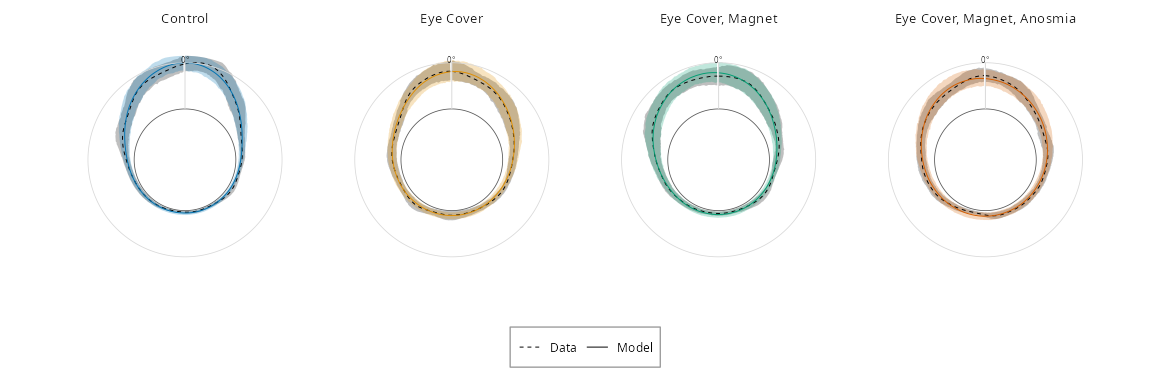

In [51]:
save_figure(p_population_ppc, "bat_population_ppc_by_treatment", 10.5, 3.4)


Individual PPC: bootstrap vs posterior KDE of the goal-directed component per animal.

These figures (and the trajectory maps above) use free CARTO basemaps; when no API key is set they fall back to a flat neutral cartographic style, so the animal positions and flight segments still read cleanly offline.


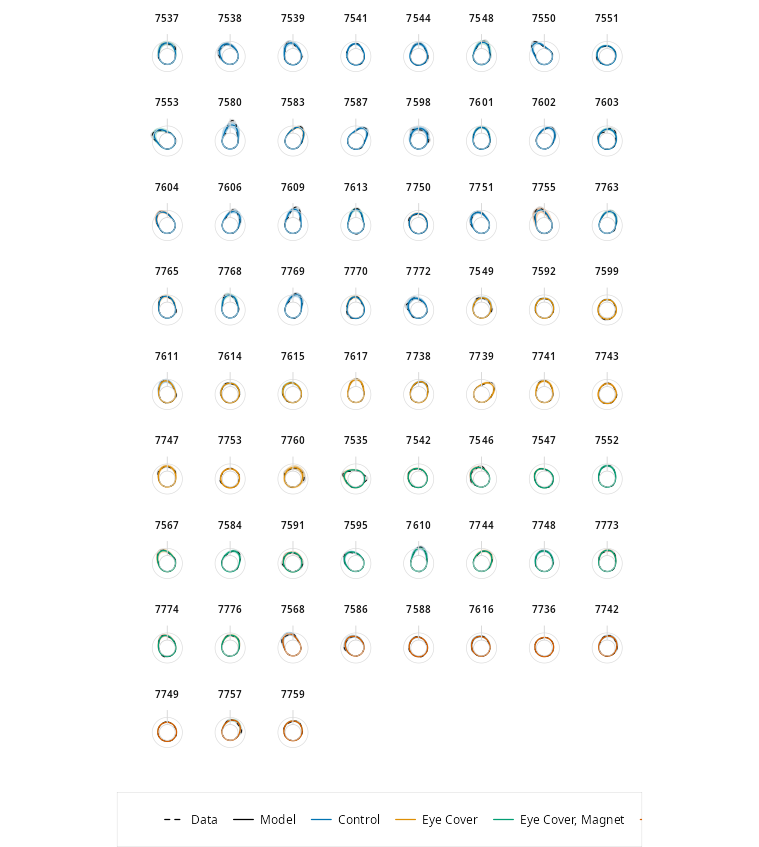

In [52]:
save_figure(p_individual_ppc, "bat_individual_ppc_bootstrap_vs_ppc_kde", 6.9, 7.7)


## 9. Goal-directedness along the trajectory

Posterior probability that each step belongs to the **directed (goal-seeking) component**
($p_{goal}$), plotted along each trajectory (by distance / progress toward the goal). Directedness is
expected to be lower early in a flight (localization / exploration) and higher near the endpoint
(homing).


In [53]:
set.seed(123)
RESP_DRAWS <- if (quick_run) 200L else 2000L
resp_ids <- sample.int(nd, min(nd, RESP_DRAWS))
resp <- matrix(NA_real_, nrow = nrow(df_track), ncol = length(resp_ids))
for (start in seq.int(1L, nrow(df_track), by = 128L)) {
  ii <- seq.int(start, min(start + 127L, nrow(df_track)))
  par <- response_parameters(fit_mix, df_track[ii, ], mixture = TRUE, draw_ids = resp_ids)
  y <- matrix(rep(df_track$HeadingRadians[ii], length(resp_ids)), nrow = length(ii))
  log_goal <- vm_logpdf(y, par$mu, par$kappa)
  # Match the effective append_pgoal_post_to_df helper called by c94/c99:
  # a near-uniform VM proxy and probability-space posterior summaries.
  w <- pmin(1 - 1e-12, pmax(1e-12, par$p))
  log_flat <- vm_logpdf(y, 0, KAPPA_UNIFORM)
  resp[ii, ] <- plogis(qlogis(w) + log_goal - log_flat)
}
stopifnot(all(is.finite(resp)), all(resp >= 0 & resp <= 1))
# The earlier unused helper has a different logit-space convention; use
# the later effective helper that the Python notebook actually calls.
df_track$p_goal_post_mean <- rowMeans(resp)
resp_hdi <- t(apply(resp, 1, hdi))
df_track$p_goal_post_lo <- resp_hdi[, 1]
df_track$p_goal_post_hi <- resp_hdi[, 2]
# The maps' source joins by per-tag step index; join by (tag,time) here to
# avoid shifting probabilities at rows removed from the modeling table.
key <- function(tag, time) paste(tag, sprintf("%.12f", time), sep = ":")
stopifnot(!anyDuplicated(key(track_w_treat$tag, track_w_treat$time)))
track_w_treat$p_pg <- NA_real_
j <- match(key(track_w_treat$tag, track_w_treat$time), key(df_track$tag, df_track$time))
ok <- !is.na(j)
if (!any(ok)) stop("p_goal overlay: no map points matched the modeling table (key-format bug?)")
track_w_treat$p_pg[ok] <- df_track$p_goal_post_mean[j[ok]]
cat("p_goal overlay: ", sum(ok), " of ", length(j), " map points matched the modeling table\n")
segs_pg <- segments_3857(track_w_treat, pcol = "p_pg")
segs_pg <- segs_pg[is.finite(segs_pg$p), , drop = FALSE]
segs_pg$p <- pmin(1, pmax(0, segs_pg$p))
ext_pg <- map_extent(c(list(seg_bounds(segs_pg)), site_bounds), pad = 0.06)


p_goal overlay:  4942  of  5072  map points matched the modeling table


Basemap: flat-panel fallback (no UNWRAP_CARTO_API_KEY set).


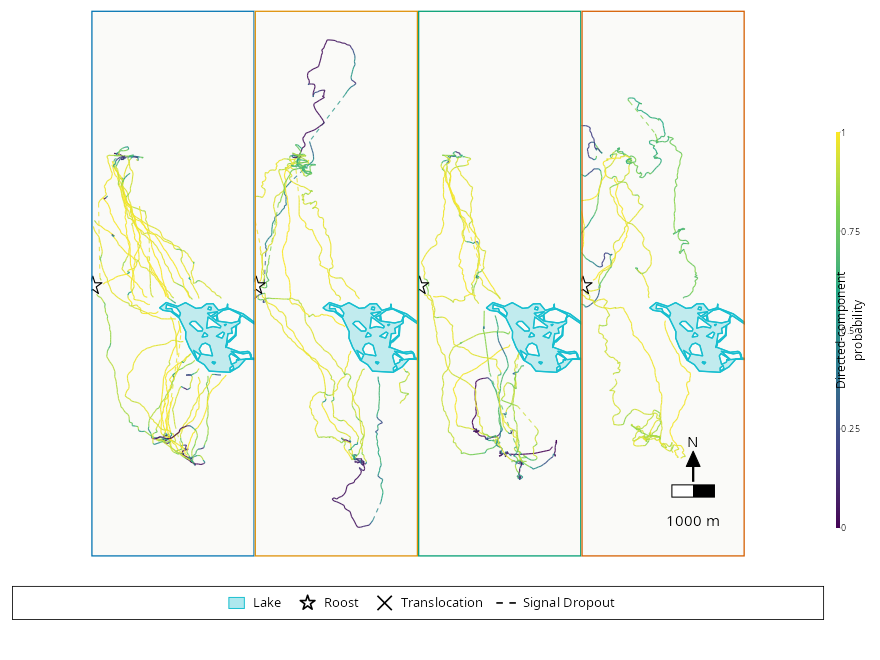

In [54]:
# Tracks colored by the per-step goal-directed probability (viridis),
# one panel per treatment on light CartoDB Positron tiles with colored
# panel borders, scale + compass on the rightmost panel, a thin right-
# side colourbar and the bottom figure legend - the Python p_goal twin.
bm_pg <- basemap_panel_img(ext_pg["xmin"], ext_pg["ymin"],
  ext_pg["xmax"], ext_pg["ymax"], "light_all", 15, "#fafaf8")
# The equal-aspect subplot boxes of the 8x6 figure are ~1.67 x 5.58 in.
ae_pg <- aspect_extent(bm_pg, 1.67 / 5.58)
xlim_pg <- ae_pg$xlim; ylim_pg <- ae_pg$ylim
r_roost_p <- marker_radius_m(200, 1.67, diff(xlim_pg))
r_trans_p <- marker_radius_m(120, 1.67, diff(xlim_pg))

panel_pg <- function(tt, border_col) {
  sd <- segs_pg[as.character(segs_pg$treatment) == tt, , drop = FALSE]
  # Border as a data-level rect added LAST: the flat basemap cover would
  # otherwise swallow half of a theme-drawn panel border.
  p <- map_panel(bm_pg, aspect = 1.67 / 5.58,
    lake = TRUE, lake_alpha = 0.25, lake_lw = 1.0)
  p +
    geom_segment(data = sd[sd$gap, ], inherit.aes = FALSE,
      aes(x = x, y = y, xend = xend, yend = yend, colour = p),
      linetype = "dashed", linewidth = 0.95 * 0.3528, alpha = 0.80) +
    geom_segment(data = sd[!sd$gap, ], inherit.aes = FALSE,
      aes(x = x, y = y, xend = xend, yend = yend, colour = p),
      linewidth = 1.0 * 0.3528, alpha = 0.92) +
    scale_colour_viridis_c(limits = c(0, 1)) +
    guides(colour = "none") +
    add_roost_marker(r_roost_p) +
    add_x_markers(TRANS_XY, r_trans_p) +
    geom_rect(inherit.aes = FALSE,
      data = data.frame(xmin = xlim_pg[1], xmax = xlim_pg[2],
        ymin = ylim_pg[1], ymax = ylim_pg[2]),
      aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
      fill = NA, colour = border_col, linewidth = 0.78)
}
p_pg_1 <- panel_pg("1", treatment_colors_cb["1"])
p_pg_2 <- panel_pg("2", treatment_colors_cb["2"])
p_pg_3 <- panel_pg("3", treatment_colors_cb["3"])
p_pg_4 <- panel_pg("4", treatment_colors_cb["4"])
p_pg_4 <- add_scale_compass(p_pg_4, xlim_pg, ylim_pg,
  variant = "pgoal", panel_w_in = 1.48, panel_h_in = 4.95)
# Thin vertical colourbar (Python: figure axes [0.922, 0.20, 0.012,
# 0.62], label "Directed-component probability").
pb <- seq_len(240)
cbar_rows <- data.frame(x = 0.30, y = 0.19 + 0.62 * (pb - 0.5) / 240,
  v = (pb - 0.5) / 240)
p_cbar <- ggplot(cbar_rows, aes(x, y, fill = v)) +
  geom_tile(width = 0.13, height = 0.62 / 240) +
  scale_fill_viridis_c(limits = c(0, 1)) +
  scale_x_continuous(limits = c(0, 1.35), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, 1), expand = c(0, 0))
for (v in seq(0, 1, by = 0.2)) {
  yv <- 0.19 + 0.62 * v
  p_cbar <- p_cbar +
    annotate("segment", x = 0.375, y = yv, xend = 0.40, yend = yv,
      linewidth = 0.15, colour = "#000000") +
    annotate("text", x = 0.42, y = yv, label = sprintf("%.1f", v),
      size = 2.2, hjust = 0, vjust = 0.5)
}
p_cbar <- p_cbar +
  annotate("text", x = 1.10, y = 0.5,
    label = "Directed-component probability", size = 2.8, angle = 90,
    hjust = 0.5, vjust = 0.5) +
  theme_void() +
  guides(fill = "none")
p_pg_legend <- legend_panel(data.frame(
  kind = c("swatch", "star", "x", "dash"),
  label = c("Lake", "Roost", "Translocation", "Signal Dropout")),
  cell_w = 7.4, cell_h = 0.84)
p_prob_top <- (p_pg_1 | p_pg_2 | p_pg_3 | p_pg_4) / p_pg_legend
p_prob_top <- p_prob_top + plot_layout(heights = c(1, 0.17))
p_probability_map <- p_prob_top | p_cbar
p_probability_map <- p_probability_map +
  plot_layout(widths = c(1, 0.09)) +
  theme(plot.margin = margin(1, 1, 1, 1))
save_figure(p_probability_map, "treatment_panels_tracks_pgoal", width = 8, height = 6)


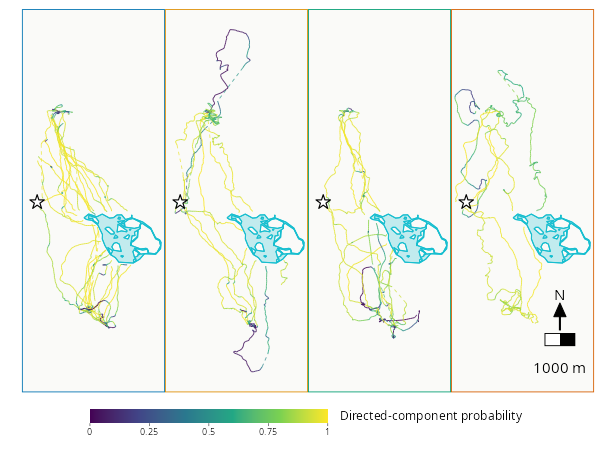

In [55]:
# Compact p_goal tracks: smaller figure, the same four treatment panels,
# a wide horizontal colourbar below (no legend) - the Python
# small-fig / bigger-font p_goal twin.
ae_pg_s <- aspect_extent(bm_pg, 1.34 / 3.59)
xlim_pg_s <- ae_pg_s$xlim; ylim_pg_s <- ae_pg_s$ylim
r_roost_ps <- marker_radius_m(105, 1.34, diff(xlim_pg_s))
r_trans_ps <- marker_radius_m(62, 1.34, diff(xlim_pg_s))

panel_pg_s <- function(tt, border_col) {
  sd <- segs_pg[as.character(segs_pg$treatment) == tt, , drop = FALSE]
  # Border as a data-level rect added LAST (see panel_pg above).
  map_panel(bm_pg, aspect = 1.34 / 3.59,
    lake = TRUE, lake_alpha = 0.25, lake_lw = 0.8) +
    geom_segment(data = sd[sd$gap, ], inherit.aes = FALSE,
      aes(x = x, y = y, xend = xend, yend = yend, colour = p),
      linetype = "dashed", linewidth = 0.76 * 0.3528, alpha = 0.75) +
    geom_segment(data = sd[!sd$gap, ], inherit.aes = FALSE,
      aes(x = x, y = y, xend = xend, yend = yend, colour = p),
      linewidth = 0.8 * 0.3528, alpha = 0.90) +
    scale_colour_viridis_c(limits = c(0, 1)) +
    guides(colour = "none") +
    add_roost_marker(r_roost_ps) +
    add_x_markers(TRANS_XY, r_trans_ps) +
    geom_rect(inherit.aes = FALSE,
      data = data.frame(xmin = xlim_pg_s[1], xmax = xlim_pg_s[2],
        ymin = ylim_pg_s[1], ymax = ylim_pg_s[2]),
      aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
      fill = NA, colour = border_col, linewidth = 0.53)
}
p_pgs_1 <- panel_pg_s("1", treatment_colors_cb["1"])
p_pgs_2 <- panel_pg_s("2", treatment_colors_cb["2"])
p_pgs_3 <- panel_pg_s("3", treatment_colors_cb["3"])
p_pgs_4 <- panel_pg_s("4", treatment_colors_cb["4"])
p_pgs_4 <- add_scale_compass(p_pgs_4, xlim_pg_s, ylim_pg_s,
  variant = "pgoal_small", panel_w_in = 1.33, panel_h_in = 3.49)
# Wide horizontal colourbar (Python: figure axes [0.20, 0.060, 0.60,
# 0.034]).
pb <- seq_len(240)
cbar_h_rows <- data.frame(x = 0.20 + 0.60 * (pb - 0.5) / 240, y = 0.62,
  v = (pb - 0.5) / 240)
p_cbar_h <- ggplot(cbar_h_rows, aes(x, y, fill = v)) +
  geom_tile(width = 0.60 / 240, height = 0.24) +
  scale_fill_viridis_c(limits = c(0, 1)) +
  scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, 1), expand = c(0, 0))
for (v in seq(0, 1, by = 0.2)) {
  xv <- 0.20 + 0.60 * v
  p_cbar_h <- p_cbar_h +
    annotate("segment", x = xv, y = 0.49, xend = xv, yend = 0.44,
      linewidth = 0.15, colour = "#000000") +
    annotate("text", x = xv, y = 0.40, label = sprintf("%.1f", v),
      size = 2.2, hjust = 0.5, vjust = 1)
}
p_cbar_h <- p_cbar_h +
  annotate("text", x = 0.5, y = 0.05,
    label = "Directed-component probability", size = 2.8, hjust = 0.5,
    vjust = 0) +
  theme_void() +
  guides(fill = "none")
p_prob_top_s <- (p_pgs_1 | p_pgs_2 | p_pgs_3 | p_pgs_4) / p_cbar_h
p_prob_top_s <- p_prob_top_s + plot_layout(heights = c(1, 0.15))
p_probability_map_small <- p_prob_top_s +
  theme(plot.margin = margin(1, 1, 1, 1))
save_figure(p_probability_map_small, "treatment_panels_tracks_pgoal_small_bigfont",
  width = 5.6, height = 4.2)


Population-level $p_{goal}$ as a function of distance from the flight's endpoint — lower early, higher
as the animal approaches its goal.


In [56]:
# Gaussian smoothing per tag, equal-tag averaging per posterior draw,
# range/weight truncation, and weighted population post-smoothing.
smooth_population <- function(draws, grid, counts, bandwidth = 240) {
  spacing <- median(diff(grid))
  sigma <- bandwidth / spacing
  if (sigma < 0.5) return(draws)
  radius <- ceiling(4 * sigma)
  offsets <- seq.int(-radius, radius)
  kernel <- exp(-0.5 * (offsets / sigma)^2)
  safe <- draws
  safe[!is.finite(safe)] <- 0
  out <- matrix(NA_real_, nrow(draws), ncol(draws))
  for (g in seq_along(grid)) {
    ii <- g + offsets
    valid <- ii >= 1L & ii <= length(grid)
    w <- kernel[valid] * counts[ii[valid]]
    if (sum(w) > 1e-12) out[g, ] <- colSums(safe[ii[valid], , drop = FALSE] * w) / sum(w)
  }
  out
}
summarize_curve <- function(curve, grid, treatment, tag = NA_character_) {
  valid <- rowSums(is.finite(curve)) == ncol(curve)
  if (!any(valid)) return(NULL)
  z <- curve[valid, , drop = FALSE]
  bounds <- t(apply(z, 1, hdi))
  data.frame(x = grid[valid], mean = rowMeans(z), low = bounds[, 1], high = bounds[, 2],
    treatment = treatment, tag = tag)
}
make_curves <- function(kind) {
  x <- df_track$dist_to_dest_grad_m
  if (kind == "steps_from_end") {
    x <- ave(seq_len(nrow(df_track)), df_track$tag,
      FUN = function(ii) (seq_along(ii) - length(ii)) * 60)
  }
  G <- if (quick_run) 400L else 2000L
  population <- individual <- list()
  for (t in levels(df_track$treatment)) {
    eligible <- which(df_track$treatment == t & is.finite(x))
    if (kind == "steps_from_end") eligible <- eligible[x[eligible] >= -110 * 60]
    grid <- seq(min(x[eligible]), max(x[eligible]), length.out = G)
    total <- matrix(0, G, ncol(resp))
    counts <- numeric(G)
    tags <- split(eligible, droplevels(df_track$tag[eligible]))
    for (tag in names(tags)) {
      ii <- tags[[tag]]
      if (length(ii) < 2L) next
      # Explicit [grid x observations] kernel, [grid x draws] prediction.
      weights <- exp(-0.5 * (outer(grid, x[ii], "-") / 120)^2)
      denominator <- rowSums(weights) + 1e-12
      curve <- (weights %*% resp[ii, , drop = FALSE]) / denominator
      valid <- grid >= min(x[ii]) & grid <= max(x[ii]) &
        denominator >= 0.01 * max(denominator)
      total[valid, ] <- total[valid, , drop = FALSE] + curve[valid, , drop = FALSE]
      counts[valid] <- counts[valid] + 1L
      curve[!valid, ] <- NA_real_
      individual[[paste(t, tag)]] <- summarize_curve(curve, grid, t, tag)
    }
    curve <- total / pmax(counts, 1)
    curve[counts < 2L, ] <- NA_real_
    support <- counts
    support[counts < 2L] <- 0
    curve <- smooth_population(curve, grid, support, bandwidth = 240)
    curve[counts < 2L, ] <- NA_real_
    population[[t]] <- summarize_curve(curve, grid, t)
  }
  list(population = do.call(rbind, population), individual = do.call(rbind, individual))
}
distance_curves <- make_curves("distance")
end_curves <- make_curves("steps_from_end")
# Full-size twin (Python plot_population_curve_smooth): colorblind bands
# + lines, dashed 0.5 reference, boxed right legend with formatted
# treatment names, y on [0, 1].
curve_plot_full <- function(curves, reverse = FALSE) {
  x <- curves$population
  x$treatment <- factor(x$treatment, levels = 1:4)
  lv <- levels(x$treatment)
  p <- ggplot(x, aes(x, mean, colour = treatment, fill = treatment,
    group = treatment)) +
    geom_ribbon(aes(ymin = low, ymax = high),
      alpha = 0.20, colour = NA, linewidth = 0) +
    geom_line(linewidth = 0.5) +
    geom_hline(yintercept = 0.5, colour = "grey90", linetype = "dashed", linewidth = 0.3) +
    scale_colour_manual(values = treatment_colors_cb[lv],
      labels = treatment_nice[lv], name = NULL) +
    scale_fill_manual(values = treatment_colors_cb[lv], name = NULL) +
    scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, by = 0.2),
      labels = function(v) sprintf("%.1f", v), expand = c(0, 0.02)) +
    guides(fill = "none") +
    labs(x = if (reverse) "Distance to destination (m)" else "Cumulative path distance from end (m)",
      y = "Mean directed-component probability") +
    theme_classic(base_size = 9) +
    theme(legend.position = "right",
      legend.background = element_rect(fill = "white", colour = "grey30"),
      legend.key = element_blank(),
      legend.text = element_text(size = 8, colour = "black"),
      legend.margin = margin(2, 2, 2, 2, "mm"),
      legend.spacing.y = unit(1.3, "lines"))
  if (reverse) {
    p <- p + scale_x_reverse(labels = function(v) format(v, trim = TRUE, scientific = FALSE))
  } else {
    p <- p + scale_x_continuous(limits = c(-110 * 60, 0),
      labels = function(v) format(abs(v), big.mark = ","))
  }
  p
}
# Compact (paper-width) twin: same curves, no legend, smaller text.
curve_plot_compact <- function(curves, reverse = FALSE) {
  x <- curves$population
  x$treatment <- factor(x$treatment, levels = 1:4)
  lv <- levels(x$treatment)
  p <- ggplot(x, aes(x, mean, colour = treatment, fill = treatment,
    group = treatment)) +
    geom_ribbon(aes(ymin = low, ymax = high),
      alpha = 0.18, colour = NA, linewidth = 0) +
    geom_line(linewidth = 0.45) +
    geom_hline(yintercept = 0.5, colour = "grey88", linetype = "dashed", linewidth = 0.3) +
    scale_colour_manual(values = treatment_colors_cb[lv], name = NULL) +
    scale_fill_manual(values = treatment_colors_cb[lv], name = NULL) +
    scale_y_continuous(limits = c(0, 1), expand = c(0, 0.02)) +
    guides(colour = "none", fill = "none") +
    labs(x = if (reverse) "Distance to destination (m)" else "Cumulative path distance from end (m)",
      y = "Directed-component\nprobability") +
    theme_classic(base_size = 7) +
    theme(legend.position = "none")
  if (reverse) {
    p <- p + scale_x_reverse(labels = function(v) format(v, trim = TRUE, scientific = FALSE))
  } else {
    p <- p + scale_x_continuous(limits = c(-110 * 60, 0),
      labels = function(v) format(abs(v), big.mark = ","))
  }
  p
}
# Per-animal 2x2 grid (Python plot_tag_curves_faceted_4panel): one panel
# per treatment, animals drawn in the treatment color, 0.5 reference,
# absolute comma-formatted ticks, y label only on the left column.
tag_curve_plot <- function(curves, reverse = FALSE) {
  x <- curves$individual
  x$treatment <- factor(x$treatment, levels = 1:4)
  lv <- levels(x$treatment)
  xlabs <- function(v) format(abs(v), big.mark = ",")
  panels <- lapply(seq_along(lv), function(k) {
    t <- lv[k]
    sub <- x[x$treatment == t, ]
    p <- ggplot(sub, aes(x, mean, group = tag)) +
      geom_ribbon(aes(ymin = low, ymax = high),
        fill = treatment_colors_cb[t], alpha = 0.10, colour = NA, linewidth = 0) +
      geom_line(colour = treatment_colors_cb[t], alpha = 0.75, linewidth = 0.35) +
      geom_hline(yintercept = 0.5, colour = "grey90", linetype = "dashed", linewidth = 0.3) +
      scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, by = 0.2),
        labels = function(v) sprintf("%.1f", v), expand = c(0, 0)) +
      labs(title = treatment_nice[[t]],
        x = if (reverse) "Distance to destination (m)" else "Cumulative path distance from end (m)",
        y = if (k == 1L || k == 3L) "Directed-component probability" else "") +
      theme_classic(base_size = 8) +
      theme(plot.title = element_text(size = 9, hjust = 0.5),
        axis.text.y = if (k %% 2L == 0L) element_blank() else element_text())
    if (reverse) {
      p <- p + scale_x_reverse(labels = function(v) format(v, trim = TRUE, scientific = FALSE))
    } else {
      p <- p + scale_x_continuous(limits = c(-110 * 60, 0), labels = xlabs)
    }
    p
  })
  patchwork::wrap_plots(panels[[1]], panels[[2]], panels[[3]], panels[[4]],
    ncol = 2)
}
p_curve_distance <- curve_plot_full(distance_curves, reverse = TRUE)
p_curve_end <- curve_plot_full(end_curves)
p_curve_distance_c <- curve_plot_compact(distance_curves, reverse = TRUE)
p_curve_end_c <- curve_plot_compact(end_curves)
p_tag_distance <- tag_curve_plot(distance_curves, reverse = TRUE)
p_tag_end <- tag_curve_plot(end_curves)


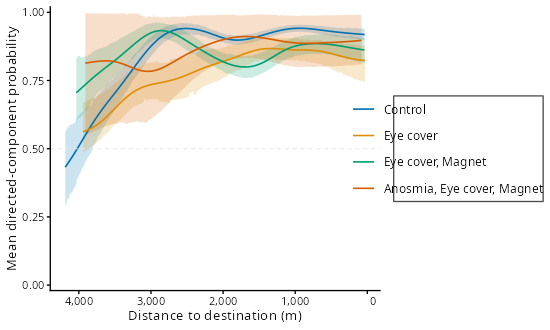

In [57]:
save_figure(p_curve_distance, "p_goal_pop_kernel_distance_TRUNC_SMOOTH", 4.4, 2.6)


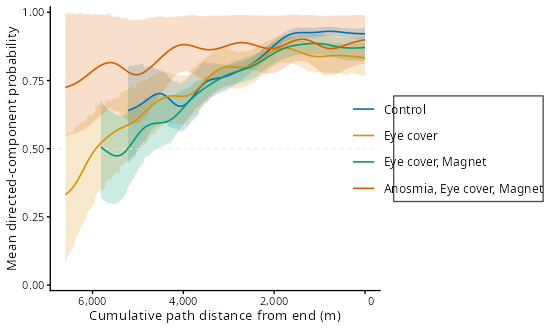

In [58]:
save_figure(p_curve_end, "p_goal_pop_kernel_distFromEndM_TRUNC_SMOOTH", 4.4, 2.6)


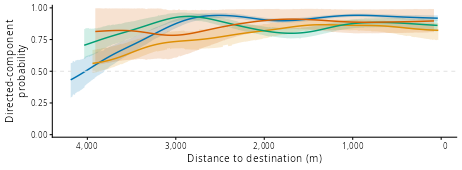

In [59]:
save_figure(p_curve_distance_c, "p_goal_pop_kernel_distance_TRUNC_SMOOTH_compact", 3.4, 1.2)


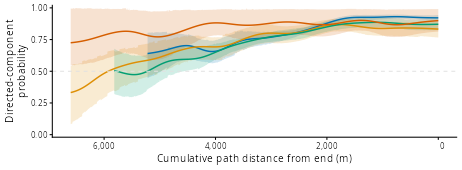

In [60]:
save_figure(p_curve_end_c, "p_goal_pop_kernel_distFromEndM_TRUNC_SMOOTH_compact", 3.4, 1.2)


Per-animal (faceted) $p_{goal}$ along the flight, showing the heterogeneity in when each bat commits
to goal-directed travel.


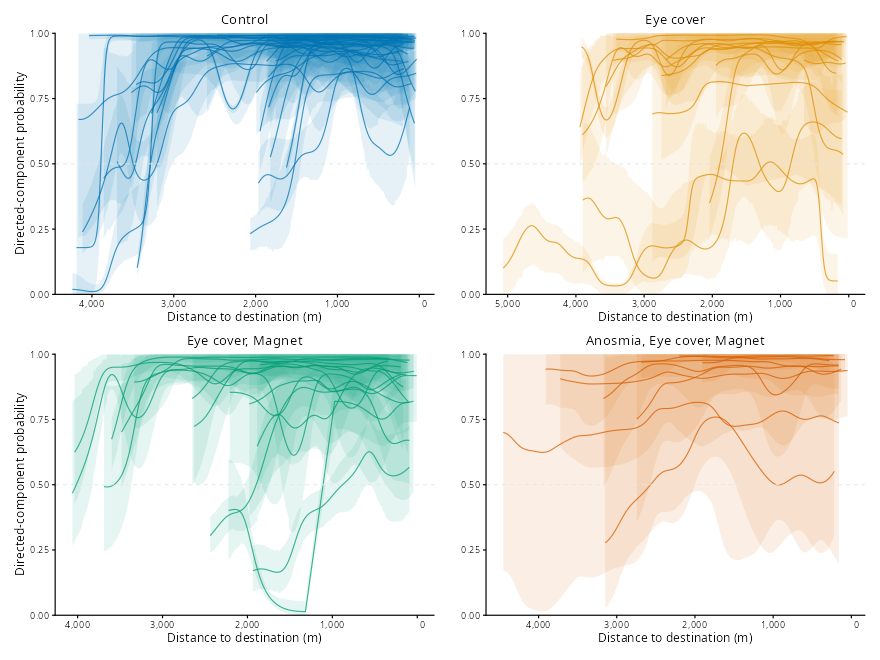

In [61]:
save_figure(p_tag_distance, "p_goal_tag_kernel_distance_faceted_TRUNC", 8, 6)


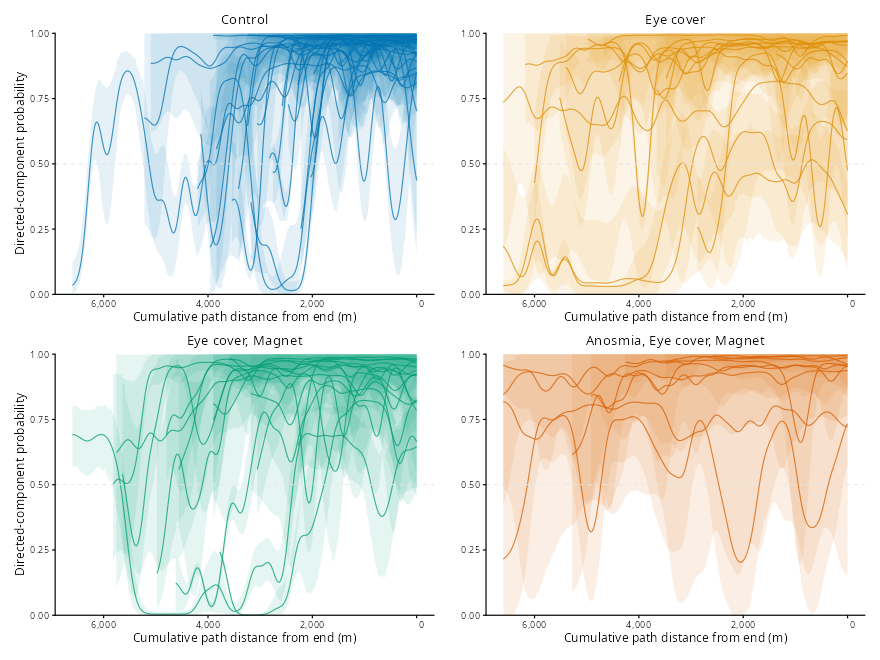

In [62]:
save_figure(p_tag_end, "p_goal_tag_kernel_distFromEndM_faceted_TRUNC", 8, 6)


## Review

The full and quick budgets retain the same data, priors, and model
structure. Review the diagnostic tables and figures above before
interpreting results. The [model guide](../models.md) explains how
direction, precision, and directed-component probability answer
different questions.
